# Old34 comprehensive Stage 2 diagnostic suite

**Purpose.** Create a clean, auditable bridge from the **June 5 old34 biological grid (643 representations)** to (1) an all-representation atlas and (2) a canonical **41-row panel table** for scientific review. D1 additionally joins the July 24 `old34_direct_gene_all_v1` no-DR run (41 biological panels), the September 4 `old34_controls_fullgrid_v1` DR grid (`full_34`, `core_only`, HVG 500/1k/3k/10k), and the September 11 `old34_controls_direct_gene_v1` no-DR LOPO run so those six control rows also have a filled `direct_gene` column.

## Scope and non-scope

- Included: 41 biological Stage 0 panels (34 single gene sets + 7 grouped panels), 640 DR representations + 3 original small-panel direct-gene fallbacks in the June 5 grid, and all three Stage 2 goals on that grid.
- D1 atlas only: replace those 3 fallbacks with the completed 41-panel direct-gene LOPO run (`old34_direct_gene_all_v1`), append the 6 non-geneset Stage 0 controls from `old34_controls_fullgrid_v1` (96 DR representations), then fill their `direct_gene` column from `old34_controls_direct_gene_v1` (6 no-DR LOPO representations). D2/D3 stay on the 643-row June 5 biological table.
- Excluded from D1: HVG 200 (never a Stage 0 panel here), the 15,560-gene `all_filtered_mrd_gene_universe` bag (no full Stage 2), Set B `expanded_full`, pooled unions, matched-random-gene nulls, and Stage 1 seed/inductive sensitivity.
- This notebook **does not rerun Stage 0, Stage 1, or Stage 2**. It consumes completed scorecards and writes compact derived tables/figures.
- The Stage 1 basis was fit on all eligible cells. LOPO therefore measures label transfer on a shared transductive atlas, not fully inductive deployment.

## Why this notebook exists

The V2F suite is computed from the completed 643-row result universe, but most V2F plots intentionally collapse it:

- V2F1: 41 panel summaries (one selected representation per panel)
- V2F2: up to 12 priority panels with method × K curves
- V2F2b/c: a requested 19-panel list, limited to panels present in old34
- V2F3: 41 × 4 panel-method cells (best K annotated)
- V2F4: 41 × patient transfer matrix (one selected representation per panel)
- V2F5: panel-method summaries (one selected K per method)
- V2F6: 41 panel summaries collapsed to biological themes

So the missing object is not another old34 Stage 2 run. It is an explicit **all-representation visual audit** plus a single panel-level table with documented selection rules.

## Manuscript-plot contract

Every candidate plot below records:

1. scientific question;
2. in silico experiment and unit of analysis;
3. result against the patient-specific prevalence baseline;
4. scoped take-home message;
5. null hypothesis and unresolved inferential gaps.

Positive lift is descriptive evidence against the prevalence baseline, **not a p-value**. Matched-size random gene-set controls and uncertainty are still required before a manuscript-level knowledge-prior claim.


In [1]:
from __future__ import annotations

import hashlib
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 100)

EXPERIMENT_ID = "20260525_060508_stage0_mrd_old34_broad_screen_82db5093"


def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "experiments").exists():
            return candidate
    fallback = Path("/home/minhang/mds_project/sc_classification")
    if fallback.exists():
        return fallback
    raise FileNotFoundError("Could not locate the sc_classification repository root")


REPO_ROOT = find_repo_root()
STAGE2_SCRIPT_DIR = REPO_ROOT / "scripts" / "mrd_stage0_2" / "stage2_supervised"
if str(STAGE2_SCRIPT_DIR) not in sys.path:
    sys.path.insert(0, str(STAGE2_SCRIPT_DIR))
from stage2_sharedness_plotting import select_regularization_rows  # noqa: E402

EXP_DIR = REPO_ROOT / "experiments" / EXPERIMENT_ID
SOURCE_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_figure3_sharedness_v2_jun4"
TABLE_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_diagnostic"
FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_PATHS = {
    "decision_643": SOURCE_DIR / "v2_decision_table_discovery_lopo_patient_specific.csv",
    "pooled_selected_representation": SOURCE_DIR / "v2_lopo_metric_comparison_by_panel_method_k.csv",
    "option_b_oracle_representation": SOURCE_DIR / "v2_lopo_patient_lift_summary_best_regularization_by_panel_method_k.csv",
    "patientwise_all_regularization": SOURCE_DIR / "v2_lopo_patient_wise_transfer_by_regularization.csv",
    "patient_specific_scorecard": EXP_DIR / "analysis" / "scorecards" / "stage2_patient_specific_scorecard.csv",
    "panel_stability": SOURCE_DIR / "v2_panel_stage1_stability_summary.csv",
    "panel_method_stability": SOURCE_DIR / "v2_panel_method_stage1_stability_summary.csv",
    "stage0_manifest": EXP_DIR / "preprocessing" / "panels" / "stage0_panel_manifest.csv",
    "direct_lopo_scorecard": EXP_DIR / "analysis" / "scorecards" / "old34_direct_gene_all_v1" / "stage2_sharedness_lopo_scorecard.csv",
    "direct_lopo_by_patient": EXP_DIR / "stage2_supervised" / "multiobjective" / "old34_direct_gene_all_v1" / "sharedness_lopo" / "by_heldout_patient.csv",
    "control_lopo_scorecard": EXP_DIR / "analysis" / "scorecards" / "old34_controls_fullgrid_v1" / "stage2_sharedness_lopo_scorecard.csv",
    "control_lopo_by_patient": EXP_DIR / "stage2_supervised" / "multiobjective" / "old34_controls_fullgrid_v1" / "sharedness_lopo" / "by_heldout_patient.csv",
    "control_direct_lopo_scorecard": EXP_DIR / "analysis" / "scorecards" / "old34_controls_direct_gene_v1" / "stage2_sharedness_lopo_scorecard.csv",
    "control_direct_lopo_by_patient": EXP_DIR / "stage2_supervised" / "multiobjective" / "old34_controls_direct_gene_v1" / "sharedness_lopo" / "by_heldout_patient.csv",
}
missing_sources = [str(path) for path in SOURCE_PATHS.values() if not path.exists()]
assert not missing_sources, f"Missing required source files: {missing_sources}"


def save_figure(fig: plt.Figure, stem: str) -> None:
    png = FIGURE_DIR / f"{stem}.png"
    fig.savefig(png, dpi=220, bbox_inches="tight")
    fig.savefig(png.with_suffix(".pdf"), bbox_inches="tight")
    print(png)


def resolve_representation_row(
    representation: pd.DataFrame,
    *,
    representation_id: str | None = None,
    short_panel_label: str | None = None,
    stage1_method: str | None = None,
    effective_k: int | None = None,
    select: str = "explicit",
) -> pd.Series:
    """Resolve one representation row for concrete lift plotting.

    Selection modes (`select`):
    - ``explicit``: require ``representation_id`` or
      ``short_panel_label`` + ``stage1_method`` + ``effective_k``
    - ``top_pooled_lopo``: highest ``lopo_auprc``, ties broken by ``representation_id``
    """
    table = representation
    if representation_id is not None:
        table = table.loc[table["representation_id"].eq(representation_id)]
    else:
        if short_panel_label is not None:
            table = table.loc[table["short_panel_label"].eq(short_panel_label)]
        if stage1_method is not None:
            table = table.loc[table["stage1_method"].eq(stage1_method)]
        if effective_k is not None:
            table = table.loc[table["effective_k"].astype(int).eq(int(effective_k))]

    if table.empty:
        raise ValueError(
            "No representation matched the requested filters "
            f"(representation_id={representation_id!r}, "
            f"short_panel_label={short_panel_label!r}, "
            f"stage1_method={stage1_method!r}, effective_k={effective_k!r})"
        )

    if select == "top_pooled_lopo":
        return table.sort_values(
            ["lopo_auprc", "representation_id"], ascending=[False, True]
        ).iloc[0]
    if select != "explicit":
        raise ValueError(f"Unknown select mode: {select!r}")
    if len(table) != 1:
        raise ValueError(
            f"Expected exactly one representation after filters, got {len(table)}. "
            "Pass representation_id, or short_panel_label + stage1_method + effective_k, "
            "or select='top_pooled_lopo'."
        )
    return table.iloc[0]


def plot_concrete_patient_lift_example(
    representation: pd.DataFrame,
    selected_patient_long: pd.DataFrame,
    *,
    representation_id: str | None = None,
    short_panel_label: str | None = None,
    stage1_method: str | None = None,
    effective_k: int | None = None,
    select: str = "explicit",
    stem: str | None = None,
    table_stem: str | None = None,
    save: bool = True,
    show: bool = True,
) -> tuple[pd.Series, pd.DataFrame, plt.Figure]:
    """D1d-style two-panel concrete lift plot for one representation.

    Left: patient prevalence vs held-out AUPRC (AUPRC percentage points).
    Right: seven supported-patient lifts ordered, with median and p20.

    Examples
    --------
    plot_concrete_patient_lift_example(
        representation, selected_patient_long, select="top_pooled_lopo"
    )
    plot_concrete_patient_lift_example(
        representation,
        selected_patient_long,
        short_panel_label="innate immune context",
        stage1_method="fa",
        effective_k=40,
    )
    """
    example_representation = resolve_representation_row(
        representation,
        representation_id=representation_id,
        short_panel_label=short_panel_label,
        stage1_method=stage1_method,
        effective_k=effective_k,
        select=select,
    )
    example_patient = selected_patient_long.loc[
        selected_patient_long["representation_id"].eq(
            example_representation["representation_id"]
        )
    ].sort_values("heldout_patient").copy()
    if example_patient.empty:
        raise ValueError(
            "No supported-patient rows for representation_id="
            f"{example_representation['representation_id']!r}"
        )

    example_patient["prevalence_percentage_points"] = (
        100 * example_patient["patient_prevalence"]
    )
    example_patient["auprc_percentage_points"] = 100 * example_patient["heldout_auprc"]
    example_patient["lift_percentage_points"] = 100 * example_patient["heldout_lift"]
    example_median_lift_pp = float(example_patient["lift_percentage_points"].median())
    example_p20_lift_pp = float(example_patient["lift_percentage_points"].quantile(0.20))

    method = str(example_representation["stage1_method"])
    k_value = int(example_representation["effective_k"])
    panel_label = str(example_representation["short_panel_label"])
    if stem is None:
        slug = (
            panel_label.lower()
            .replace(" ", "_")
            .replace("/", "_")
            .replace("|", "_")
        )
        stem = f"D1d_concrete_patient_lift_{slug}_{method}_K{k_value}"

    fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8), constrained_layout=True)
    x = np.arange(len(example_patient))
    width = 0.36
    axes[0].bar(
        x - width / 2,
        example_patient["prevalence_percentage_points"],
        width,
        color="0.70",
        label="malignant prevalence (random AUPRC baseline)",
    )
    axes[0].bar(
        x + width / 2,
        example_patient["auprc_percentage_points"],
        width,
        color="#4472C4",
        label="held-out AUPRC",
    )
    axes[0].set_xticks(x, example_patient["heldout_patient"])
    axes[0].set_ylabel("AUPRC percentage points")
    axes[0].set_title("D1d-a. Subtract each patient's own baseline")
    axes[0].legend(frameon=False, fontsize=8)

    ordered_example = example_patient.sort_values(
        "lift_percentage_points"
    ).reset_index(drop=True)
    axes[1].plot(
        np.arange(1, len(ordered_example) + 1),
        ordered_example["lift_percentage_points"],
        marker="o",
        color="#4472C4",
    )
    for rank, row in enumerate(ordered_example.itertuples(), start=1):
        axes[1].annotate(
            row.heldout_patient,
            (rank, row.lift_percentage_points),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )
    axes[1].axhline(0, color="0.4", lw=1, ls="--", label="prevalence baseline")
    axes[1].axhline(
        example_median_lift_pp,
        color="#D55E00",
        lw=1.5,
        label=f"median = {example_median_lift_pp:.2f} pp",
    )
    axes[1].axhline(
        example_p20_lift_pp,
        color="#009E73",
        lw=1.5,
        label=f"p20 = {example_p20_lift_pp:.2f} pp",
    )
    axes[1].set_xticks(np.arange(1, len(ordered_example) + 1))
    axes[1].set_xlabel("Supported patients ordered by held-out lift")
    axes[1].set_ylabel("Held-out lift (AUPRC percentage points)")
    axes[1].set_title("D1d-b. Median = typical; p20 = lower-tail floor")
    axes[1].legend(frameon=False, fontsize=8)
    fig.suptitle(
        f"Concrete lift example: {panel_label} | {method} K={k_value}",
        fontsize=12,
    )

    if save:
        if table_stem is None:
            table_stem = stem.replace("D1d_concrete_patient_lift_", "old34_lift_concrete_")
        example_patient_path = TABLE_DIR / f"{table_stem}.csv"
        example_patient.to_csv(example_patient_path, index=False)
        print(example_patient_path)
        save_figure(fig, stem)
    if show:
        plt.show()
    return example_representation, example_patient, fig


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("Repository:", REPO_ROOT)
print("Experiment:", EXP_DIR)
print("Derived tables:", TABLE_DIR)

CONTROL_ATLAS_SPECS = [
    {"stage0_panel_id": "full_34", "short_panel_label": "all Stage 0 genesets", "label_includes_n": False},
    {"stage0_panel_id": "core_only", "short_panel_label": "core-only programs", "label_includes_n": False},
    {"stage0_panel_id": "hvg_top_requested_500__available_500", "short_panel_label": "HVGs (500)", "label_includes_n": True},
    {"stage0_panel_id": "hvg_top_requested_1000__available_1000", "short_panel_label": "HVGs (1000)", "label_includes_n": True},
    {"stage0_panel_id": "hvg_top_requested_3000__available_3000", "short_panel_label": "HVGs (3000)", "label_includes_n": True},
    {"stage0_panel_id": "hvg_top_requested_10000__available_10000", "short_panel_label": "HVGs (10000)", "label_includes_n": True},
]
CONTROL_PANEL_IDS = [spec["stage0_panel_id"] for spec in CONTROL_ATLAS_SPECS]
N_CONTROL_PANELS = 6
N_CONTROL_DR = 96
N_CONTROL_DIRECT_GENE = 6
N_BIOLOGICAL_ATLAS = 681
N_D1_DIRECT_GENE = 41 + N_CONTROL_DIRECT_GENE
N_D1_ATLAS = N_BIOLOGICAL_ATLAS + N_CONTROL_DR + N_CONTROL_DIRECT_GENE
N_D1_DR = 640 + N_CONTROL_DR
N_D1_PANELS = 41 + N_CONTROL_PANELS


def _control_theme(panel_id: str) -> str:
    if str(panel_id).startswith("hvg_"):
        return "hvg_control"
    if panel_id == "full_34":
        return "full_control"
    if panel_id == "core_only":
        return "core_control"
    return "other"


def control_panel_labels(panel_id: str, n_genes: int) -> tuple[str, str]:
    spec = next(item for item in CONTROL_ATLAS_SPECS if item["stage0_panel_id"] == panel_id)
    short = spec["short_panel_label"]
    if spec["label_includes_n"]:
        return short, short
    return short, f"{short} ({int(n_genes)})"


def control_row_labels(atlas_representation: pd.DataFrame) -> list[str]:
    labels = []
    for spec in CONTROL_ATLAS_SPECS:
        n_genes = int(
            atlas_representation.loc[
                atlas_representation["stage0_panel_id"].eq(spec["stage0_panel_id"]),
                "n_covered_genes",
            ].iloc[0]
        )
        labels.append(control_panel_labels(spec["stage0_panel_id"], n_genes)[1])
    return labels

print("Derived figures:", FIGURE_DIR)


Repository: /home/minhang/mds_project/sc_classification
Experiment: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093
Derived tables: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic
Derived figures: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic


## 1. Accounting and selection policy

### Units

- **Representation table (June 5 grid):** one row per observed Stage 0 panel × Stage 1 method × effective K. Expected: 643 rows (640 DR + 3 small-panel direct-gene fallbacks). Used by D2/D3.
- **D1 atlas table:** 640 biological DR + 41 biological direct-gene + 96 control DR from `old34_controls_fullgrid_v1` + 6 control direct-gene from `old34_controls_direct_gene_v1`. Expected: 783 rows / 47 Stage 0 panels. Control y-axis rows are `all Stage 0 genesets (2719)`, `core-only programs (1648)`, and `HVGs (500/1000/3000/10000)`. There is no HVG 200 panel in this experiment.
- **Panel table:** one row per biological Stage 0 panel. Expected: 41 rows.
- **Supported patients:** held-out patients with at least 10 malignant cells and both classes. Expected: P01, P02, P03, P04, P06, P07, P09.

### Two nested selections (explicit)

1. **Within each representation, select one global Stage 2 regularization** by the existing pooled-cell LOPO criterion. Then evaluate that fixed regularization with **Option B**: median and 20th-percentile lift across supported patients. This avoids choosing a different hyperparameter for each patient or directly maximizing the displayed patient-summary metric.
2. **Within each panel, select the robust-Q1 representation** by maximum 20th-percentile held-out lift; break ties by median held-out lift, median held-out AUROC, discovery AUPRC, then stable lexical representation ID.

The table also retains (a) the old V2F1/V2F4 representation selected by maximum pooled-cell aggregate LOPO AUPRC and (b) an explicitly named patient-summary-oracle sensitivity result that maximizes median lift within each representation. These must not be conflated.

### Median versus 20th-percentile held-out lift

For each supported held-out patient `h`:

`lift_h = heldout_AUPRC_h - malignant_prevalence_h`

- **Median lift** is the middle (4th) of the seven ordered patient lifts: typical supported-patient transfer.
- **p20 lift** is a lower-tail transfer floor. With seven values and pandas' default linear quantile, it lies 20% of the way from the second-smallest to the third-smallest lift. It is deliberately more conservative than the median but is not the literal worst patient.
- `lift = 0.05` means **+5 AUPRC percentage points over that patient's prevalence**, not 5% accuracy, sensitivity, or a p-value.

### Is this measured against the full cohort?

Not as one full-cohort baseline. Stage 1 is transductive and sees expression from all eligible cells, but every Stage 2 LOPO prediction is made by a classifier that excluded that patient's labels during training. The global regularization criterion concatenates held-out predictions across all 13 LOPO folds and computes one cell-weighted AUPRC. After choosing that setting, Option B evaluates each of the seven supported patients separately against **that patient's own prevalence**, then takes the median/p20 across patients.

### Important statistical limitation

The global regularization and representation are still selected and assessed from the same LOPO folds. This is appropriate for exploratory diagnosis but optimistic for confirmatory inference. A manuscript claim needs a pre-specified rule, nested selection, or independent validation, plus matched-size nulls and uncertainty.


In [2]:
decision = pd.read_csv(SOURCE_PATHS["decision_643"], low_memory=False)
pooled_selected = pd.read_csv(SOURCE_PATHS["pooled_selected_representation"], low_memory=False)
option_b_oracle = pd.read_csv(SOURCE_PATHS["option_b_oracle_representation"], low_memory=False)
panel_stability = pd.read_csv(SOURCE_PATHS["panel_stability"], low_memory=False)
panel_method_stability = pd.read_csv(SOURCE_PATHS["panel_method_stability"], low_memory=False)
stage0_manifest = pd.read_csv(SOURCE_PATHS["stage0_manifest"], low_memory=False)

for frame, column in [
    (decision, "effective_k"),
    (pooled_selected, "stage1_method_k"),
    (option_b_oracle, "stage1_method_k"),
]:
    frame[column] = pd.to_numeric(frame[column], errors="raise").astype("Int64")

pooled_selected = pooled_selected.rename(
    columns={
        "stage1_method_k": "effective_k",
        "stage2_regularization": "selected_stage2_regularization",
        "penalty": "selected_penalty",
        "C_or_alpha": "selected_C_or_alpha",
        "l1_ratio": "selected_l1_ratio",
        "selection_metric": "selected_regularization_metric",
        "lopo_auprc_patient_median": "patient_median_auprc",
        "lopo_lift_patient_median": "patient_median_lift",
        "lopo_lift_patient_p20": "patient_p20_lift",
    }
)
option_b_oracle = option_b_oracle.rename(
    columns={
        "stage1_method_k": "effective_k",
        "stage2_regularization": "oracle_stage2_regularization",
        "lopo_auprc_patient_median": "oracle_patient_median_auprc",
        "lopo_lift_patient_median": "oracle_patient_median_lift",
        "lopo_lift_patient_p20": "oracle_patient_p20_lift",
    }
)
pooled_selected = pooled_selected.merge(
    option_b_oracle[
        [
            "stage0_panel_id",
            "stage1_method",
            "effective_k",
            "oracle_stage2_regularization",
            "oracle_patient_median_auprc",
            "oracle_patient_median_lift",
            "oracle_patient_p20_lift",
        ]
    ],
    on=["stage0_panel_id", "stage1_method", "effective_k"],
    how="left",
    validate="one_to_one",
)

representation = pooled_selected.merge(
    decision[
        [
            "representation_id",
            "stage0_panel_id",
            "stage0_panel_type",
            "stage1_method",
            "effective_k",
            "stage1_seed",
            "discovery_auprc",
            "lopo_auprc",
            "patient_equal_auprc",
            "cell_weighted_auprc",
            "max_patient_auprc",
            "median_patient_auprc",
            "discovery_minus_lopo",
            "patient_specific_gap",
            "decision_quadrant",
        ]
    ],
    on=["stage0_panel_id", "stage1_method", "effective_k"],
    how="left",
    validate="one_to_one",
)
assert representation["representation_id"].notna().all(), "Pooled-selected rows failed to map to the 643-row decision table"

# Add AUROC and exact supported-patient floors/ceilings for the globally selected regularization.
patient_columns = [
    "stage0_id",
    "stage1_method",
    "stage1_method_k",
    "stage2_regularization",
    "heldout_patient",
    "heldout_auprc",
    "heldout_auroc",
    "heldout_lift",
    "n_malignant_h",
    "n_normal_h",
    "supported_patient",
]
patientwise = pd.read_csv(
    SOURCE_PATHS["patientwise_all_regularization"],
    usecols=patient_columns,
    low_memory=False,
)
patientwise["stage1_method_k"] = pd.to_numeric(patientwise["stage1_method_k"], errors="raise").astype("Int64")
if patientwise["supported_patient"].dtype != bool:
    patientwise["supported_patient"] = patientwise["supported_patient"].astype(str).str.lower().eq("true")

selection_keys = pooled_selected[
    ["stage0_id", "stage1_method", "effective_k", "selected_stage2_regularization"]
].drop_duplicates()
selection_keys = selection_keys.rename(
    columns={
        "effective_k": "stage1_method_k",
        "selected_stage2_regularization": "stage2_regularization",
    }
)
selected_patient = patientwise.merge(
    selection_keys,
    on=["stage0_id", "stage1_method", "stage1_method_k", "stage2_regularization"],
    how="inner",
    validate="many_to_one",
)
selected_patient = selected_patient.loc[selected_patient["supported_patient"]].copy()
selected_patient = selected_patient.merge(
    representation[["representation_id", "stage0_id", "stage1_method", "effective_k"]]
    .rename(columns={"effective_k": "stage1_method_k"})
    .drop_duplicates(),
    on=["stage0_id", "stage1_method", "stage1_method_k"],
    how="left",
    validate="many_to_one",
)
selected_patient["patient_prevalence"] = (
    selected_patient["n_malignant_h"]
    / (selected_patient["n_malignant_h"] + selected_patient["n_normal_h"]).replace(0, np.nan)
)
assert selected_patient["representation_id"].notna().all()
assert len(selected_patient) == 643 * 7
patient_keys = ["stage0_id", "stage1_method", "stage1_method_k"]

patient_summary = (
    selected_patient.groupby(patient_keys, dropna=False)
    .agg(
        median_heldout_auroc=("heldout_auroc", "median"),
        p20_heldout_auroc=("heldout_auroc", lambda values: values.quantile(0.20)),
        worst_supported_patient_auprc=("heldout_auprc", "min"),
        best_supported_patient_auprc=("heldout_auprc", "max"),
        worst_supported_patient_lift=("heldout_lift", "min"),
        best_supported_patient_lift=("heldout_lift", "max"),
        n_evaluable_lopo_patients=("heldout_patient", "nunique"),
    )
    .reset_index()
    .rename(columns={"stage1_method_k": "effective_k"})
)

worst_patient = (
    selected_patient.sort_values(patient_keys + ["heldout_lift", "heldout_patient"])
    .drop_duplicates(patient_keys)
    [patient_keys + ["heldout_patient"]]
    .rename(columns={"stage1_method_k": "effective_k", "heldout_patient": "worst_supported_patient_id"})
)
best_patient = (
    selected_patient.sort_values(
        patient_keys + ["heldout_lift", "heldout_patient"],
        ascending=[True, True, True, False, True],
    )
    .drop_duplicates(patient_keys)
    [patient_keys + ["heldout_patient"]]
    .rename(columns={"stage1_method_k": "effective_k", "heldout_patient": "best_supported_patient_id"})
)

representation = representation.merge(
    patient_summary,
    on=["stage0_id", "stage1_method", "effective_k"],
    how="left",
    validate="one_to_one",
).merge(
    worst_patient,
    on=["stage0_id", "stage1_method", "effective_k"],
    how="left",
    validate="one_to_one",
).merge(
    best_patient,
    on=["stage0_id", "stage1_method", "effective_k"],
    how="left",
    validate="one_to_one",
)

# Recover the patient behind the apparent patient-specific maximum and build a paired,
# same-patient contrast against that representation's held-out LOPO AUPRC.
patient_specific_columns = [
    "stage0_panel_id",
    "representation_family",
    "stage1_method",
    "effective_k",
    "seed",
    "patient",
    "penalty",
    "C",
    "l1_ratio",
    "stage2_auprc",
    "stage2_auroc",
    "nonzero_coefficient_count",
    "status",
    "evaluation_fit_scope",
    "n_malignant",
    "n_normal",
]
patient_specific_scorecard = pd.read_csv(
    SOURCE_PATHS["patient_specific_scorecard"],
    usecols=patient_specific_columns,
    low_memory=False,
)
patient_specific_scorecard = patient_specific_scorecard.loc[
    patient_specific_scorecard["status"].eq("ok")
].copy()
patient_specific_scorecard["effective_k"] = pd.to_numeric(
    patient_specific_scorecard["effective_k"], errors="raise"
).astype("Int64")
patient_specific_scorecard["stage1_seed"] = pd.to_numeric(
    patient_specific_scorecard["seed"], errors="raise"
).astype("Int64")
patient_specific_scorecard["patient_id"] = patient_specific_scorecard["patient"].astype(str)
patient_specific_scorecard["representation_id"] = (
    patient_specific_scorecard["stage0_panel_id"].astype(str)
    + "|"
    + patient_specific_scorecard["representation_family"].astype(str)
    + "|"
    + patient_specific_scorecard["stage1_method"].astype(str)
    + "|"
    + patient_specific_scorecard["effective_k"].astype(str)
    + "|"
    + patient_specific_scorecard["stage1_seed"].astype(str)
)
patient_specific_selected = select_regularization_rows(
    patient_specific_scorecard,
    group_cols=["representation_id", "patient_id"],
    metric_col="stage2_auprc",
    mode="max_metric",
    penalty_priority=("elasticnet", "l1", "l2"),
    min_nonzero=1,
)
assert len(patient_specific_selected) == 643 * 9

max_patient_specific = (
    patient_specific_selected.sort_values(
        ["representation_id", "selected_metric_value", "patient_id"],
        ascending=[True, False, True],
    )
    .drop_duplicates("representation_id")
    [["representation_id", "patient_id", "selected_metric_value", "stage2_auroc", "penalty", "C", "l1_ratio"]]
    .rename(
        columns={
            "patient_id": "max_patient_specific_patient_id",
            "selected_metric_value": "max_patient_specific_apparent_auprc",
            "stage2_auroc": "max_patient_specific_apparent_auroc",
            "penalty": "max_patient_specific_penalty",
            "C": "max_patient_specific_C",
            "l1_ratio": "max_patient_specific_l1_ratio",
        }
    )
)

paired_patient_specific = patient_specific_selected[
    ["representation_id", "patient_id", "selected_metric_value", "stage2_auroc", "penalty", "C", "l1_ratio"]
].rename(
    columns={
        "selected_metric_value": "patient_specific_apparent_auprc",
        "stage2_auroc": "patient_specific_apparent_auroc",
        "penalty": "patient_specific_penalty",
        "C": "patient_specific_C",
        "l1_ratio": "patient_specific_l1_ratio",
    }
).merge(
    selected_patient[
        [
            "representation_id",
            "heldout_patient",
            "heldout_auprc",
            "heldout_auroc",
            "heldout_lift",
            "patient_prevalence",
            "n_malignant_h",
            "n_normal_h",
        ]
    ].rename(columns={"heldout_patient": "patient_id"}),
    on=["representation_id", "patient_id"],
    how="inner",
    validate="one_to_one",
)
paired_patient_specific["paired_patient_specific_gap"] = (
    paired_patient_specific["patient_specific_apparent_auprc"]
    - paired_patient_specific["heldout_auprc"]
)
paired_patient_specific["paired_gap_definition"] = (
    "same_patient_apparent_within_patient_auprc_minus_heldout_lopo_auprc"
)
assert len(paired_patient_specific) == 643 * 7

max_paired_patient_specific = (
    paired_patient_specific.sort_values(
        ["representation_id", "paired_patient_specific_gap", "patient_id"],
        ascending=[True, False, True],
    )
    .drop_duplicates("representation_id")
    [[
        "representation_id",
        "patient_id",
        "patient_specific_apparent_auprc",
        "heldout_auprc",
        "patient_prevalence",
        "paired_patient_specific_gap",
    ]]
    .rename(
        columns={
            "patient_id": "paired_gap_patient_id",
            "patient_specific_apparent_auprc": "paired_gap_patient_specific_apparent_auprc",
            "heldout_auprc": "paired_gap_patient_lopo_heldout_auprc",
            "patient_prevalence": "paired_gap_patient_prevalence",
        }
    )
)
representation = representation.merge(
    max_patient_specific,
    on="representation_id",
    how="left",
    validate="one_to_one",
).merge(
    max_paired_patient_specific,
    on="representation_id",
    how="left",
    validate="one_to_one",
)
assert np.allclose(
    representation["max_patient_specific_apparent_auprc"],
    representation["max_patient_auprc"],
    equal_nan=True,
)

manifest_columns = [
    "panel_id",
    "panel_type",
    "panel_family",
    "panel_scope",
    "n_gene_sets",
    "n_raw_genes",
    "n_covered_genes",
    "n_missing_genes",
    "gene_budget_type",
]
representation = representation.merge(
    stage0_manifest[manifest_columns].rename(columns={"panel_id": "stage0_panel_id"}),
    on="stage0_panel_id",
    how="left",
    validate="many_to_one",
)
representation["n_covered_genes"] = pd.to_numeric(
    representation["n_covered_genes"], errors="raise"
).astype(int)
representation["panel_label_with_genes"] = (
    representation["short_panel_label"].astype(str)
    + " ("
    + representation["n_covered_genes"].astype(str)
    + ")"
)

METHOD_ORDER = ["pca", "fa", "factosig", "factosig_promax"]
K_ORDER = [5, 10, 20, 40]
CONFIG_ORDER = ["direct_gene"] + [f"{method}|K={k}" for method in METHOD_ORDER for k in K_ORDER]
representation["configuration"] = np.where(
    representation["stage1_method"].eq("direct_gene"),
    "direct_gene",
    representation["stage1_method"] + "|K=" + representation["effective_k"].astype(str),
)
representation["regularization_selection_rule"] = "single_global_regularization_selected_by_pooled_lopo"
representation = representation.sort_values(["stage0_panel_id", "stage1_method", "effective_k"]).reset_index(drop=True)

representation_plot_map = representation[
    [
        "representation_id",
        "stage0_panel_id",
        "stage0_panel_type",
        "short_panel_label",
        "panel_label_with_genes",
        "biological_theme",
        "n_covered_genes",
        "effective_k",
        "configuration",
    ]
].drop_duplicates()
selected_patient_long = selected_patient.merge(
    representation_plot_map,
    on="representation_id",
    how="left",
    validate="many_to_one",
)
selected_patient_long["heldout_lift_percentage_points"] = 100 * selected_patient_long["heldout_lift"]
paired_patient_specific = paired_patient_specific.merge(
    representation_plot_map,
    on="representation_id",
    how="left",
    validate="many_to_one",
)
paired_patient_specific["paired_patient_specific_gap_percentage_points"] = (
    100 * paired_patient_specific["paired_patient_specific_gap"]
)

# Hard accounting assertions: fail loudly if the source universe changes.
assert len(representation) == 643
assert representation["representation_id"].nunique() == 643
assert representation["stage0_panel_id"].nunique() == 41
assert representation.loc[representation["stage1_method"].ne("direct_gene"), "representation_id"].nunique() == 640
assert representation.loc[representation["stage1_method"].eq("direct_gene"), "representation_id"].nunique() == 3
assert representation["n_evaluable_lopo_patients"].eq(7).all()
assert representation["n_covered_genes"].notna().all()

representation_path = TABLE_DIR / "old34_representation_diagnostic_table.csv"
representation.to_csv(representation_path, index=False)
supported_patient_path = TABLE_DIR / "old34_supported_patient_representation_metrics.csv"
selected_patient_long.to_csv(supported_patient_path, index=False)
paired_patient_specific_path = TABLE_DIR / "old34_paired_patient_specific_vs_lopo.csv"
paired_patient_specific.to_csv(paired_patient_specific_path, index=False)

coverage_matrix = (
    representation.assign(observed=1)
    .pivot(index="panel_label_with_genes", columns="configuration", values="observed")
    .reindex(columns=CONFIG_ORDER)
    .fillna(0)
    .astype(int)
    .sort_index()
)
coverage_matrix.to_csv(TABLE_DIR / "old34_representation_coverage_matrix.csv")

v2f_coverage = pd.DataFrame(
    [
        ("V2F1", "41 panels", "one best pooled-LOPO representation per panel", False),
        ("V2F2", "up to 12 priority panels", "all available method × K rows within the selected panels", False),
        ("V2F2b/c", "requested 19-panel list; present old34 matches only", "all available method × K rows within matched panels", False),
        ("V2F3", "41 × 4 panel-method cells", "one best K per panel-method", False),
        ("V2F4", "41 panels × held-out patients", "one best pooled-LOPO representation per panel", False),
        ("V2F5", "41 × 4 panel-method summaries", "one best K per panel-method", False),
        ("V2F6", "41 panels grouped by theme", "panel summaries", False),
        ("D1 atlas (this notebook)", "41 biological + 6 Stage 0 controls", "640 bio DR + 47 direct-gene + 96 control DR (783 cells)", True),
    ],
    columns=["figure_id", "visible_unit", "representation_handling", "all_643_visible"],
)
v2f_coverage.to_csv(TABLE_DIR / "old34_v2f_coverage_audit.csv", index=False)

source_manifest = {
    name: {
        "path": str(path.relative_to(REPO_ROOT)),
        "size_bytes": path.stat().st_size,
        "mtime_utc": datetime.fromtimestamp(path.stat().st_mtime, tz=timezone.utc).isoformat(),
        "sha256": sha256_file(path),
    }
    for name, path in SOURCE_PATHS.items()
}
run_manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "experiment_id": EXPERIMENT_ID,
    "scope": "old34_41_biological_panels",
    "selection_rule_regularization": "single global regularization selected by pooled-cell LOPO; evaluated with patient-summary metrics",
    "selection_rule_panel_primary": "maximize pooled-cell LOPO AUPRC per panel",
    "selection_rule_panel_best_floor_oracle": "maximize supported-patient p20 held-out lift, then median lift, median AUROC, discovery AUPRC, representation_id",
    "oracle_regularization_sensitivity_rule": "within each representation, maximize supported-patient median lift, then p20 lift",
    "patient_specific_fit_scope": "apparent within-patient; trained and evaluated on the same patient cells; no within-patient CV",
    "paired_patient_specific_gap": "same representation and patient: selected apparent within-patient AUPRC minus fixed-global-regularization held-out LOPO AUPRC; maximize over 7 supported patients only for D3",
    "expected_counts": {"panels": 41, "representations": 643, "dr": 640, "direct_gene": 3, "supported_patients": 7, "representation_supported_patient_rows": 4501},
    "source_files": source_manifest,
}
(TABLE_DIR / "old34_diagnostic_manifest.json").write_text(json.dumps(run_manifest, indent=2) + "\n")

accounting = pd.DataFrame(
    {
        "quantity": ["biological panels", "all representations", "DR representations", "direct-gene fallbacks", "supported patients"],
        "observed": [
            representation["stage0_panel_id"].nunique(),
            representation["representation_id"].nunique(),
            representation.loc[representation["stage1_method"].ne("direct_gene"), "representation_id"].nunique(),
            representation.loc[representation["stage1_method"].eq("direct_gene"), "representation_id"].nunique(),
            selected_patient["heldout_patient"].nunique(),
        ],
        "expected": [41, 643, 640, 3, 7],
    }
)
display(accounting)
display(v2f_coverage)
print("Wrote", representation_path)


def _regularization_keys(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out["penalty_key"] = out["penalty"].astype(str).str.lower()
    out["C_key"] = pd.to_numeric(out["C"], errors="coerce").round(12)
    out["l1_ratio_key"] = pd.to_numeric(out["l1_ratio"], errors="coerce").fillna(-1.0).round(12)
    return out


# D1 atlas join: keep 640 DR rows; replace the 3 June-5 fallbacks with the 41-panel July 24 no-DR run;
# then append the 6 non-geneset Stage 0 controls (full_34, core_only, HVG 500/1k/3k/10k).
SUPPORTED_ATLAS_PATIENTS = ["P01", "P02", "P03", "P04", "P06", "P07", "P09"]


def build_d1_control_atlas(
    control_lopo: pd.DataFrame,
    control_lopo_patient: pd.DataFrame,
    stage0_manifest: pd.DataFrame,
    *,
    expected_n: int,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """One globally selected regularization per control representation, Option-B lift."""

    control_lopo = control_lopo.loc[control_lopo["stage0_panel_id"].isin(CONTROL_PANEL_IDS)].copy()
    control_lopo["representation_id"] = (
        control_lopo["stage0_panel_id"].astype(str)
        + "|"
        + control_lopo["representation_family"].astype(str)
        + "|"
        + control_lopo["stage1_method"].astype(str)
        + "|"
        + pd.to_numeric(control_lopo["effective_k"], errors="coerce").round().astype("Int64").astype(str)
        + "|"
        + pd.to_numeric(control_lopo["seed"], errors="coerce").round().astype("Int64").astype(str)
    )
    selected = select_regularization_rows(
        control_lopo,
        group_cols=["representation_id"],
        metric_col="cell_weighted_auprc",
        mode="max_metric",
        penalty_priority=("elasticnet", "l1", "l2"),
        min_nonzero=1,
    )
    assert len(selected) == expected_n
    selected = _regularization_keys(selected)
    patients = _regularization_keys(control_lopo_patient)
    selected["effective_k"] = pd.to_numeric(selected["effective_k"], errors="raise")
    patients["effective_k"] = pd.to_numeric(patients["effective_k"], errors="raise")
    patients = patients.merge(
        selected[
            [
                "representation_id",
                "stage0_panel_id",
                "stage1_method",
                "effective_k",
                "penalty_key",
                "C_key",
                "l1_ratio_key",
            ]
        ],
        on=["stage0_panel_id", "stage1_method", "effective_k", "penalty_key", "C_key", "l1_ratio_key"],
        how="inner",
        validate="many_to_one",
    )
    patients = patients.loc[patients["heldout_patient"].isin(SUPPORTED_ATLAS_PATIENTS)].copy()
    assert len(patients) == expected_n * 7
    patients["patient_prevalence"] = patients["n_malignant"] / (patients["n_malignant"] + patients["n_normal"])
    patients["heldout_auprc"] = pd.to_numeric(patients["stage2_auprc"], errors="raise")
    patients["heldout_lift"] = patients["heldout_auprc"] - patients["patient_prevalence"]
    patients["heldout_lift_percentage_points"] = 100 * patients["heldout_lift"]
    patients["n_malignant_h"] = patients["n_malignant"]
    patients["n_normal_h"] = patients["n_normal"]
    option_b = patients.groupby("representation_id", as_index=False).agg(
        patient_median_lift=("heldout_lift", "median"),
        patient_p20_lift=("heldout_lift", lambda values: values.quantile(0.20)),
    )
    manifest = stage0_manifest.rename(columns={"panel_id": "stage0_panel_id"})
    manifest = manifest.loc[manifest["stage0_panel_id"].isin(CONTROL_PANEL_IDS)].copy()
    n_by_panel = manifest.set_index("stage0_panel_id")["n_covered_genes"].astype(int).to_dict()
    type_by_panel = manifest.set_index("stage0_panel_id")["panel_type"].to_dict()
    selected = selected.merge(option_b, on="representation_id", how="left", validate="one_to_one")
    selected["n_covered_genes"] = selected["stage0_panel_id"].map(n_by_panel).astype(int)
    selected["stage0_panel_type"] = selected["stage0_panel_id"].map(type_by_panel)
    labels = selected["stage0_panel_id"].map(lambda panel_id: control_panel_labels(panel_id, n_by_panel[panel_id]))
    selected["short_panel_label"] = [pair[0] for pair in labels]
    selected["panel_label_with_genes"] = [pair[1] for pair in labels]
    selected["biological_theme"] = selected["stage0_panel_id"].map(_control_theme)
    selected["configuration"] = np.where(
        selected["stage1_method"].astype(str).eq("direct_gene"),
        "direct_gene",
        selected["stage1_method"].astype(str) + "|K=" + selected["effective_k"].astype(int).astype(str),
    )
    selected["atlas_row_block"] = "non_geneset_control"
    patients = patients.merge(
        selected[["representation_id", "panel_label_with_genes", "configuration"]],
        on="representation_id",
        how="left",
        validate="many_to_one",
    )
    patients["atlas_row_block"] = "non_geneset_control"
    atlas_keep = [
        "representation_id",
        "stage0_panel_id",
        "stage0_panel_type",
        "short_panel_label",
        "panel_label_with_genes",
        "biological_theme",
        "n_covered_genes",
        "stage1_method",
        "effective_k",
        "configuration",
        "patient_median_lift",
        "patient_p20_lift",
        "atlas_row_block",
    ]
    atlas_patient_keep = [
        "representation_id",
        "stage0_panel_id",
        "heldout_patient",
        "heldout_auprc",
        "heldout_lift",
        "heldout_lift_percentage_points",
        "patient_prevalence",
        "n_malignant_h",
        "n_normal_h",
        "panel_label_with_genes",
        "configuration",
        "stage1_method",
        "atlas_row_block",
    ]
    return selected[atlas_keep].copy(), patients[atlas_patient_keep].copy()


direct_lopo = pd.read_csv(SOURCE_PATHS["direct_lopo_scorecard"], low_memory=False)
direct_lopo_patient = pd.read_csv(SOURCE_PATHS["direct_lopo_by_patient"], low_memory=False)
direct_lopo["representation_id"] = (
    direct_lopo["stage0_panel_id"].astype(str)
    + "|direct_gene|direct_gene|"
    + pd.to_numeric(direct_lopo["effective_k"], errors="coerce").round().astype("Int64").astype(str)
    + "|"
    + pd.to_numeric(direct_lopo["seed"], errors="coerce").round().astype("Int64").astype(str)
)
direct_selected = select_regularization_rows(
    direct_lopo,
    group_cols=["representation_id"],
    metric_col="cell_weighted_auprc",
    mode="max_metric",
    penalty_priority=("elasticnet", "l1", "l2"),
    min_nonzero=1,
)
assert len(direct_selected) == 41
direct_selected = _regularization_keys(direct_selected)
direct_lopo_patient = _regularization_keys(direct_lopo_patient)
direct_patient = direct_lopo_patient.merge(
    direct_selected[["stage0_panel_id", "penalty_key", "C_key", "l1_ratio_key", "representation_id"]],
    on=["stage0_panel_id", "penalty_key", "C_key", "l1_ratio_key"],
    how="inner",
    validate="many_to_one",
)
direct_patient = direct_patient.loc[direct_patient["heldout_patient"].isin(SUPPORTED_ATLAS_PATIENTS)].copy()
assert len(direct_patient) == 41 * 7
direct_patient["patient_prevalence"] = direct_patient["n_malignant"] / (
    direct_patient["n_malignant"] + direct_patient["n_normal"]
)
direct_patient["heldout_auprc"] = pd.to_numeric(direct_patient["stage2_auprc"], errors="raise")
direct_patient["heldout_lift"] = direct_patient["heldout_auprc"] - direct_patient["patient_prevalence"]
direct_patient["heldout_lift_percentage_points"] = 100 * direct_patient["heldout_lift"]
direct_patient["n_malignant_h"] = direct_patient["n_malignant"]
direct_patient["n_normal_h"] = direct_patient["n_normal"]
direct_option_b = (
    direct_patient.groupby("representation_id", as_index=False)
    .agg(
        patient_median_lift=("heldout_lift", "median"),
        patient_p20_lift=("heldout_lift", lambda values: values.quantile(0.20)),
    )
)
panel_meta = representation.drop_duplicates("stage0_panel_id")[
    [
        "stage0_panel_id",
        "stage0_panel_type",
        "short_panel_label",
        "panel_label_with_genes",
        "biological_theme",
        "n_covered_genes",
    ]
].copy()
atlas_direct = direct_selected[["representation_id", "stage0_panel_id", "effective_k"]].merge(
    direct_option_b, on="representation_id", how="left", validate="one_to_one"
).merge(panel_meta, on="stage0_panel_id", how="left", validate="one_to_one")
atlas_direct["configuration"] = "direct_gene"
atlas_direct["stage1_method"] = "direct_gene"
atlas_keep = [
    "representation_id",
    "stage0_panel_id",
    "stage0_panel_type",
    "short_panel_label",
    "panel_label_with_genes",
    "biological_theme",
    "n_covered_genes",
    "stage1_method",
    "effective_k",
    "configuration",
    "patient_median_lift",
    "patient_p20_lift",
    "atlas_row_block",
]
atlas_direct["atlas_row_block"] = "biological"
atlas_dr = representation.loc[representation["stage1_method"].ne("direct_gene")].copy()
atlas_dr["atlas_row_block"] = "biological"
atlas_representation = pd.concat([atlas_dr[atlas_keep], atlas_direct[atlas_keep]], ignore_index=True)
assert len(atlas_representation) == N_BIOLOGICAL_ATLAS
assert atlas_representation["configuration"].eq("direct_gene").sum() == 41
assert atlas_representation.duplicated(["stage0_panel_id", "configuration"]).sum() == 0
atlas_patient_keep = [
    "representation_id",
    "stage0_panel_id",
    "heldout_patient",
    "heldout_auprc",
    "heldout_lift",
    "heldout_lift_percentage_points",
    "patient_prevalence",
    "n_malignant_h",
    "n_normal_h",
    "panel_label_with_genes",
    "configuration",
    "stage1_method",
    "atlas_row_block",
]
atlas_dr_patients = selected_patient_long.loc[
    selected_patient_long["stage1_method"].ne("direct_gene")
].copy()
atlas_dr_patients["atlas_row_block"] = "biological"
atlas_direct_patients = direct_patient.merge(
    panel_meta[["stage0_panel_id", "panel_label_with_genes"]],
    on="stage0_panel_id",
    how="left",
    validate="many_to_one",
)
atlas_direct_patients["configuration"] = "direct_gene"
atlas_direct_patients["stage1_method"] = "direct_gene"
atlas_direct_patients["atlas_row_block"] = "biological"
atlas_selected_patient_long = pd.concat(
    [atlas_dr_patients[atlas_patient_keep], atlas_direct_patients[atlas_patient_keep]],
    ignore_index=True,
)
assert len(atlas_selected_patient_long) == N_BIOLOGICAL_ATLAS * 7

control_lopo = pd.read_csv(SOURCE_PATHS["control_lopo_scorecard"], low_memory=False)
control_lopo_patient = pd.read_csv(SOURCE_PATHS["control_lopo_by_patient"], low_memory=False)
control_atlas, control_atlas_patients = build_d1_control_atlas(
    control_lopo, control_lopo_patient, stage0_manifest, expected_n=N_CONTROL_DR
)
control_direct_lopo = pd.read_csv(SOURCE_PATHS["control_direct_lopo_scorecard"], low_memory=False)
control_direct_lopo_patient = pd.read_csv(SOURCE_PATHS["control_direct_lopo_by_patient"], low_memory=False)
control_gene_root = EXP_DIR / "preprocessing" / "panels" / "stage0_panel_genes"
control_gene_branch = EXP_DIR / "preprocessing" / "panels" / "old34_controls_direct_gene_v1" / "stage0_panel_genes"
for panel_id in CONTROL_PANEL_IDS:
    root_genes = set(json.loads((control_gene_root / f"{panel_id}.json").read_text())["genes"])
    branch_genes = set(json.loads((control_gene_branch / f"{panel_id}.json").read_text())["genes"])
    assert root_genes == branch_genes, panel_id
control_direct_atlas, control_direct_atlas_patients = build_d1_control_atlas(
    control_direct_lopo,
    control_direct_lopo_patient,
    stage0_manifest,
    expected_n=N_CONTROL_DIRECT_GENE,
)
atlas_representation = pd.concat(
    [atlas_representation, control_atlas, control_direct_atlas], ignore_index=True
)
atlas_selected_patient_long = pd.concat(
    [atlas_selected_patient_long, control_atlas_patients, control_direct_atlas_patients],
    ignore_index=True,
)
assert len(atlas_representation) == N_D1_ATLAS
assert atlas_representation["configuration"].eq("direct_gene").sum() == N_D1_DIRECT_GENE
assert atlas_representation["atlas_row_block"].eq("non_geneset_control").sum() == (
    N_CONTROL_DR + N_CONTROL_DIRECT_GENE
)
assert atlas_representation["stage0_panel_id"].nunique() == N_D1_PANELS
assert atlas_representation.duplicated(["stage0_panel_id", "configuration"]).sum() == 0
assert len(atlas_selected_patient_long) == N_D1_ATLAS * 7

atlas_representation_path = TABLE_DIR / "old34_d1_atlas_representation_table.csv"
atlas_supported_patient_path = TABLE_DIR / "old34_d1_atlas_supported_patient_metrics.csv"
atlas_representation.to_csv(atlas_representation_path, index=False)
atlas_selected_patient_long.to_csv(atlas_supported_patient_path, index=False)
atlas_accounting = pd.DataFrame(
    {
        "quantity": [
            "D1 atlas representations",
            "D1 atlas biological",
            "D1 atlas non-geneset control",
            "D1 atlas DR",
            "D1 atlas direct-gene",
            "D1 atlas panels",
            "D1 atlas x supported patients",
        ],
        "observed": [
            len(atlas_representation),
            int(atlas_representation["atlas_row_block"].eq("biological").sum()),
            int(atlas_representation["atlas_row_block"].eq("non_geneset_control").sum()),
            int(atlas_representation["stage1_method"].ne("direct_gene").sum()),
            int(atlas_representation["stage1_method"].eq("direct_gene").sum()),
            int(atlas_representation["stage0_panel_id"].nunique()),
            len(atlas_selected_patient_long),
        ],
        "expected": [N_D1_ATLAS, N_BIOLOGICAL_ATLAS, N_CONTROL_DR + N_CONTROL_DIRECT_GENE, N_D1_DR, N_D1_DIRECT_GENE, N_D1_PANELS, N_D1_ATLAS * 7],
    }
)
display(atlas_accounting)
print("Wrote", atlas_representation_path)


,quantity,observed,expected
0,biological panels,41,41
1,all representations,643,643
2,DR representations,640,640
3,direct-gene fallbacks,3,3
4,supported patients,7,7


,figure_id,visible_unit,representation_handling,all_643_visible
0,V2F1,41 panels,one best pooled-LOPO representation per panel,False
1,V2F2,up to 12 priority panels,all available method × K rows within the selected panels,False
2,V2F2b/c,requested 19-panel list; present old34 matches only,all available method × K rows within matched panels,False
3,V2F3,41 × 4 panel-method cells,one best K per panel-method,False
4,V2F4,41 panels × held-out patients,one best pooled-LOPO representation per panel,False
5,V2F5,41 × 4 panel-method summaries,one best K per panel-method,False
6,V2F6,41 panels grouped by theme,panel summaries,False
7,D1 atlas (this notebook),41 biological + 6 Stage 0 controls,640 bio DR + 47 direct-gene + 96 control DR (783 cells),True


Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_representation_diagnostic_table.csv


,quantity,observed,expected
0,D1 atlas representations,783,783
1,D1 atlas biological,681,681
2,D1 atlas non-geneset control,102,102
3,D1 atlas DR,736,736
4,D1 atlas direct-gene,47,47
5,D1 atlas panels,47,47
6,D1 atlas x supported patients,5481,5481


Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_d1_atlas_representation_table.csv


## 2. D1 — all-representation transfer atlas (41 biological + 6 Stage 0 controls)

- **Scientific question:** Is transfer a property of the Stage 0 prior gene space, or does it appear only under a lucky Stage 1 method/K setting?
- **Null hypothesis:** For a given representation, held-out AUPRC does not exceed each supported patient's malignant prevalence; median and 20th-percentile lift are ≤ 0.
- **In silico experiment:** 41 biological panels × observed Stage 1 DR (640 rows) plus the 41-panel biological direct-gene LOPO run, plus the September 4 control full-grid (`full_34`, `core_only`, HVG 500/1000/3000/10000; 6 × 4 methods × 4 K = 96 DR rows) and the September 11 control no-DR LOPO run (6 `direct_gene` rows). Same pooled-cell LOPO regularization rule and Option-B lift on the seven supported patients.
- **Unit of analysis:** one observed representation per heatmap cell. Gray is a structurally unavailable DR K.
- **How to read:** the left heatmap is typical transfer (median lift); the right is the lower-tail transfer floor (p20, linearly interpolated between the second- and third-smallest of seven lifts). Values are plotted as **AUPRC percentage points**; `5` means lift `0.05`. Broad horizontal positive bands support a panel-level claim; isolated positive cells indicate method/K sensitivity.
- **Row labels:** top block is non-geneset Stage 0 (`all Stage 0 genesets`, `core-only programs`, `HVGs (N)`); below the rule, biological panels ranked by best p20 lift. HVG 200 was never materialized.
- **Take-home boundary:** this plot can establish whether positive transfer is widespread across modeling choices. It cannot establish statistical significance or knowledge-prior value over matched random genes.

### How Stage 2 produces each D1a/b color

The x- and y-axes name only the **features**. The color is a Stage 2 leave-one-patient-out (LOPO) result:

1. **Features for that cell.** The Stage 0 panel genes, either as Stage 1 latent scores (`pca|K=40`, `fa|K=10`, …) or as the z-scored genes themselves (`direct_gene`). Stage 1 is fit once on all eligible cells, so LOPO is label transfer on a shared transductive atlas, not a fully inductive deployment test.
2. **One global Stage 2 regularizer per representation.** L1 / L2 / elastic-net logistic regression on a `C` grid. For each candidate `(penalty, C, l1_ratio)`, Stage 2 holds out one patient, trains on the others, and predicts the held-out patient's cells. All held-out predictions are concatenated and scored as one **pooled-cell LOPO AUPRC**. The setting with the highest pooled-cell AUPRC is frozen for that representation (at least one nonzero coefficient; ties prefer elastic-net, then L1, then L2). Regularization is **not** re-chosen on the held-out patient and is **not** the patient-specific apparent fits used in D3.
3. **Patient lifts.** On the seven supported patients (P01, P02, P03, P04, P06, P07, P09),
   `lift_h = held-out AUPRC_h − prevalence_h`.
   The baseline is that patient's own malignant prevalence, not the cohort prevalence.
4. **D1a / D1b summaries.** D1a is the **median** of those seven lifts (typical supported-patient transfer). D1b is the **20th percentile** (lower-tail floor; pandas linear quantile, so with seven patients it interpolates between the second- and third-smallest lifts).

D1d unpacks **one** cell into those seven lifts. It does not change the Stage 2 rule.

### D1c — per-patient two-panel atlases

Median and p20 do not exist within one patient. The per-patient analogue therefore shows, for each of the seven supported LOPO patients, **raw held-out AUPRC** beside **held-out lift over that patient's prevalence**. Every panel uses the same globally selected regularization per representation and shows all 783 atlas representations (736 DR + 47 direct-gene).

### D1d — concrete lift calculation

A two-panel worked example shows each supported patient's prevalence and held-out AUPRC, then sorts the resulting seven lifts and marks their median and p20. This is the direct bridge from per-patient results to D1a/b.

### D1e — patient × Stage 0, best DR vs direct-gene

D1d shows seven patients for one representation. D1e shows the same Stage 2 lifts for every Stage 0 panel after collapsing Stage 1 to one feature family:

- **Left (D1e-a):** for each panel, the DR configuration with the highest D1a median lift (ties: p20, then configuration name). That `method|K` is written on the **left y-axis only**. It is one representation per row, so the seven patients share those DR features; Stage 2 coefficients still change by LOPO fold. The median of that row **is** the D1a color of the selected DR cell.
- **Right (D1e-b):** the matching `direct_gene` representation for the **same** Stage 0 panel. Every cell is no-DR z-scored genes, including `full_34`, `core_only`, and the HVG controls. Do not read a DR `method|K` onto this panel. The median of that row **is** the D1a `direct_gene` column.

Stage 2 is identical on both sides: one pooled-LOPO-selected regularizer per representation, then Option-B lift on the seven supported patients. Only the features change (best DR scores vs raw genes). D9 still selects “best DR” by pooled-cell LOPO AUPRC, then compares that winner to direct-gene on median lift (16/41). D1e selects the DR winner by D1a median lift so the left heatmap unpacks the typical-transfer color being presented; a count of how often that winner beats direct-gene on the same median is in-sample (winner’s curse).

### D1f — how many patients clear a threshold

D1a/b stay as continuous median / p20 lift. The next cells add a discrete companion: same axes and same Stage 2 regularizer, but the color is **how many of the seven supported patients** pass an editable cutoff. Two cutoff families are not interchangeable:

- **Absolute lift** `AUPRC − prevalence > τ`. A 5-point bar is almost only reachable for high-prevalence patients (P02/P03/P04).
- **Fold over prevalence** `AUPRC / prevalence > ρ`. `lift > 0` is the same event as `ratio > 1`. A 2× bar is easier for rare patients (P01/P07) and harder for P03.

Thresholds are descriptive, not a p-value. Edit `D1F_LIFT_THRESHOLDS` / `D1F_RATIO_THRESHOLDS` in the D1f code cell and re-run that cell only.

Use `plot_concrete_patient_lift_example(...)` (defined in the setup cell) to regenerate D1d for any representation:

```python
plot_concrete_patient_lift_example(
    representation, selected_patient_long,
    short_panel_label="innate immune context", stage1_method="fa", effective_k=40,
)
plot_concrete_patient_lift_example(
    representation, selected_patient_long, select="top_pooled_lopo",
)
```


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1_old34_all_643_representation_transfer_atlas.png


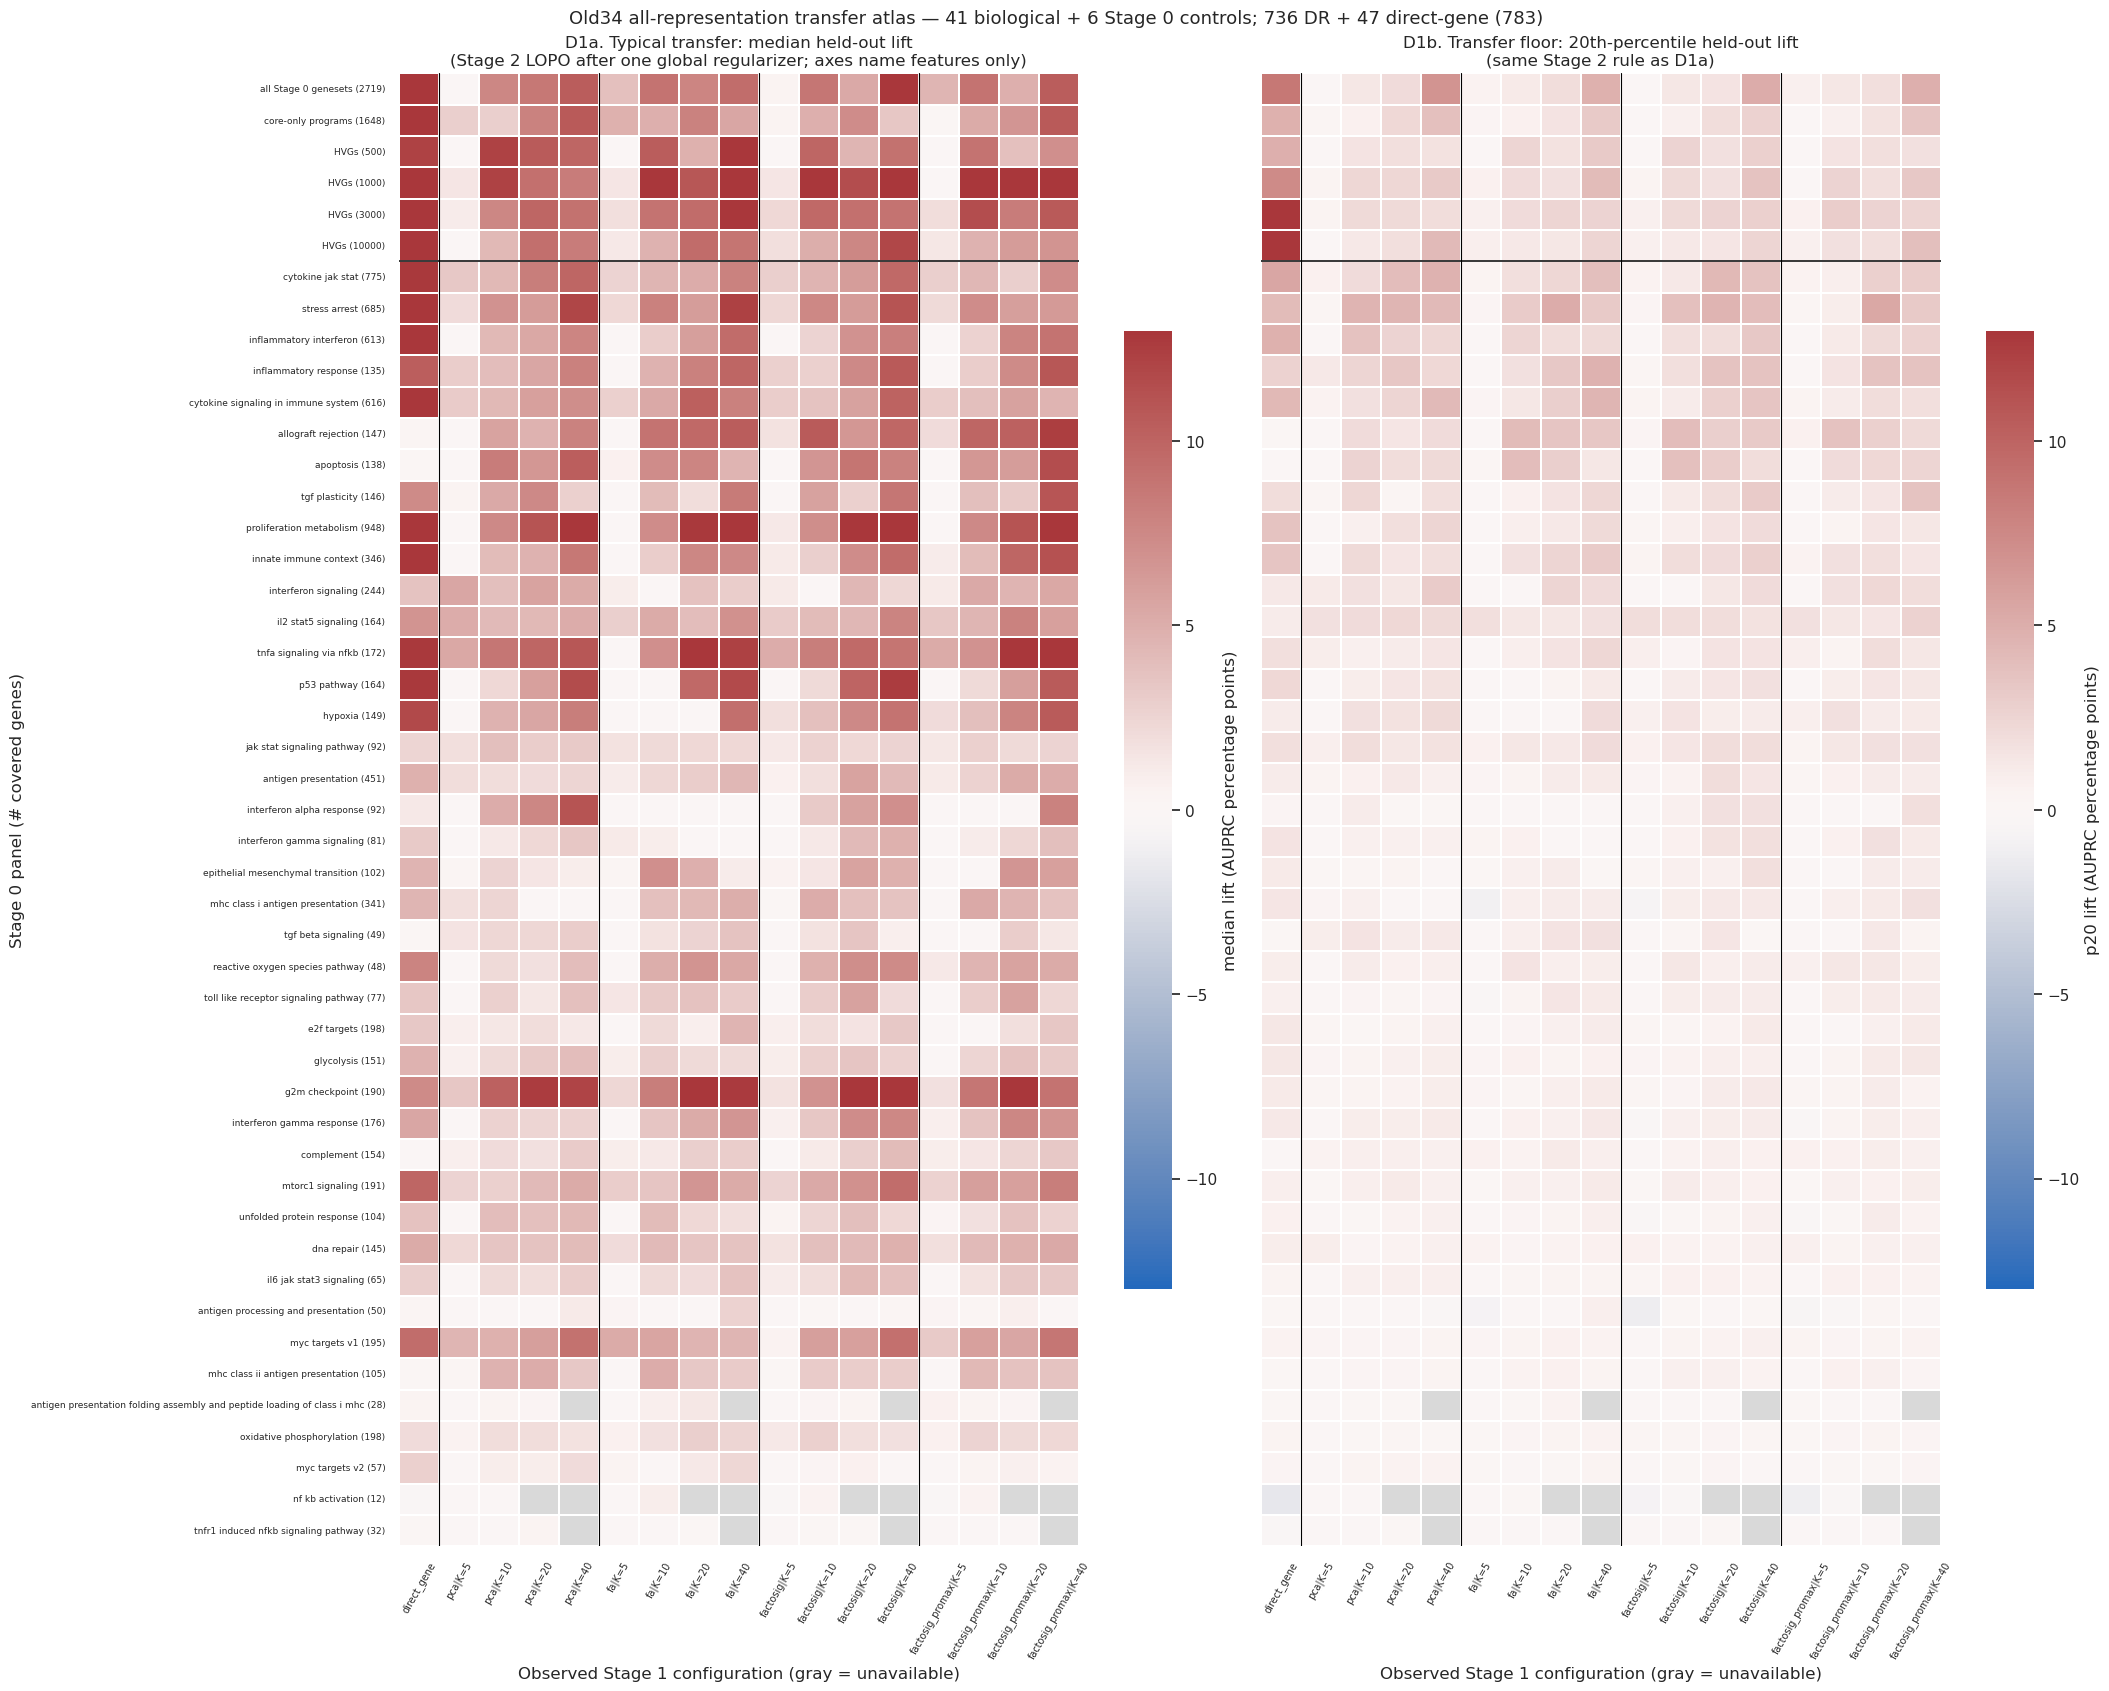

Atlas representations: 783; median lift > 0: 670; p20 lift > 0: 639.
Direct-gene column: 47/47 filled; median lift > 0: 45/47; p20 lift > 0: 43/47.
Panels with at least one p20-positive representation: 47/47
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1c_P01_raw_auprc_and_lift_all_643_atlas.png


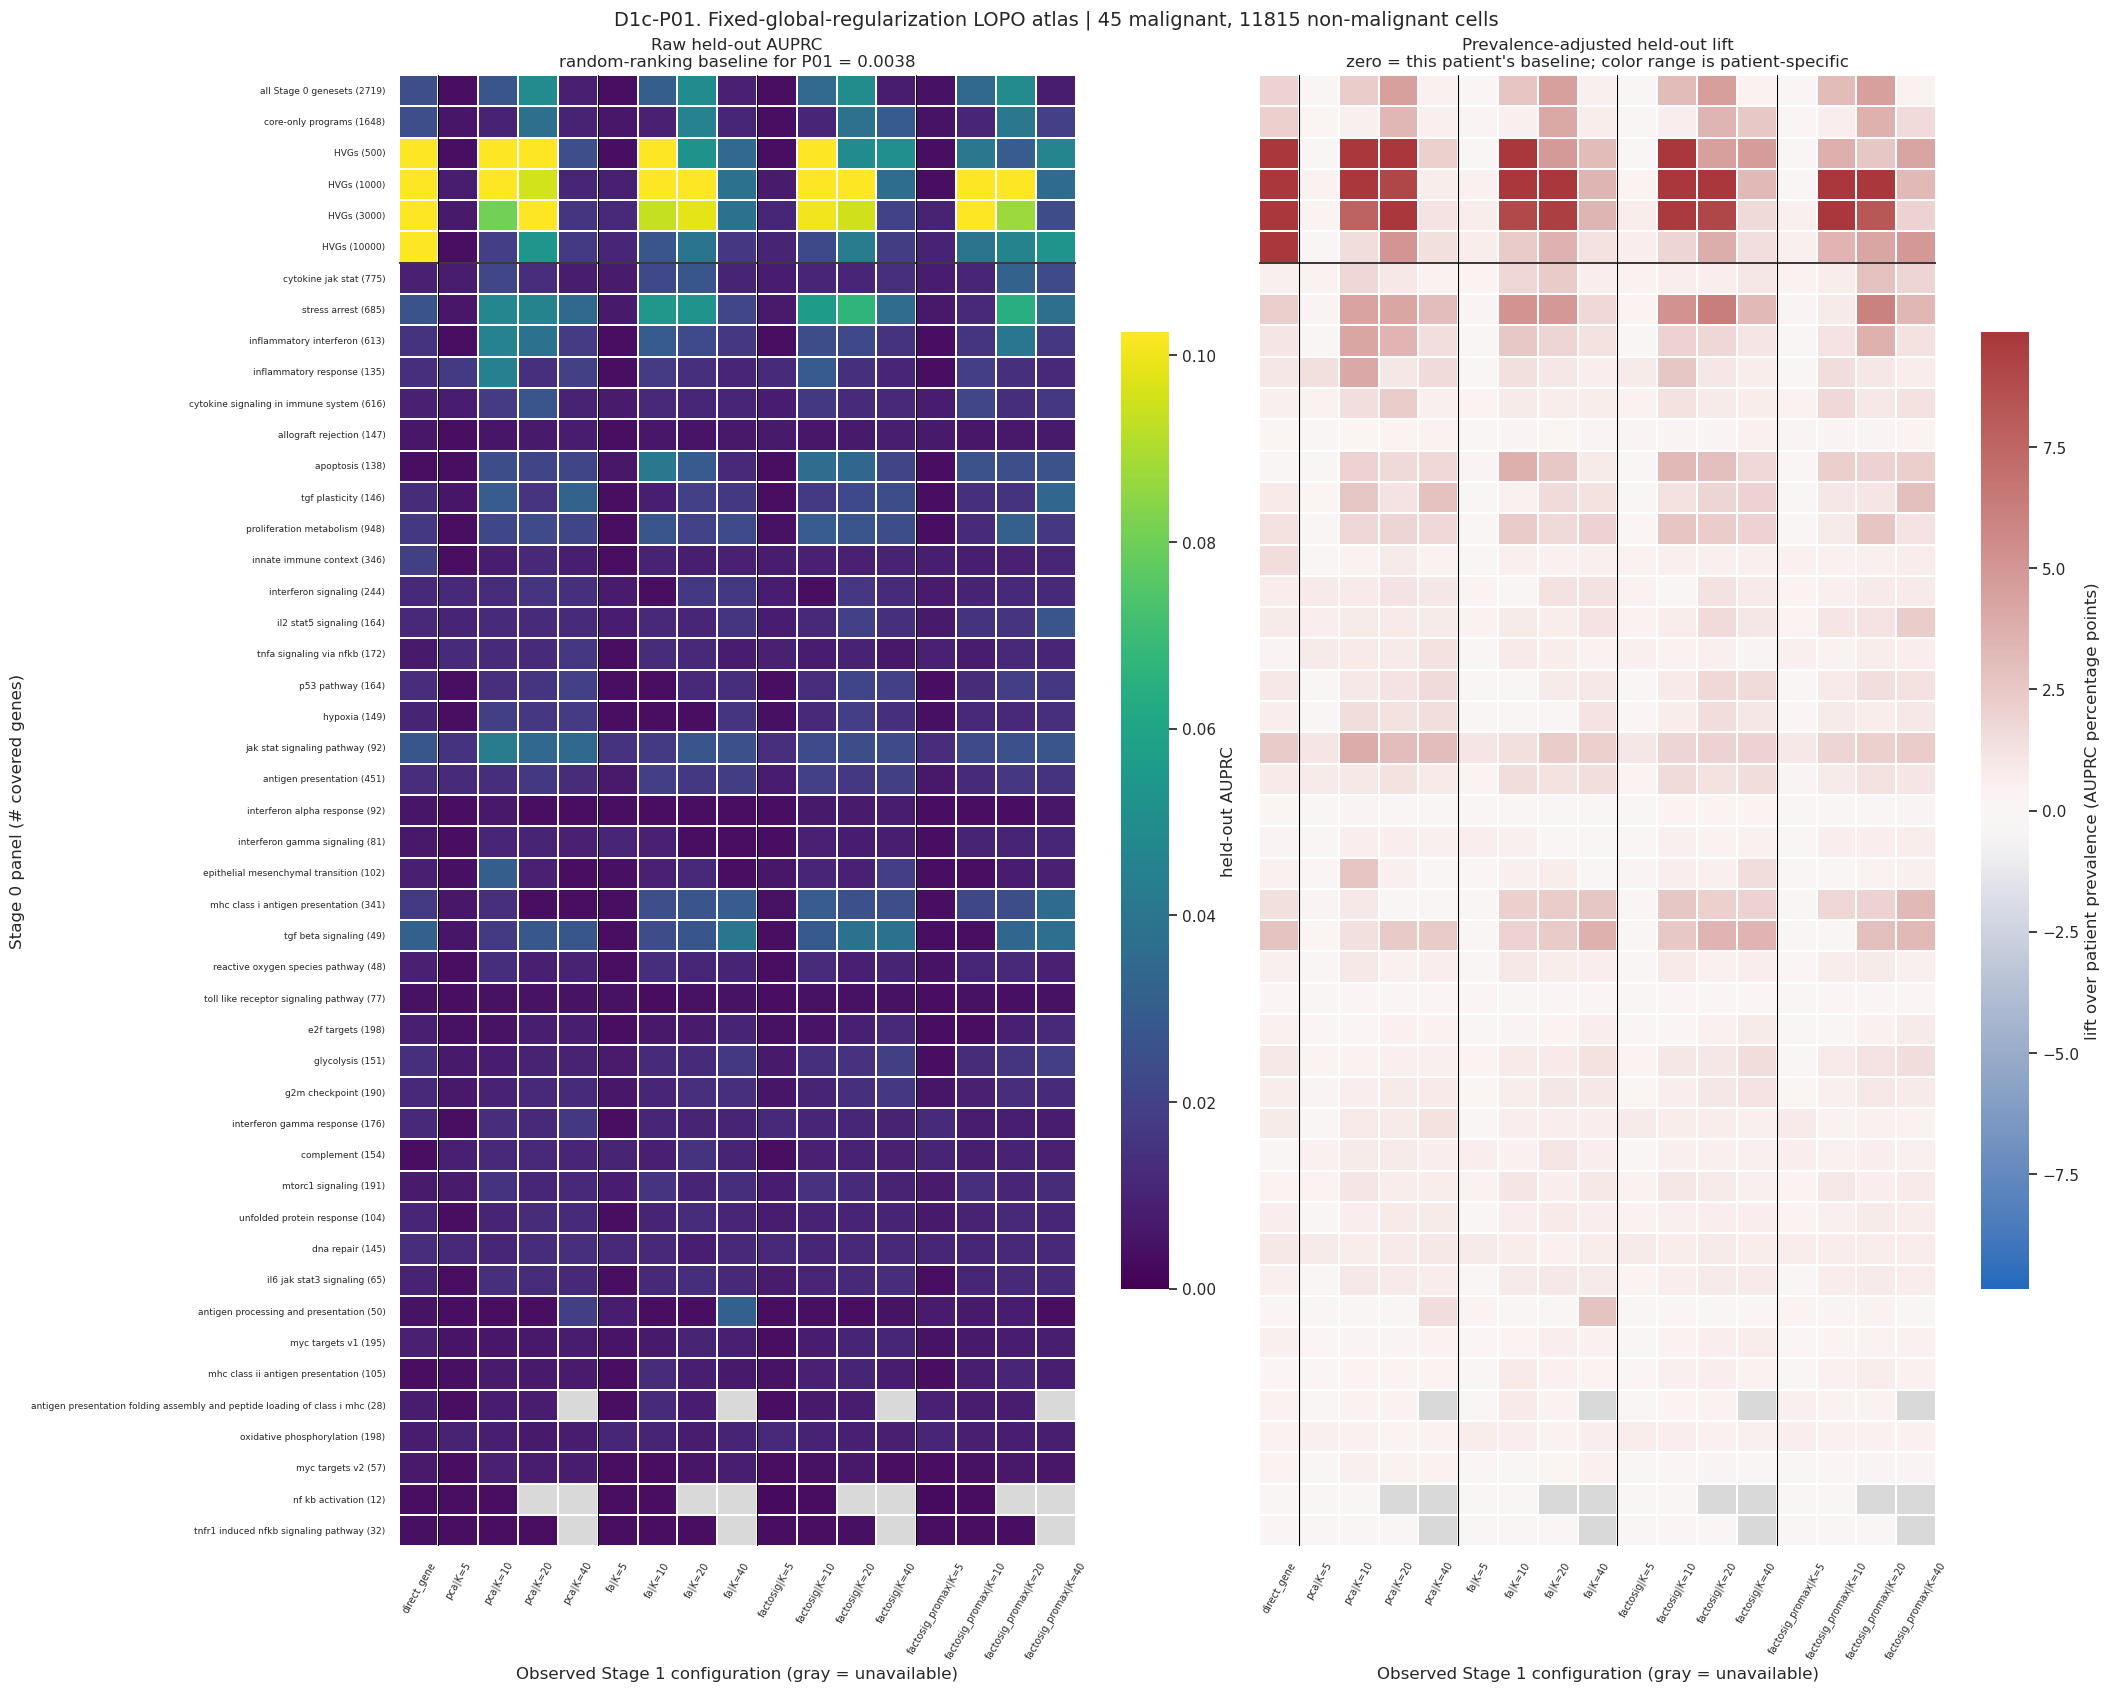

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1c_P02_raw_auprc_and_lift_all_643_atlas.png


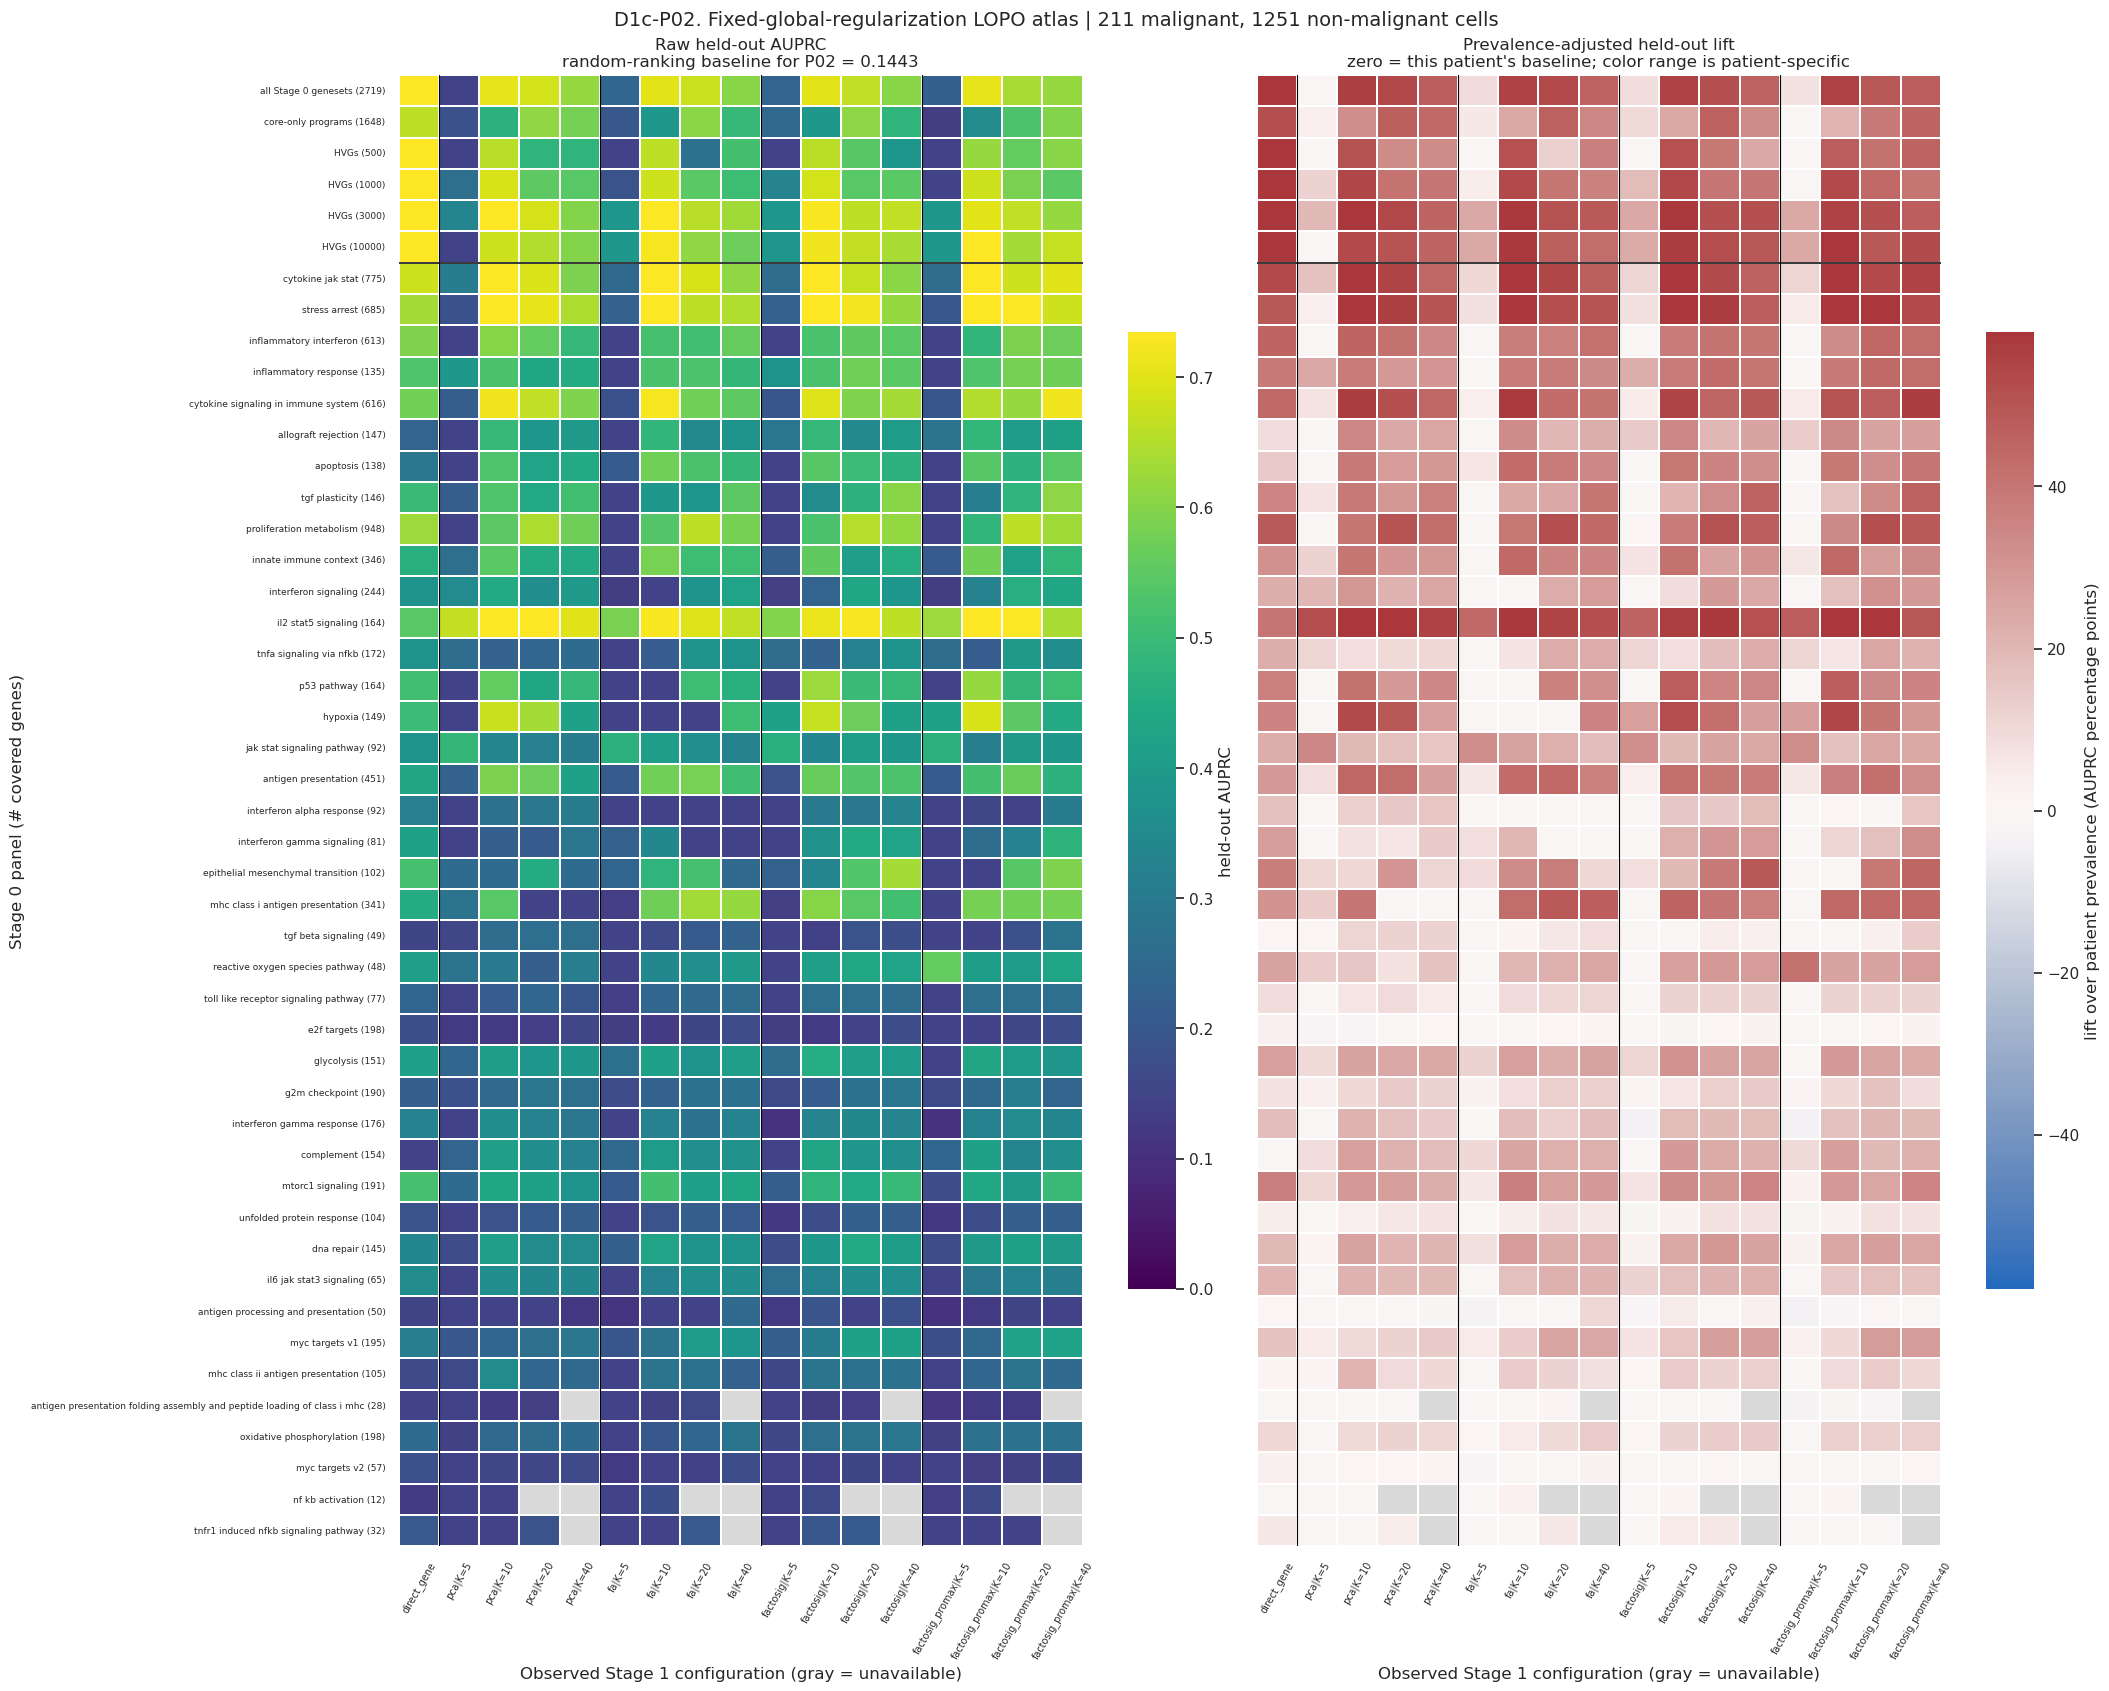

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1c_P03_raw_auprc_and_lift_all_643_atlas.png


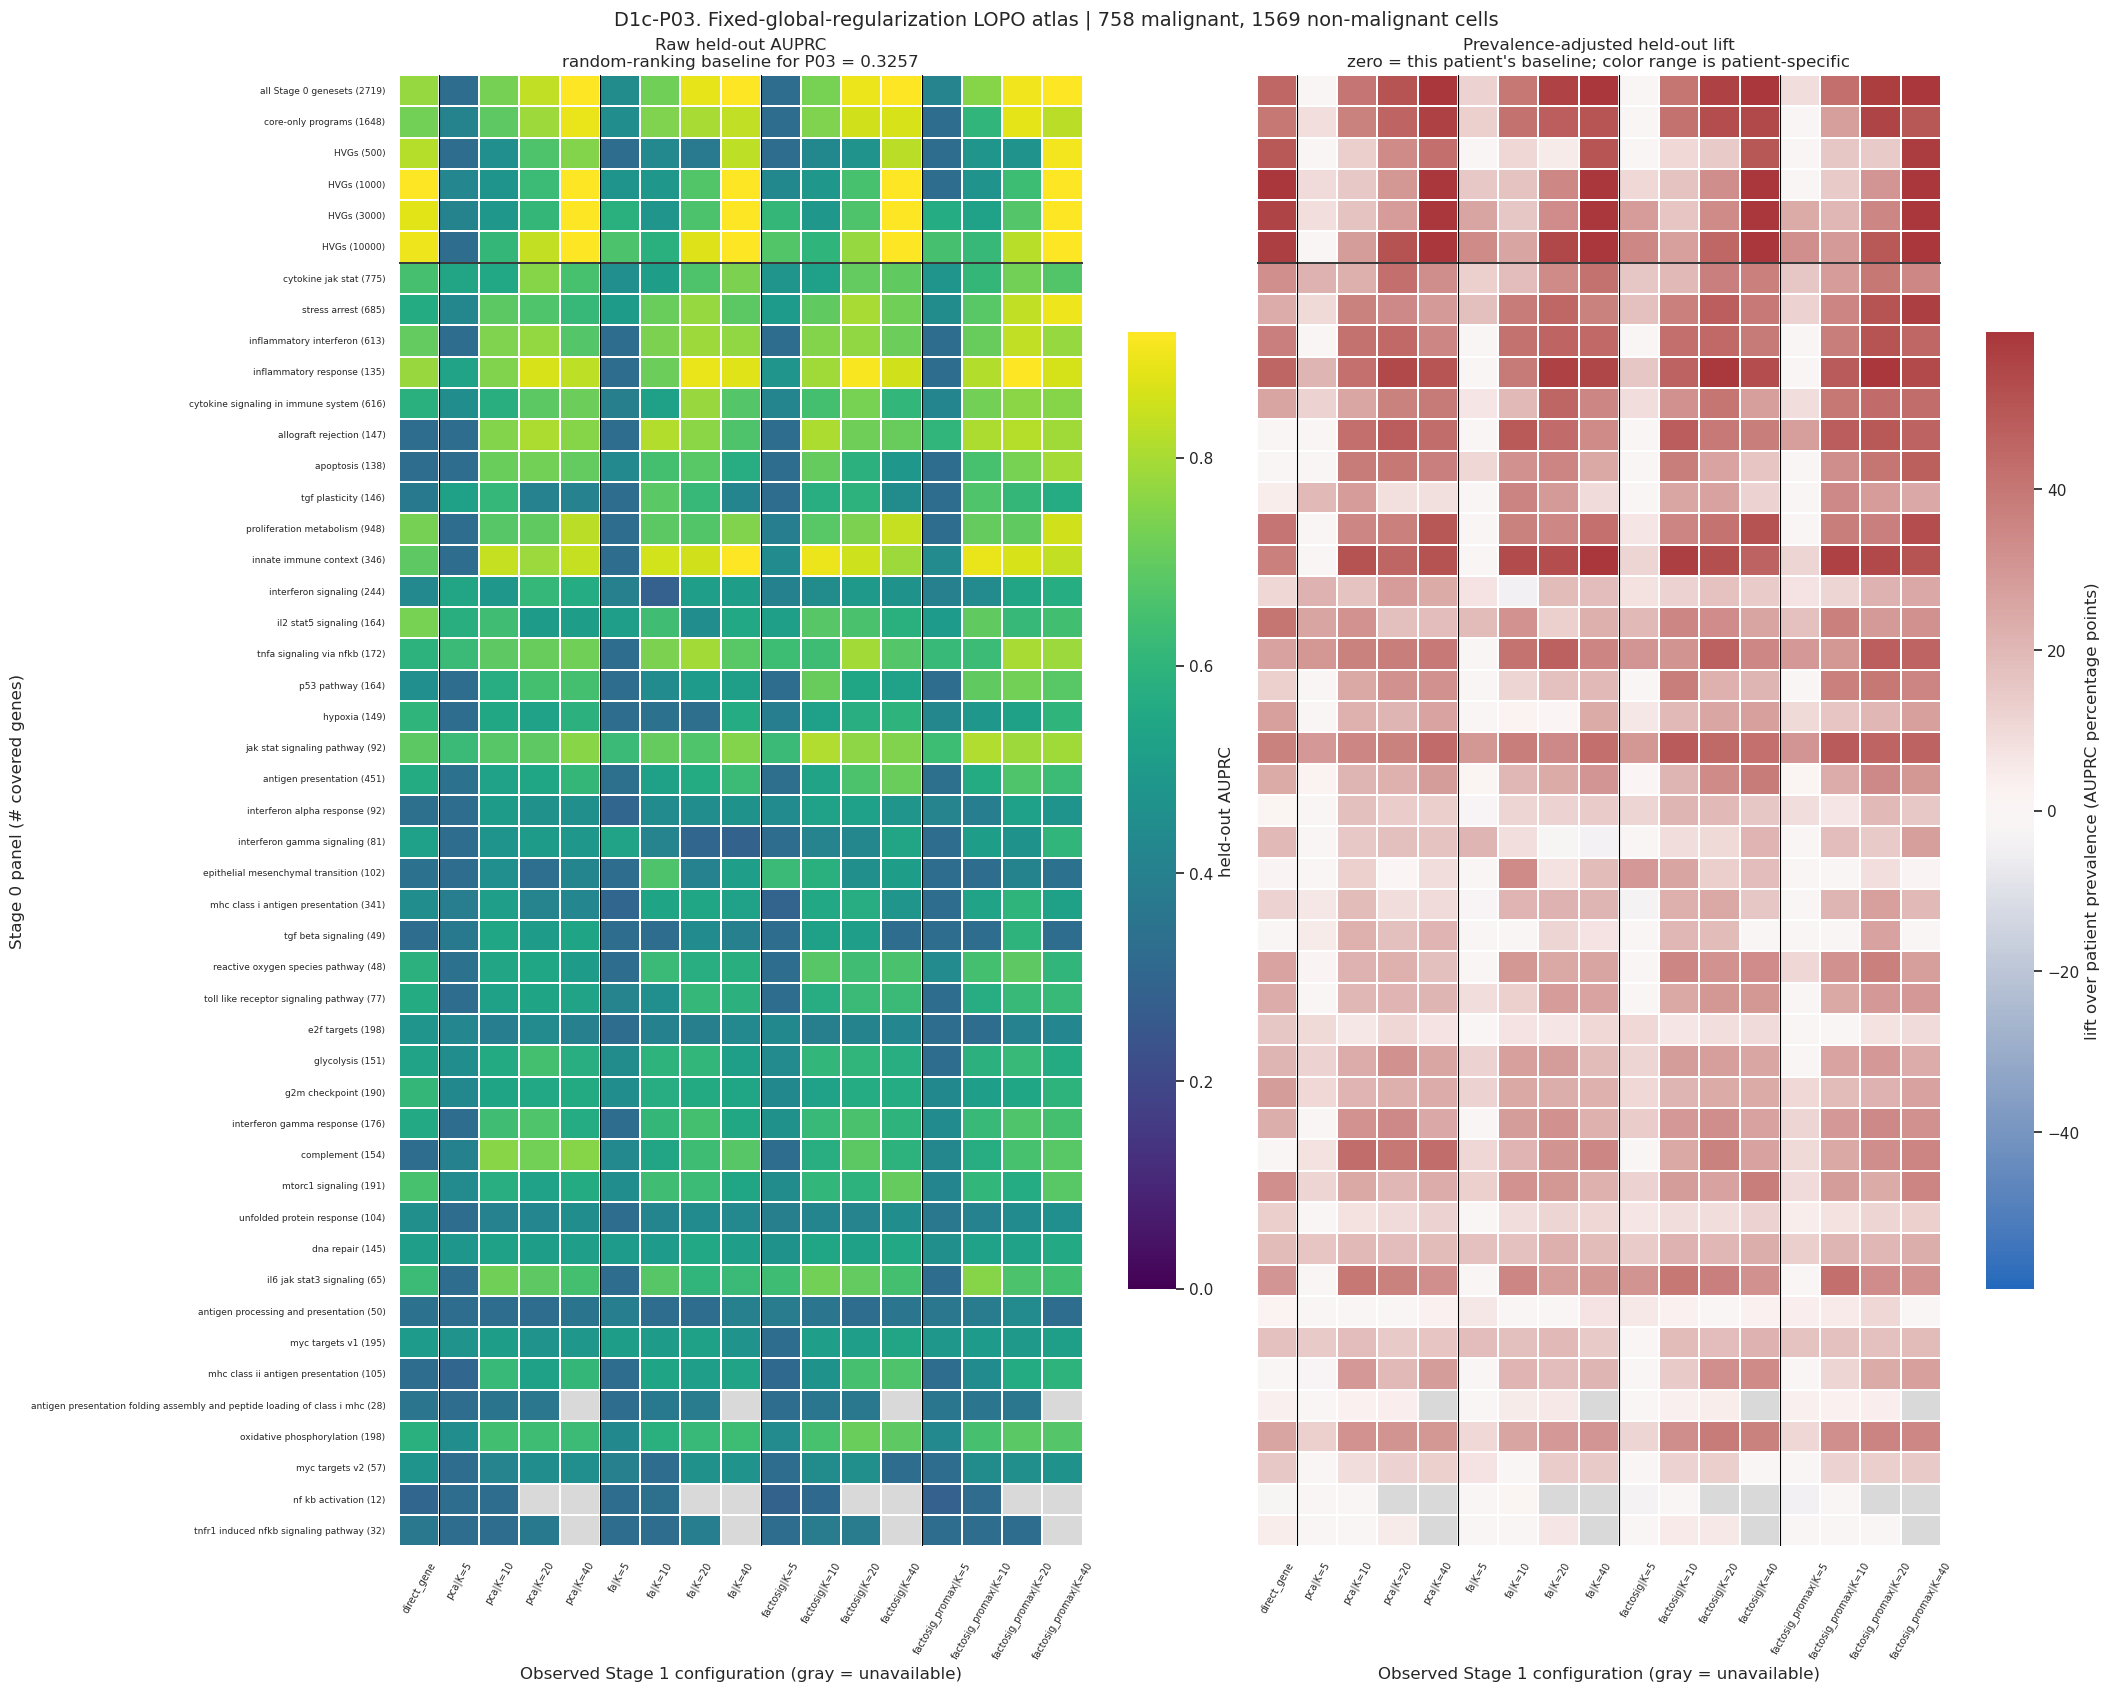

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1c_P04_raw_auprc_and_lift_all_643_atlas.png


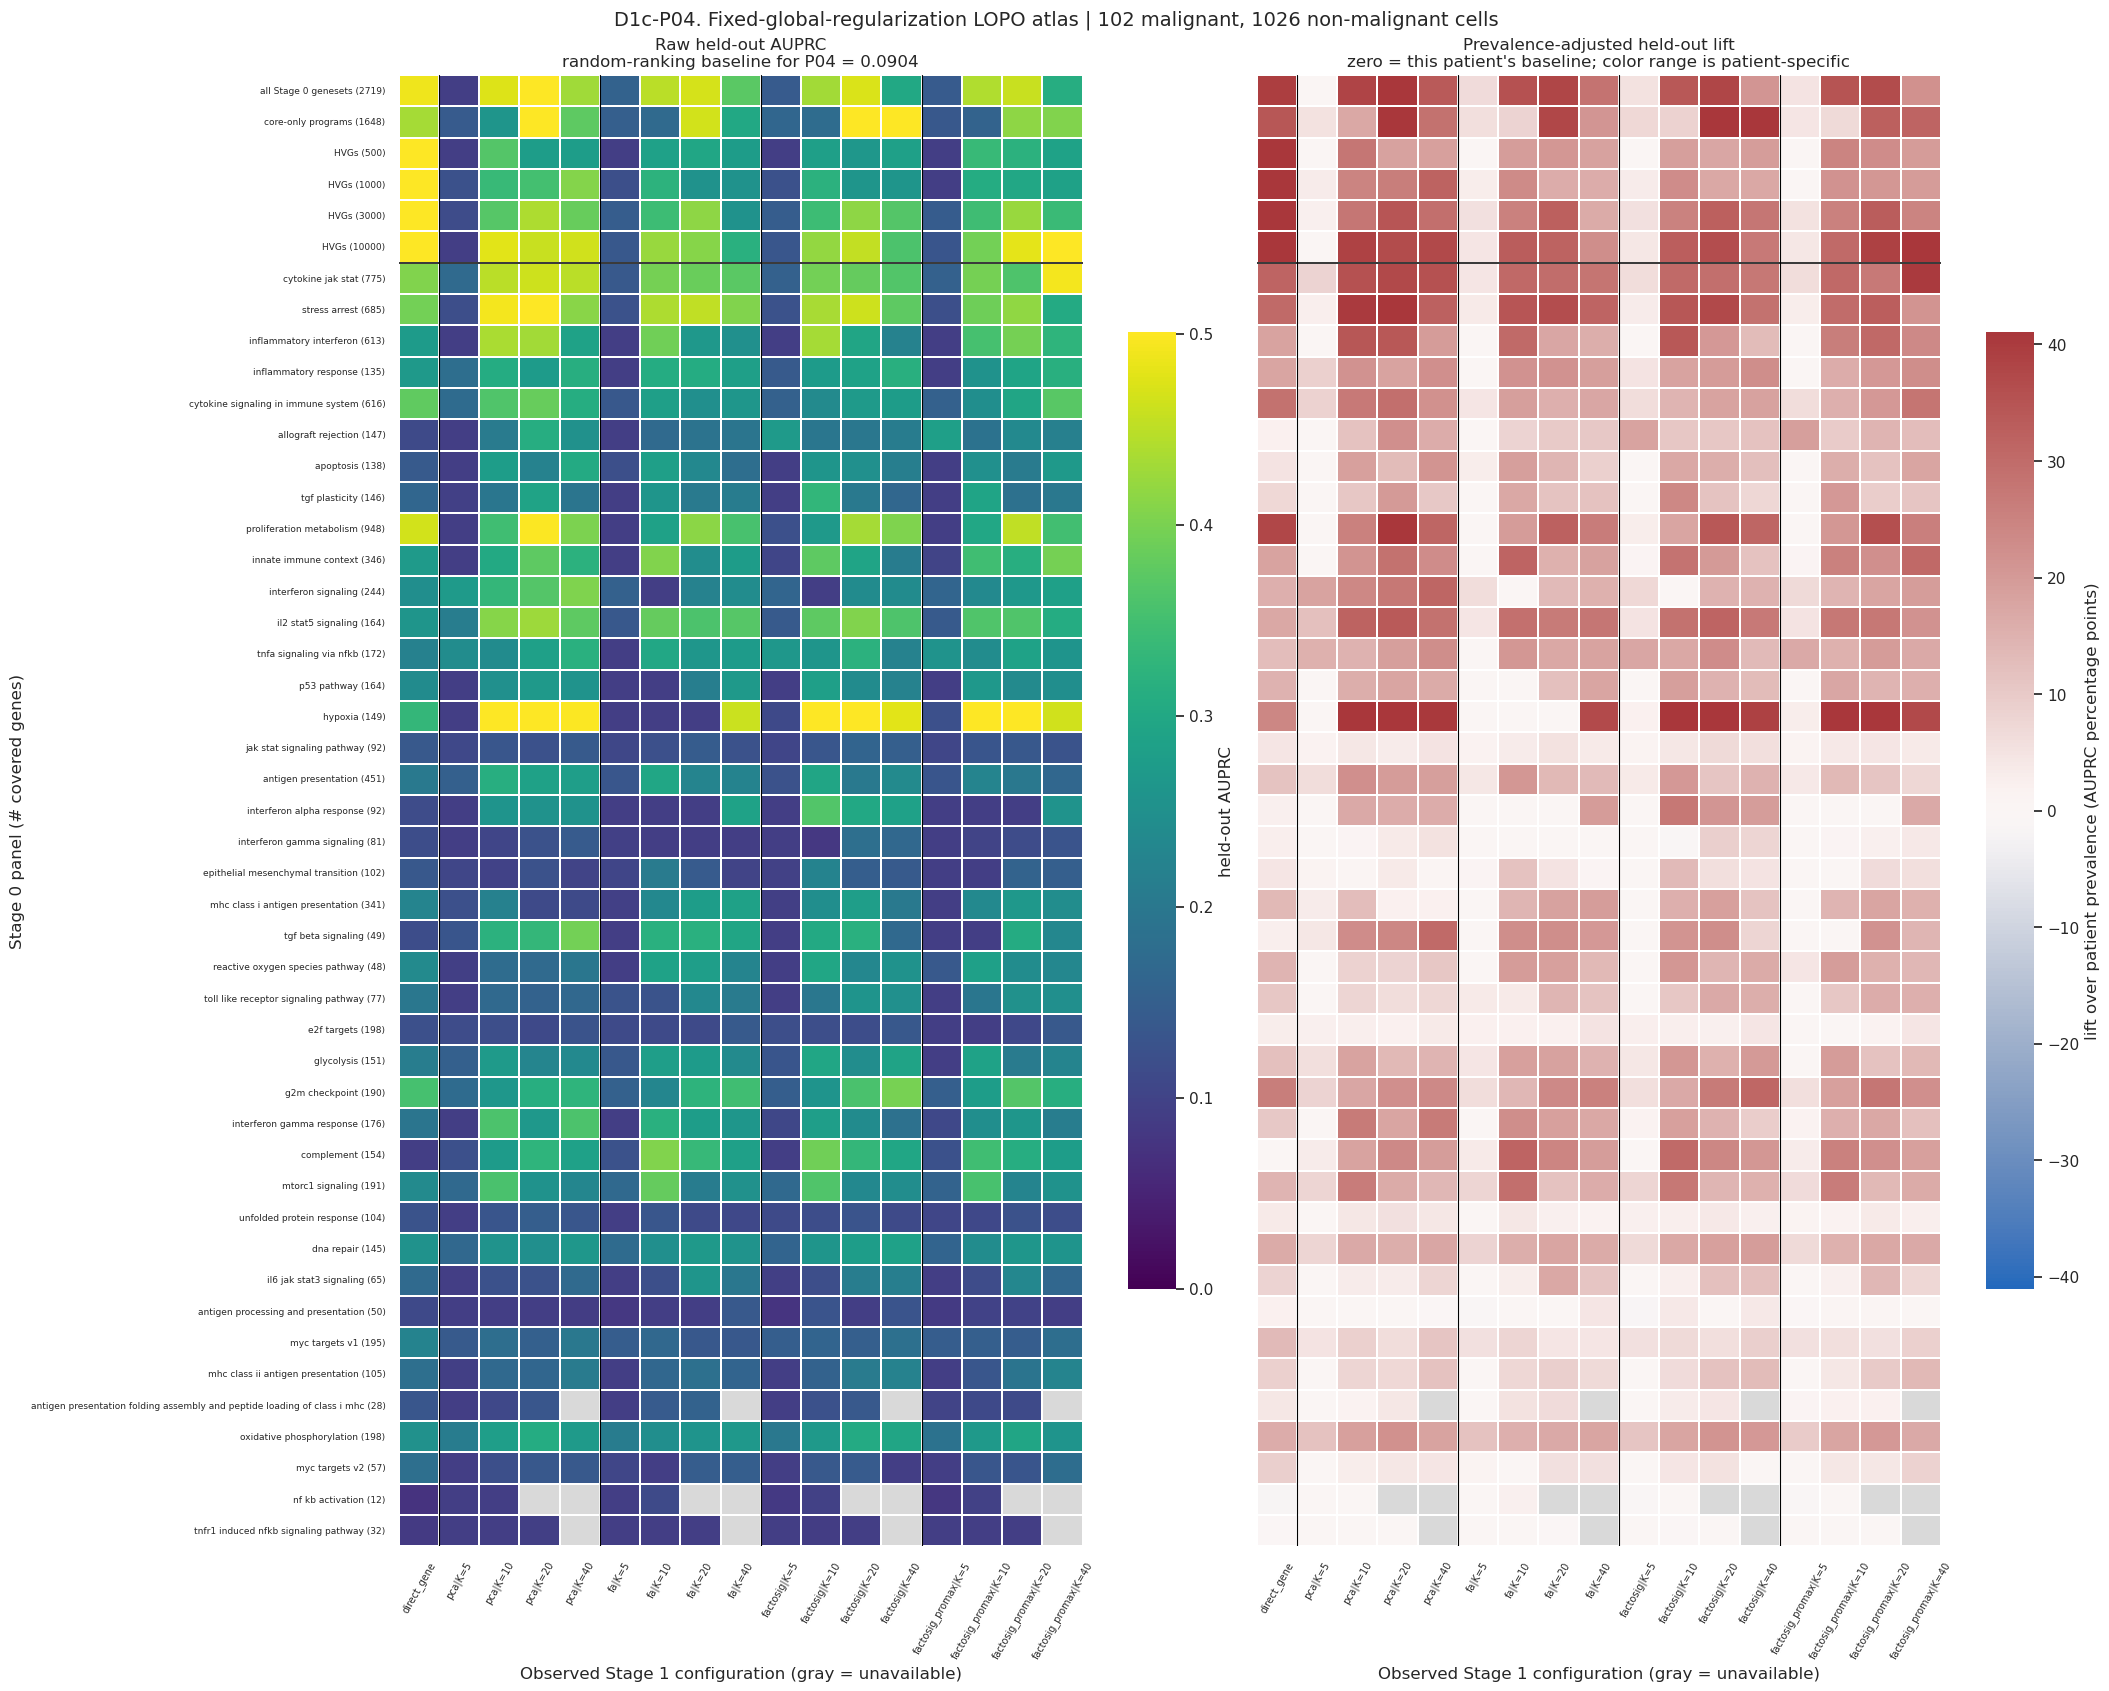

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1c_P06_raw_auprc_and_lift_all_643_atlas.png


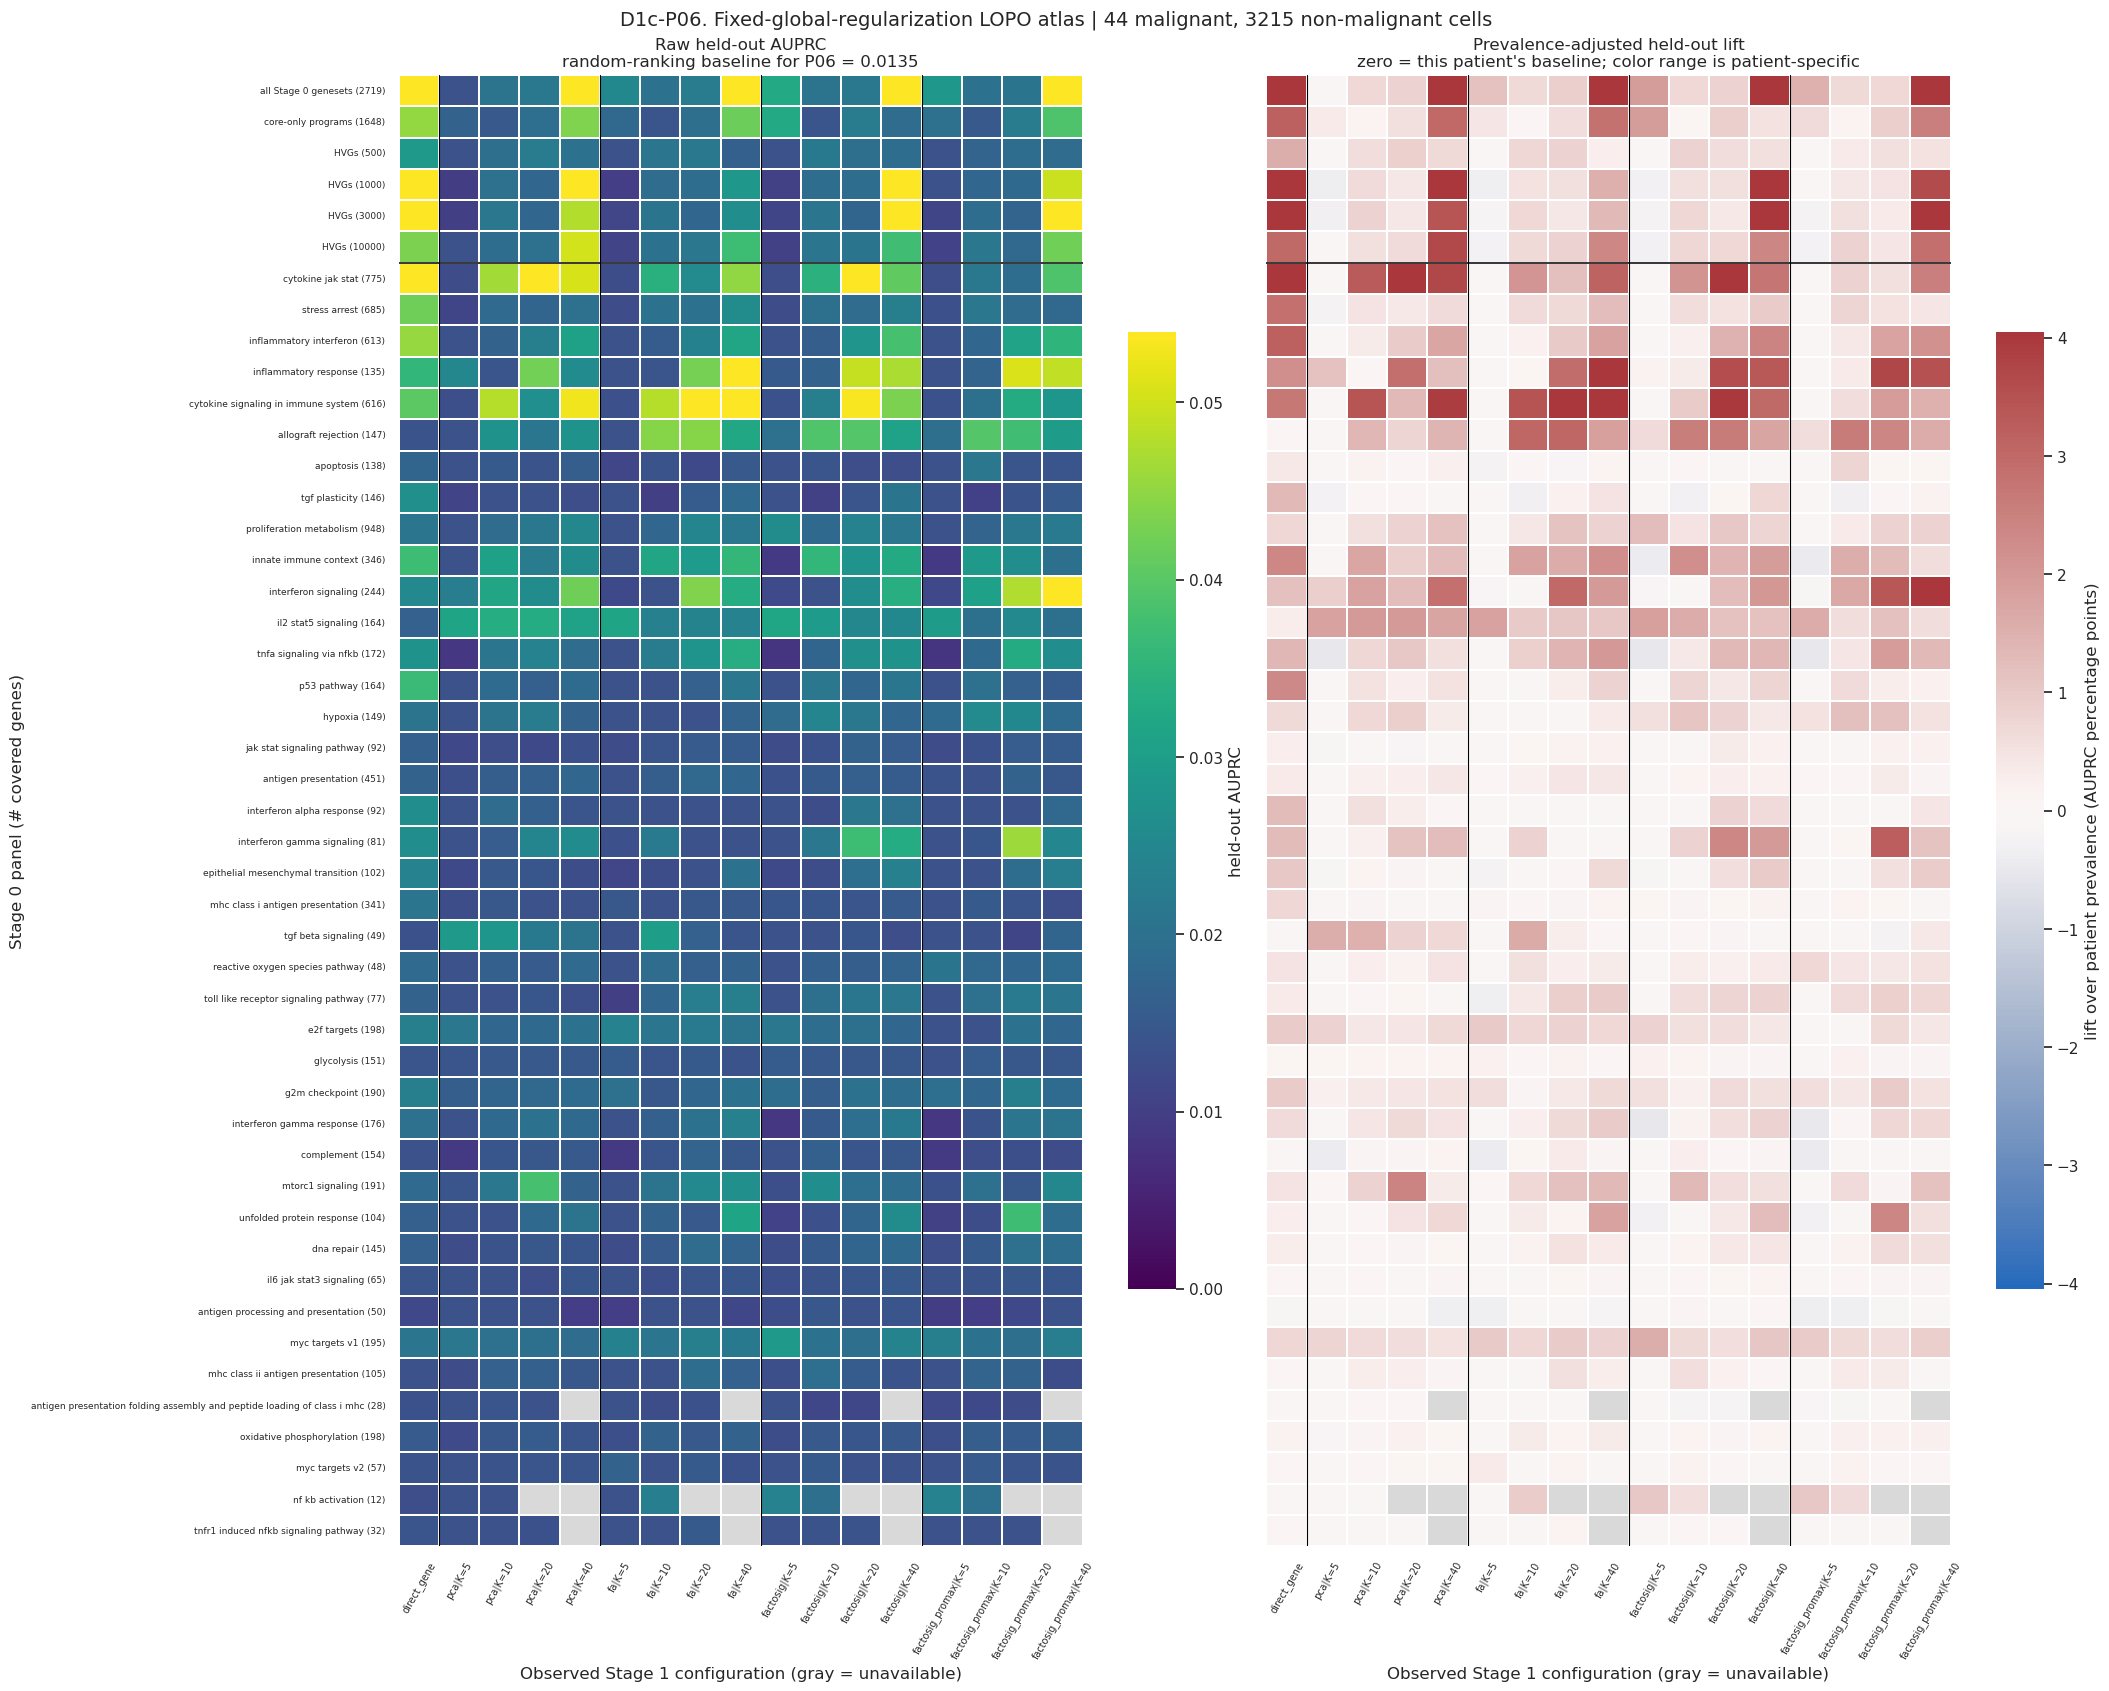

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1c_P07_raw_auprc_and_lift_all_643_atlas.png


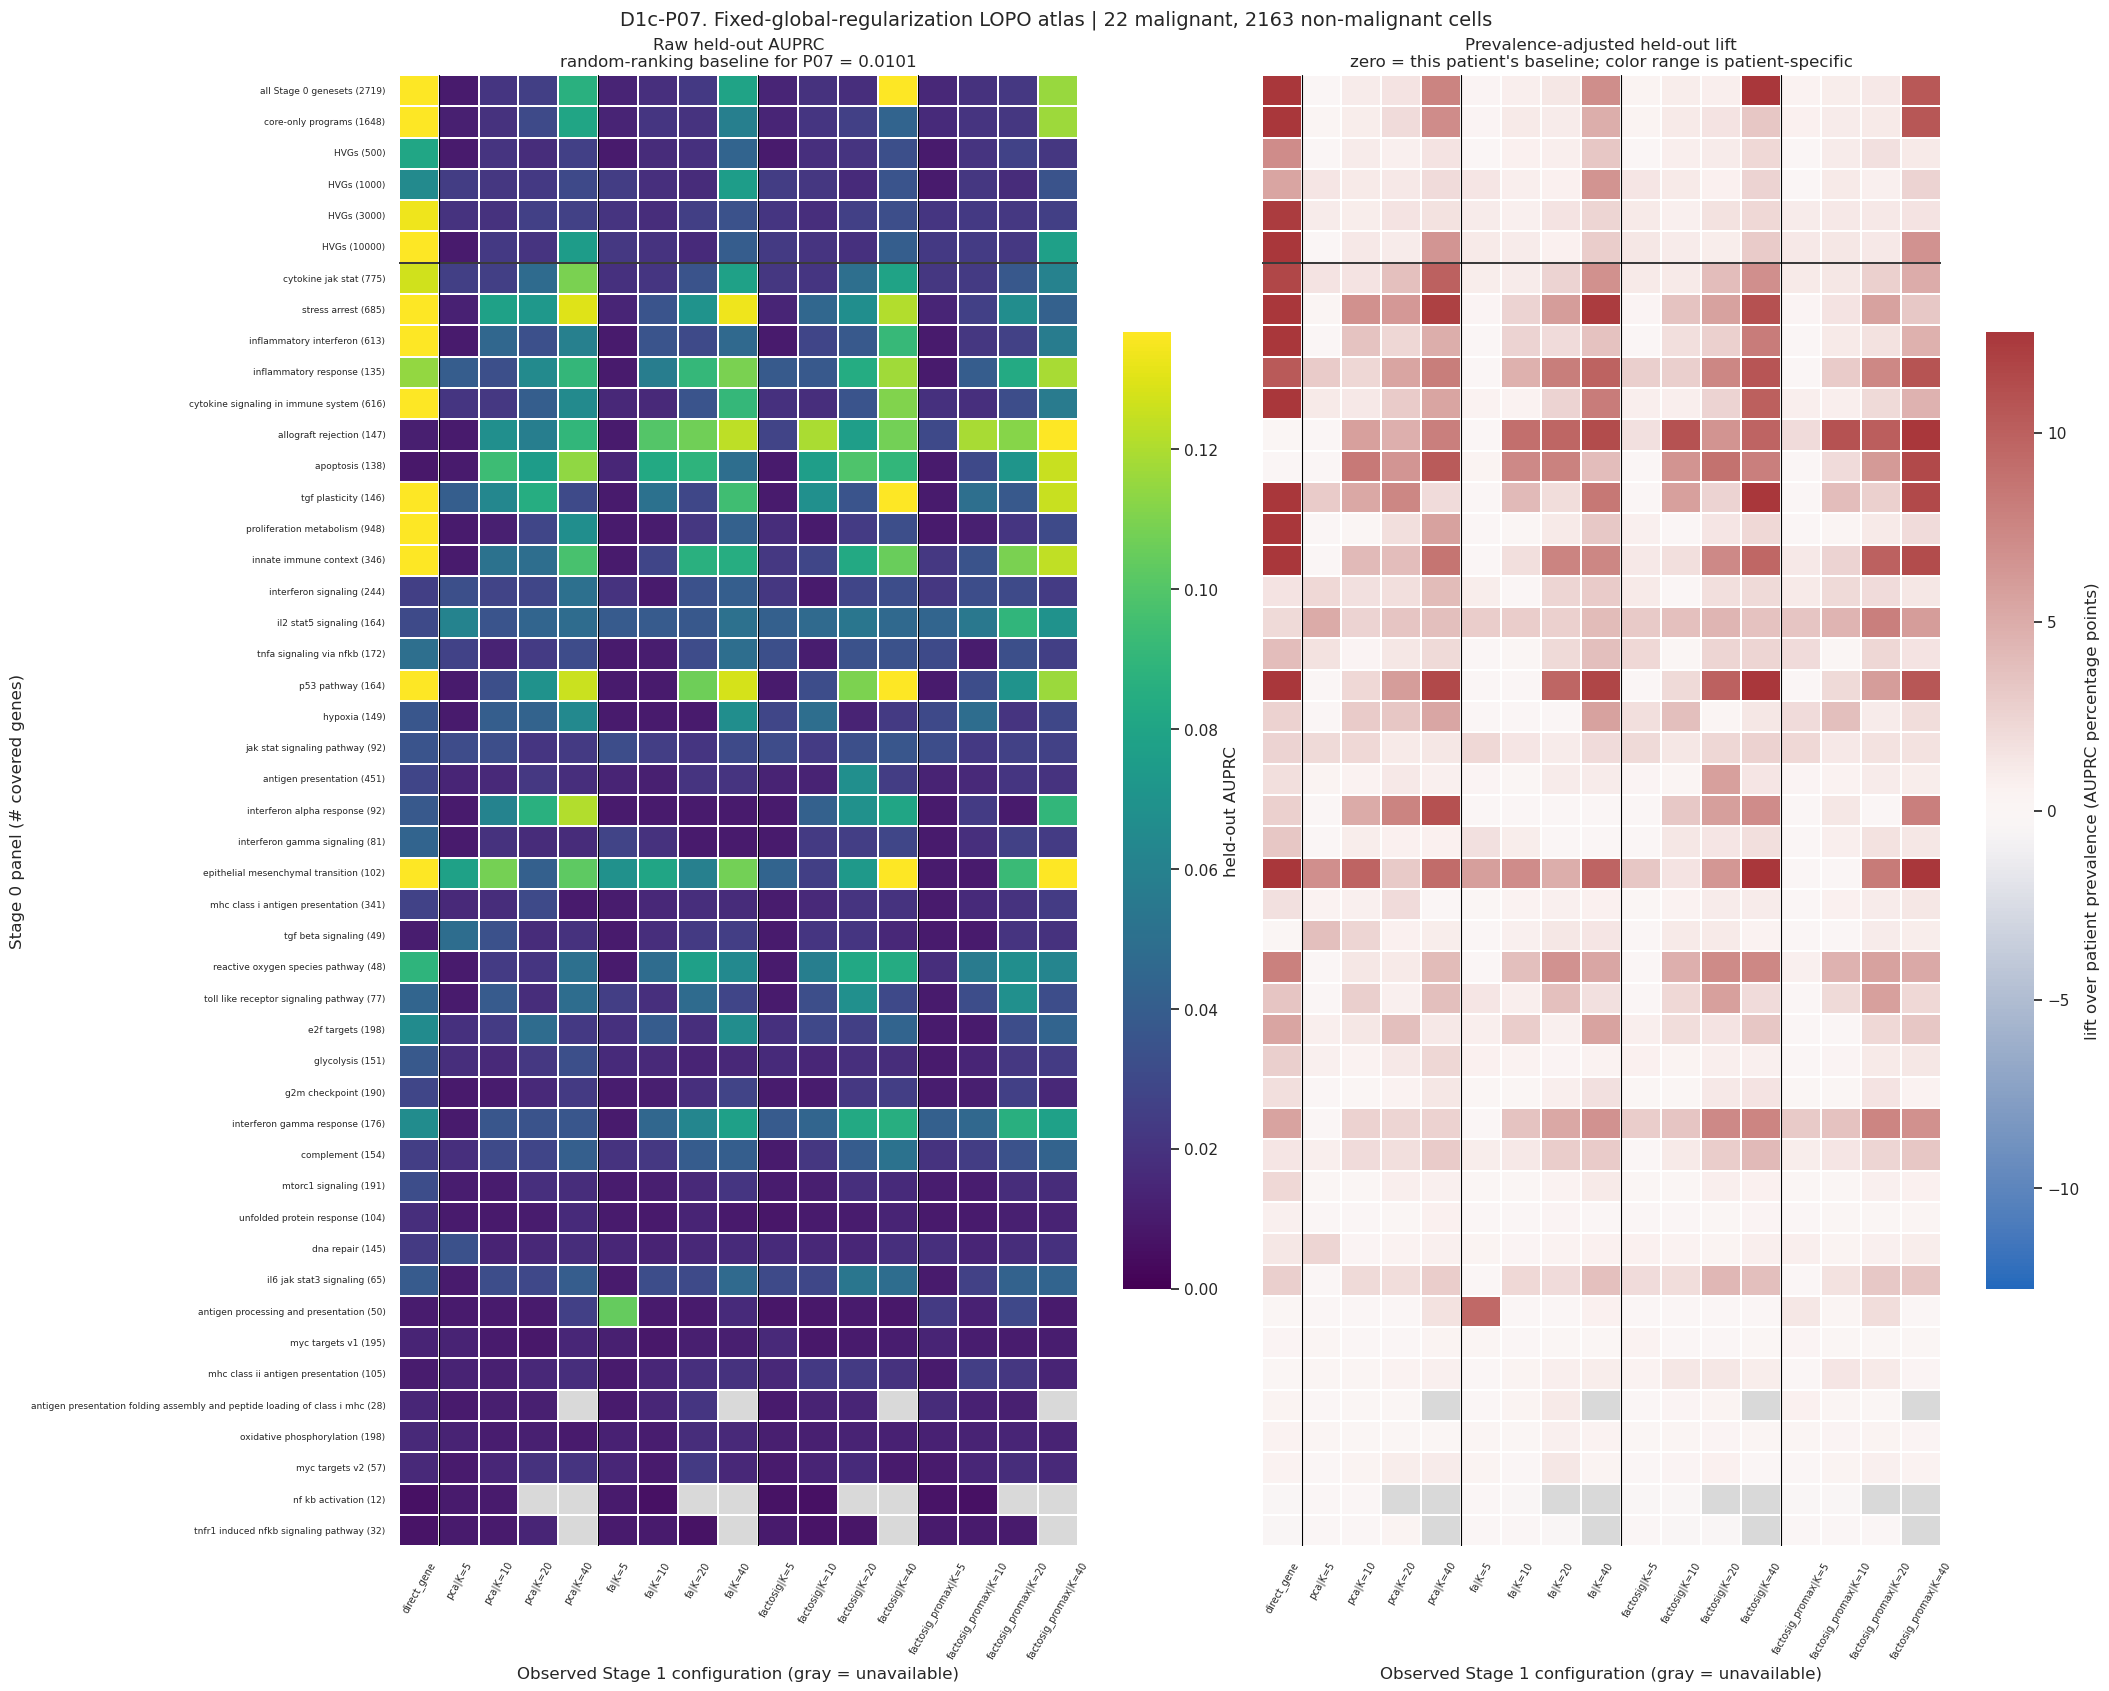

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1c_P09_raw_auprc_and_lift_all_643_atlas.png


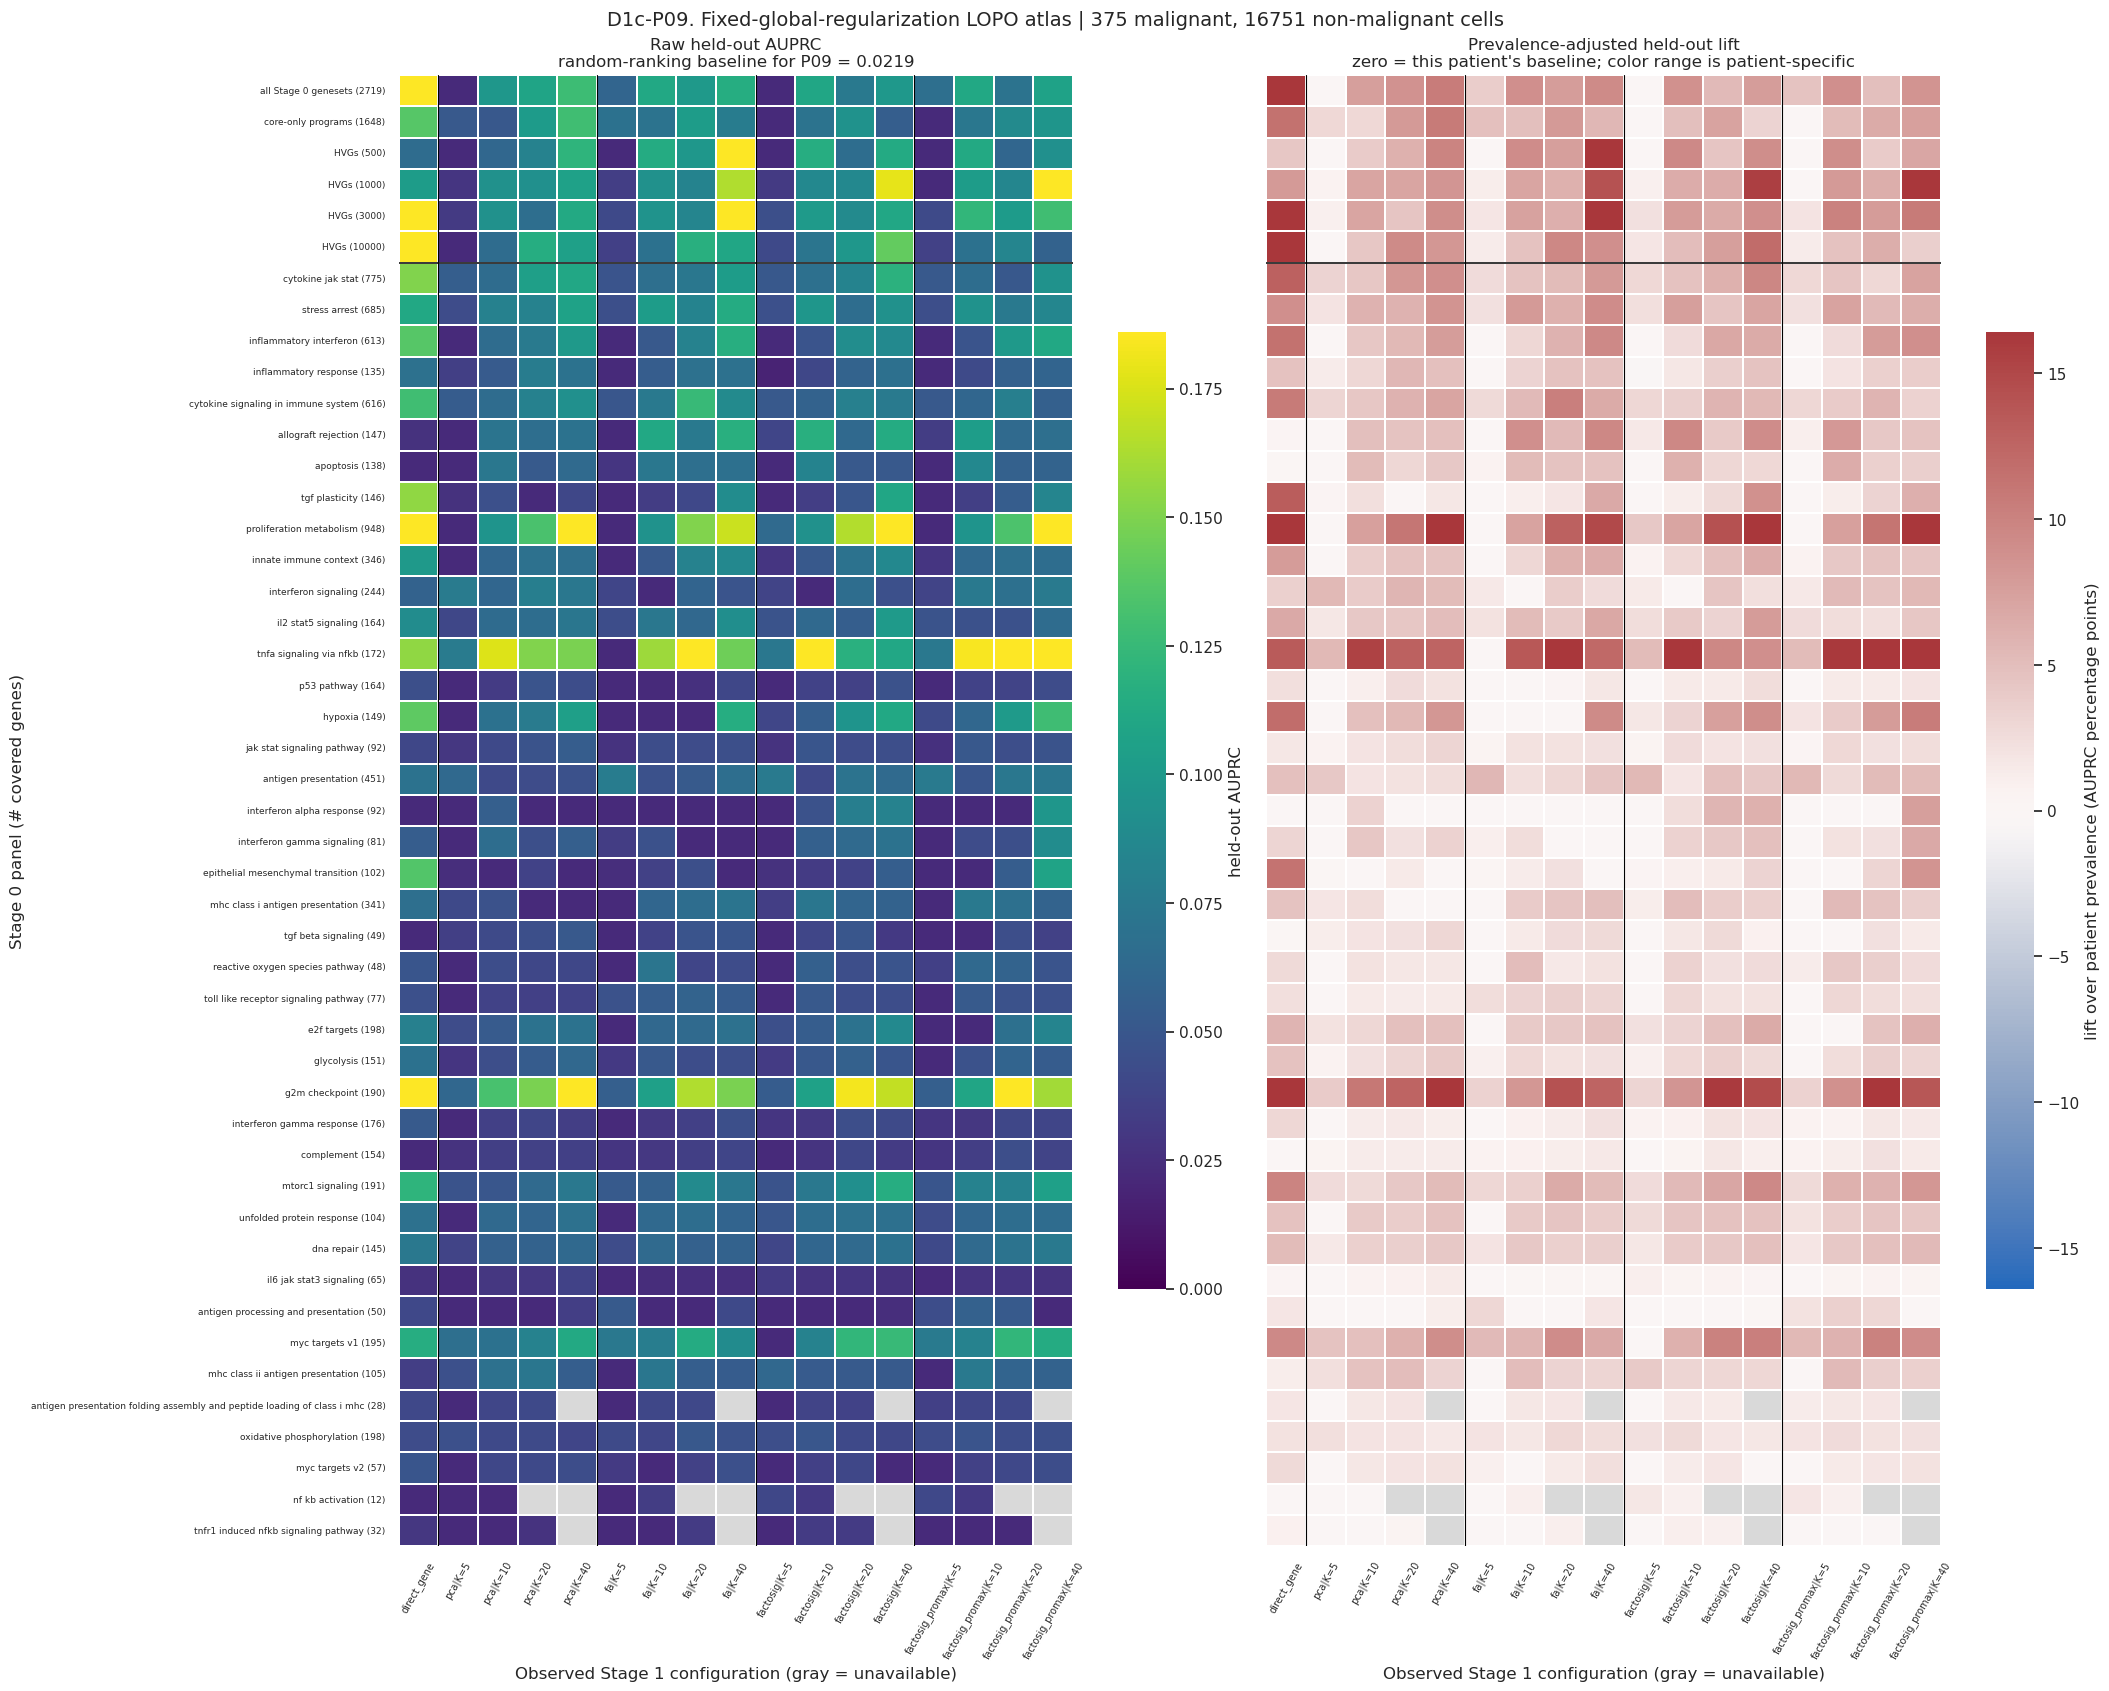

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_lift_concrete_example.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1d_concrete_patient_lift_median_p20_example.png


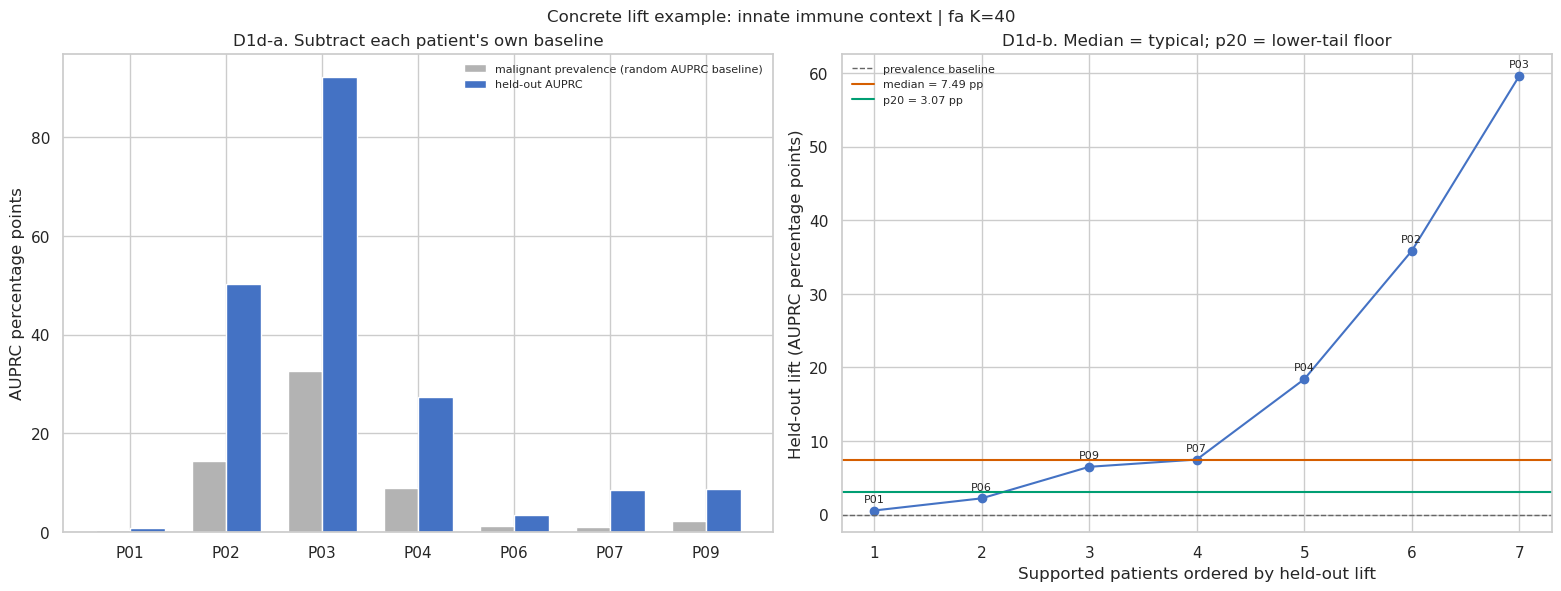

Illustration prompt: /home/minhang/mds_project/sc_classification/scripts/mrd_stage0_2/notebooks/stage0_2/old34_heldout_lift_illustration_prompt.md
Reuse helper for other examples, e.g.
plot_concrete_patient_lift_example(
    representation, selected_patient_long,
    short_panel_label='TNF via NF-kB', stage1_method='fa', effective_k=40,
)


In [3]:
control_labels = control_row_labels(atlas_representation)
bio_order = (
    atlas_representation.loc[atlas_representation["atlas_row_block"].eq("biological")]
    .groupby("panel_label_with_genes", dropna=False)
    .agg(
        best_p20_lift=("patient_p20_lift", "max"),
        best_median_lift=("patient_median_lift", "max"),
        median_across_representations=("patient_median_lift", "median"),
    )
    .sort_values(["best_p20_lift", "best_median_lift", "median_across_representations"], ascending=False)
    .index.tolist()
)
panel_order = control_labels + bio_order
assert set(panel_order) == set(atlas_representation["panel_label_with_genes"])

median_matrix = (
    atlas_representation.pivot(index="panel_label_with_genes", columns="configuration", values="patient_median_lift")
    .reindex(index=panel_order, columns=CONFIG_ORDER)
)
p20_matrix = (
    atlas_representation.pivot(index="panel_label_with_genes", columns="configuration", values="patient_p20_lift")
    .reindex(index=panel_order, columns=CONFIG_ORDER)
)
assert median_matrix.shape[0] == N_D1_PANELS
assert median_matrix["direct_gene"].notna().sum() == N_D1_DIRECT_GENE
assert p20_matrix["direct_gene"].notna().sum() == N_D1_DIRECT_GENE
assert median_matrix.loc[control_labels, "direct_gene"].notna().all()
median_matrix.to_csv(TABLE_DIR / "old34_all_representation_patient_median_lift_matrix.csv")
p20_matrix.to_csv(TABLE_DIR / "old34_all_representation_patient_p20_lift_matrix.csv")

median_matrix_plot = 100 * median_matrix
p20_matrix_plot = 100 * p20_matrix
values = np.concatenate([median_matrix_plot.to_numpy().ravel(), p20_matrix_plot.to_numpy().ravel()])
values = values[np.isfinite(values)]
vmax = max(float(np.quantile(np.abs(values), 0.98)), 3.0)
cmap = plt.get_cmap("vlag").copy()
cmap.set_bad("#d9d9d9")

fig, axes = plt.subplots(1, 2, figsize=(21, 16.8), sharey=True, constrained_layout=True)
for ax, matrix, title, cbar_label in [
    (axes[0], median_matrix_plot, "D1a. Typical transfer: median held-out lift\n(Stage 2 LOPO after one global regularizer; axes name features only)", "median lift (AUPRC percentage points)"),
    (axes[1], p20_matrix_plot, "D1b. Transfer floor: 20th-percentile held-out lift\n(same Stage 2 rule as D1a)", "p20 lift (AUPRC percentage points)"),
]:
    sns.heatmap(
        matrix,
        cmap=cmap,
        center=0,
        vmin=-vmax,
        vmax=vmax,
        linewidths=0.18,
        linecolor="white",
        cbar_kws={"label": cbar_label, "shrink": 0.65},
        ax=ax,
    )
    for boundary in [1, 5, 9, 13]:
        ax.axvline(boundary, color="black", lw=0.8)
    ax.axhline(len(control_labels), color="black", lw=1.1)
    ax.set_title(title)
    ax.set_xlabel("Observed Stage 1 configuration (gray = unavailable)")
    ax.set_ylabel("Stage 0 panel (# covered genes)" if ax is axes[0] else "")
    ax.tick_params(axis="y", labelsize=6.5)
    ax.tick_params(axis="x", labelsize=7, rotation=60)

fig.suptitle(
    "Old34 all-representation transfer atlas — 41 biological + 6 Stage 0 controls; 736 DR + 47 direct-gene (783)",
    fontsize=13,
)
save_figure(fig, "D1_old34_all_643_representation_transfer_atlas")
plt.show()

n_median_positive = int(atlas_representation["patient_median_lift"].gt(0).sum())
n_floor_positive = int(atlas_representation["patient_p20_lift"].gt(0).sum())
n_panels_any_floor_positive = int(
    atlas_representation.groupby("stage0_panel_id")["patient_p20_lift"].max().gt(0).sum()
)
n_direct_median_positive = int(
    atlas_representation.loc[atlas_representation["configuration"].eq("direct_gene"), "patient_median_lift"].gt(0).sum()
)
n_direct_floor_positive = int(
    atlas_representation.loc[atlas_representation["configuration"].eq("direct_gene"), "patient_p20_lift"].gt(0).sum()
)
print(
    f"Atlas representations: {len(atlas_representation)}; median lift > 0: {n_median_positive}; "
    f"p20 lift > 0: {n_floor_positive}."
)
print(
    f"Direct-gene column: {N_D1_DIRECT_GENE}/{N_D1_PANELS} filled; median lift > 0: {n_direct_median_positive}/{N_D1_DIRECT_GENE}; "
    f"p20 lift > 0: {n_direct_floor_positive}/{N_D1_DIRECT_GENE}."
)
print(f"Panels with at least one p20-positive representation: {n_panels_any_floor_positive}/{N_D1_PANELS}")

# D1c: one raw-AUPRC versus prevalence-adjusted-lift atlas per supported patient.
SUPPORTED_PATIENTS = sorted(atlas_selected_patient_long["heldout_patient"].unique())
raw_cmap = plt.get_cmap("viridis").copy()
raw_cmap.set_bad("#d9d9d9")
per_patient_figure_pngs: list[Path] = []

for patient_id in SUPPORTED_PATIENTS:
    patient_df = atlas_selected_patient_long.loc[
        atlas_selected_patient_long["heldout_patient"].eq(patient_id)
    ].copy()
    assert len(patient_df) == N_D1_ATLAS
    prevalence = float(patient_df["patient_prevalence"].iloc[0])
    n_malignant = int(patient_df["n_malignant_h"].iloc[0])
    n_normal = int(patient_df["n_normal_h"].iloc[0])
    raw_matrix = (
        patient_df.pivot(
            index="panel_label_with_genes",
            columns="configuration",
            values="heldout_auprc",
        )
        .reindex(index=panel_order, columns=CONFIG_ORDER)
    )
    lift_matrix_pp = (
        patient_df.pivot(
            index="panel_label_with_genes",
            columns="configuration",
            values="heldout_lift_percentage_points",
        )
        .reindex(index=panel_order, columns=CONFIG_ORDER)
    )
    raw_vmax = max(float(np.nanquantile(raw_matrix.to_numpy(), 0.98)), prevalence * 1.25, 0.05)
    patient_lift_vmax_pp = max(
        float(np.nanquantile(np.abs(lift_matrix_pp.to_numpy()), 0.98)),
        1.0,
    )

    fig, axes = plt.subplots(1, 2, figsize=(21, 16.8), sharey=True, constrained_layout=True)
    sns.heatmap(
        raw_matrix,
        cmap=raw_cmap,
        vmin=0,
        vmax=raw_vmax,
        linewidths=0.18,
        linecolor="white",
        cbar_kws={"label": "held-out AUPRC", "shrink": 0.65},
        ax=axes[0],
    )
    sns.heatmap(
        lift_matrix_pp,
        cmap=cmap,
        center=0,
        vmin=-patient_lift_vmax_pp,
        vmax=patient_lift_vmax_pp,
        linewidths=0.18,
        linecolor="white",
        cbar_kws={"label": "lift over patient prevalence (AUPRC percentage points)", "shrink": 0.65},
        ax=axes[1],
    )
    for ax in axes:
        for boundary in [1, 5, 9, 13]:
            ax.axvline(boundary, color="black", lw=0.8)
        ax.axhline(len(control_labels), color="black", lw=1.1)
        ax.set_xlabel("Observed Stage 1 configuration (gray = unavailable)")
        ax.tick_params(axis="x", labelsize=7, rotation=60)
        ax.tick_params(axis="y", labelsize=6.5)
    axes[0].set_ylabel("Stage 0 panel (# covered genes)")
    axes[1].set_ylabel("")
    axes[0].set_title(
        f"Raw held-out AUPRC\nrandom-ranking baseline for {patient_id} = {prevalence:.4f}"
    )
    axes[1].set_title(
        "Prevalence-adjusted held-out lift\n"
        "zero = this patient's baseline; color range is patient-specific"
    )
    fig.suptitle(
        f"D1c-{patient_id}. Fixed-global-regularization LOPO atlas | "
        f"{n_malignant} malignant, {n_normal} non-malignant cells",
        fontsize=14,
    )
    stem = f"D1c_{patient_id}_raw_auprc_and_lift_all_643_atlas"
    save_figure(fig, stem)
    per_patient_figure_pngs.append(FIGURE_DIR / f"{stem}.png")
    plt.show()

# D1d: concrete bridge from seven patient values to median and p20 lift.
# Default keeps the previous manuscript example (top pooled-LOPO AUPRC representation).
# Re-call plot_concrete_patient_lift_example(...) for any other panel/method/K.
example_representation, example_patient, d1d_fig = plot_concrete_patient_lift_example(
    representation,
    selected_patient_long,
    select="top_pooled_lopo",
    stem="D1d_concrete_patient_lift_median_p20_example",
    table_stem="old34_lift_concrete_example",
)
d1d_figure_png = FIGURE_DIR / "D1d_concrete_patient_lift_median_p20_example.png"
print("Illustration prompt:", REPO_ROOT / "scripts/mrd_stage0_2/notebooks/stage0_2/old34_heldout_lift_illustration_prompt.md")
print(
    "Reuse helper for other examples, e.g.\n"
    "plot_concrete_patient_lift_example(\n"
    "    representation, selected_patient_long,\n"
    "    short_panel_label='TNF via NF-kB', stage1_method='fa', effective_k=40,\n"
    ")"
)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_lift_concrete_p53_pathway_factosig_K40.csv


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1d_concrete_patient_lift_p53_pathway_factosig_K40.png


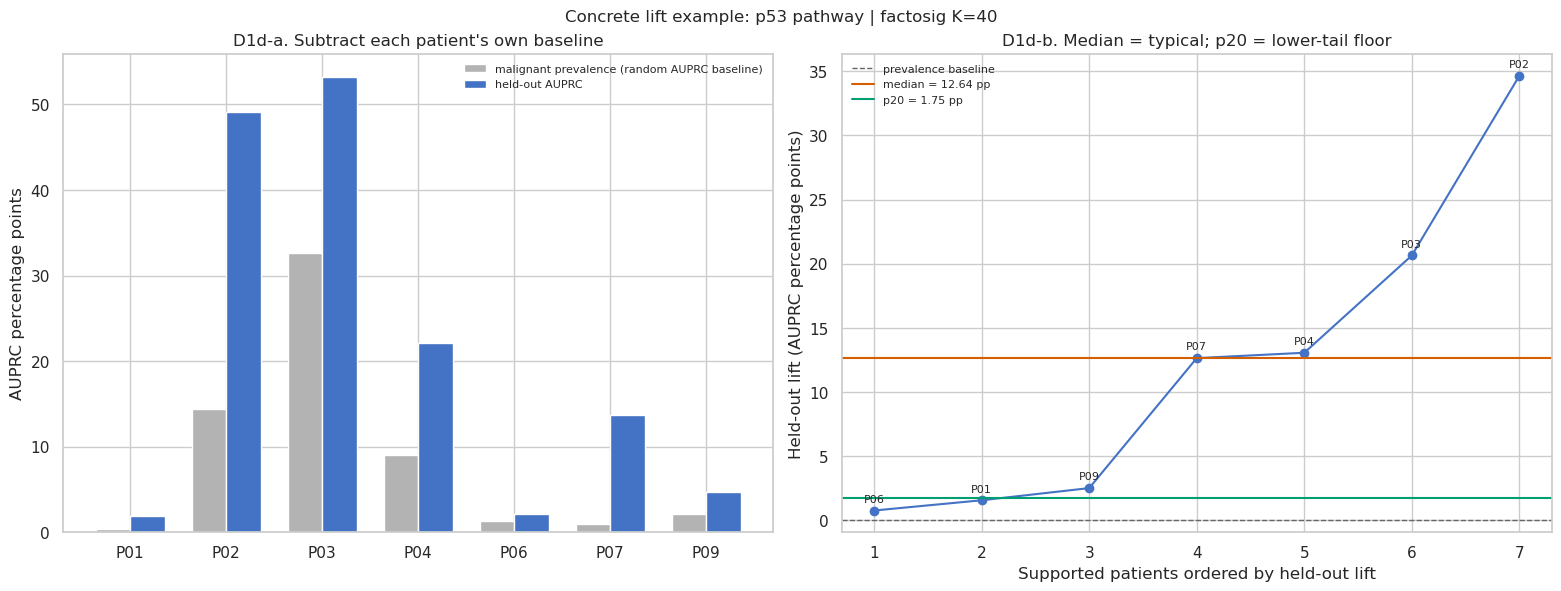

(stage0_id                                        single_geneset__hallmark_p53_pathway
 stage0_panel_id                                  single_geneset__hallmark_p53_pathway
 short_panel_label                                                         p53 pathway
 biological_theme                                                                other
 stage1_method                                                                factosig
                                                          ...                         
 n_missing_genes                                                                    36
 gene_budget_type                                                     knowledge_single
 panel_label_with_genes                                              p53 pathway (164)
 configuration                                                           factosig|K=40
 regularization_selection_rule    single_global_regularization_selected_by_pooled_lopo
 Name: 295, Length: 66, dtype: object,
    

In [4]:
plot_concrete_patient_lift_example(
    representation, selected_patient_long,
    short_panel_label="p53 pathway",  # use an exact short_panel_label
    stage1_method="factosig",
    effective_k=40,
)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_lift_concrete_tnfa_signaling_via_nfkb_fa_K40.csv


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1d_concrete_patient_lift_tnfa_signaling_via_nfkb_fa_K40.png


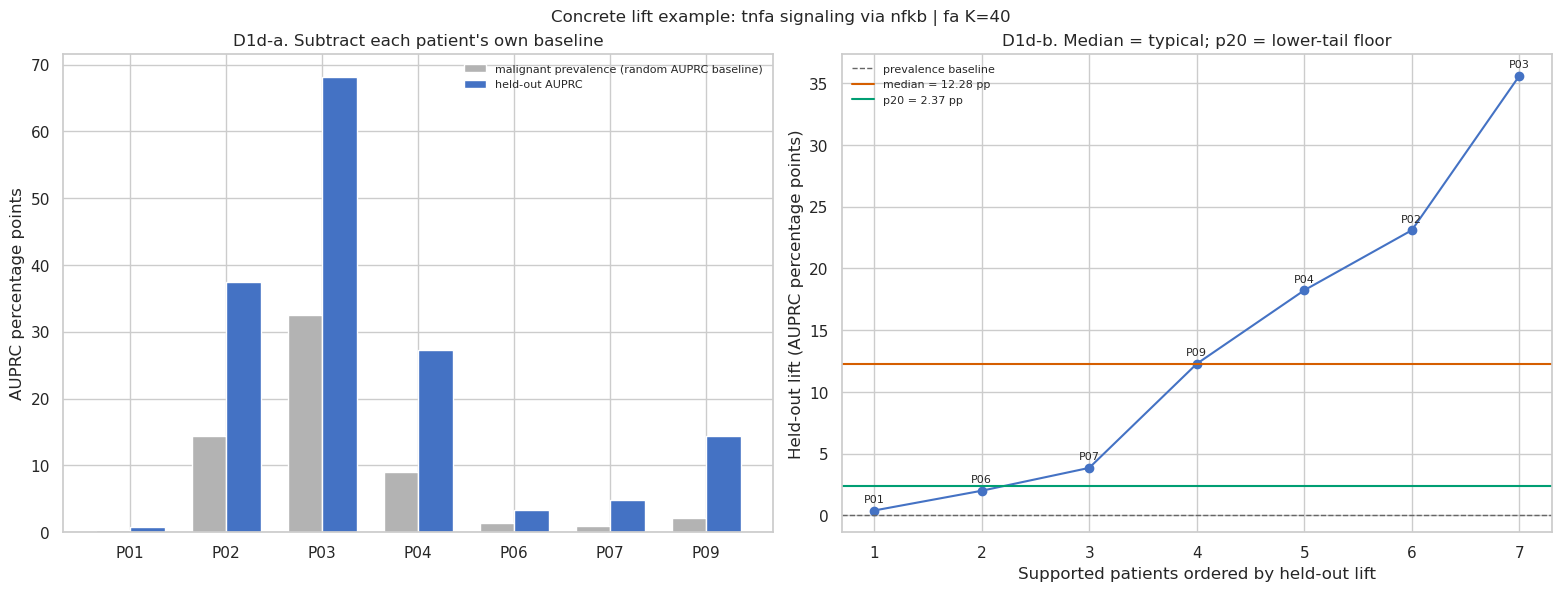

(stage0_id                            single_geneset__hallmark_tnfa_signaling_via_nfkb
 stage0_panel_id                      single_geneset__hallmark_tnfa_signaling_via_nfkb
 short_panel_label                                             tnfa signaling via nfkb
 biological_theme                                                             nfkb_tnf
 stage1_method                                                                      fa
                                                          ...                         
 n_missing_genes                                                                    28
 gene_budget_type                                                     knowledge_single
 panel_label_with_genes                                  tnfa signaling via nfkb (172)
 configuration                                                                 fa|K=40
 regularization_selection_rule    single_global_regularization_selected_by_pooled_lopo
 Name: 339, Length: 66, dtype: object,
    

In [5]:
plot_concrete_patient_lift_example(
    representation, selected_patient_long,
    short_panel_label="tnfa signaling via nfkb",  # use an exact short_panel_label
    stage1_method="fa",
    effective_k=40,
)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_lift_concrete_interferon_alpha_response_pca_K40.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1d_concrete_patient_lift_interferon_alpha_response_pca_K40.png


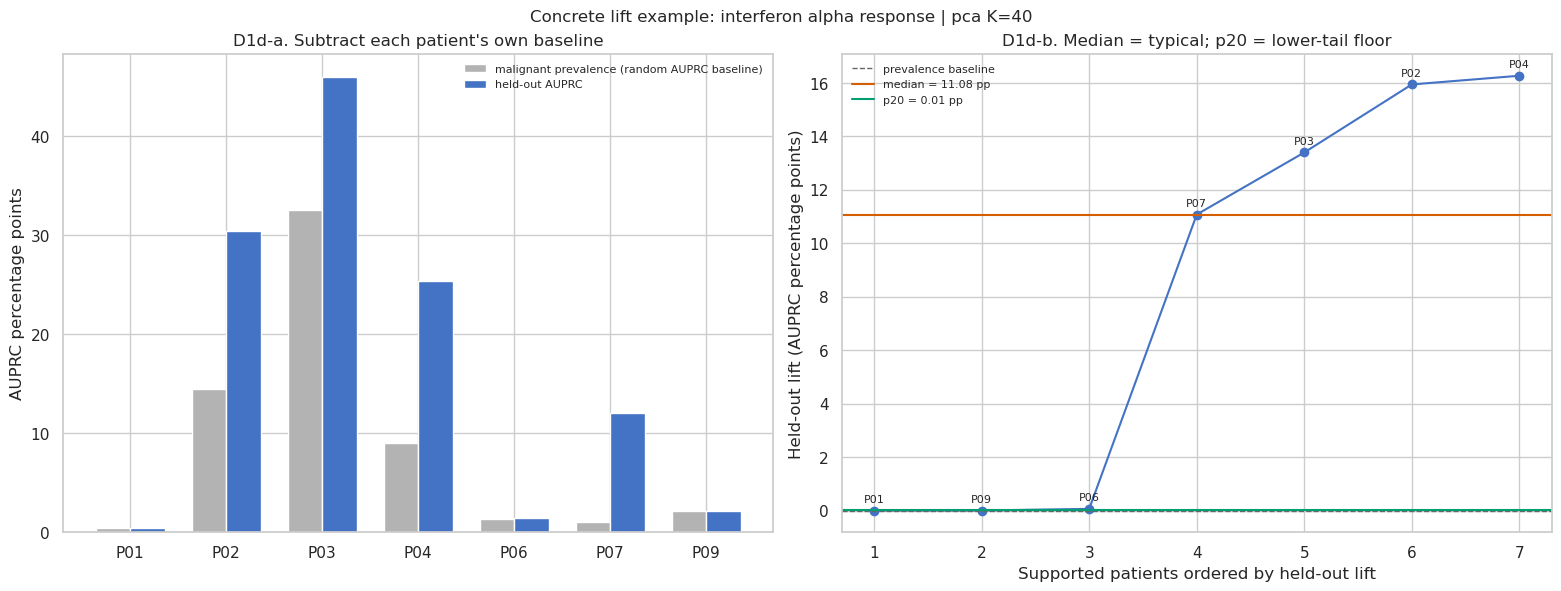

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_lift_concrete_interferon_alpha_response_fa_K40.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1d_concrete_patient_lift_interferon_alpha_response_fa_K40.png


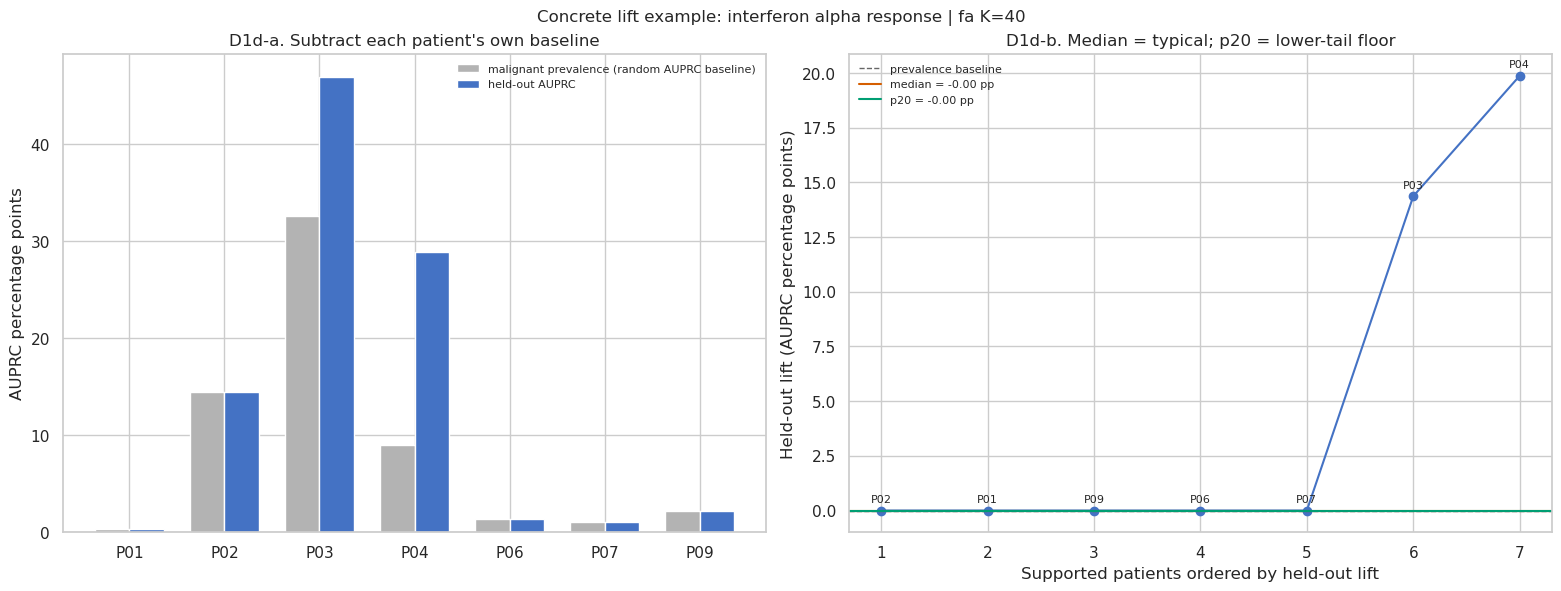

(stage0_id                          single_geneset__hallmark_interferon_alpha_response
 stage0_panel_id                    single_geneset__hallmark_interferon_alpha_response
 short_panel_label                                           interferon alpha response
 biological_theme                                                           interferon
 stage1_method                                                                      fa
                                                          ...                         
 n_missing_genes                                                                     5
 gene_budget_type                                                     knowledge_single
 panel_label_with_genes                                 interferon alpha response (92)
 configuration                                                                 fa|K=40
 regularization_selection_rule    single_global_regularization_selected_by_pooled_lopo
 Name: 195, Length: 66, dtype: object,
    

In [6]:
plot_concrete_patient_lift_example(
    representation, selected_patient_long,
    short_panel_label="interferon alpha response",  # use an exact short_panel_label
    stage1_method="pca",
    effective_k=40,
)

plot_concrete_patient_lift_example(
    representation, selected_patient_long,
    short_panel_label="interferon alpha response",  # use an exact short_panel_label
    stage1_method="fa",
    effective_k=40,
)

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1e_patient_by_stage0_best_dr_vs_direct_gene.png


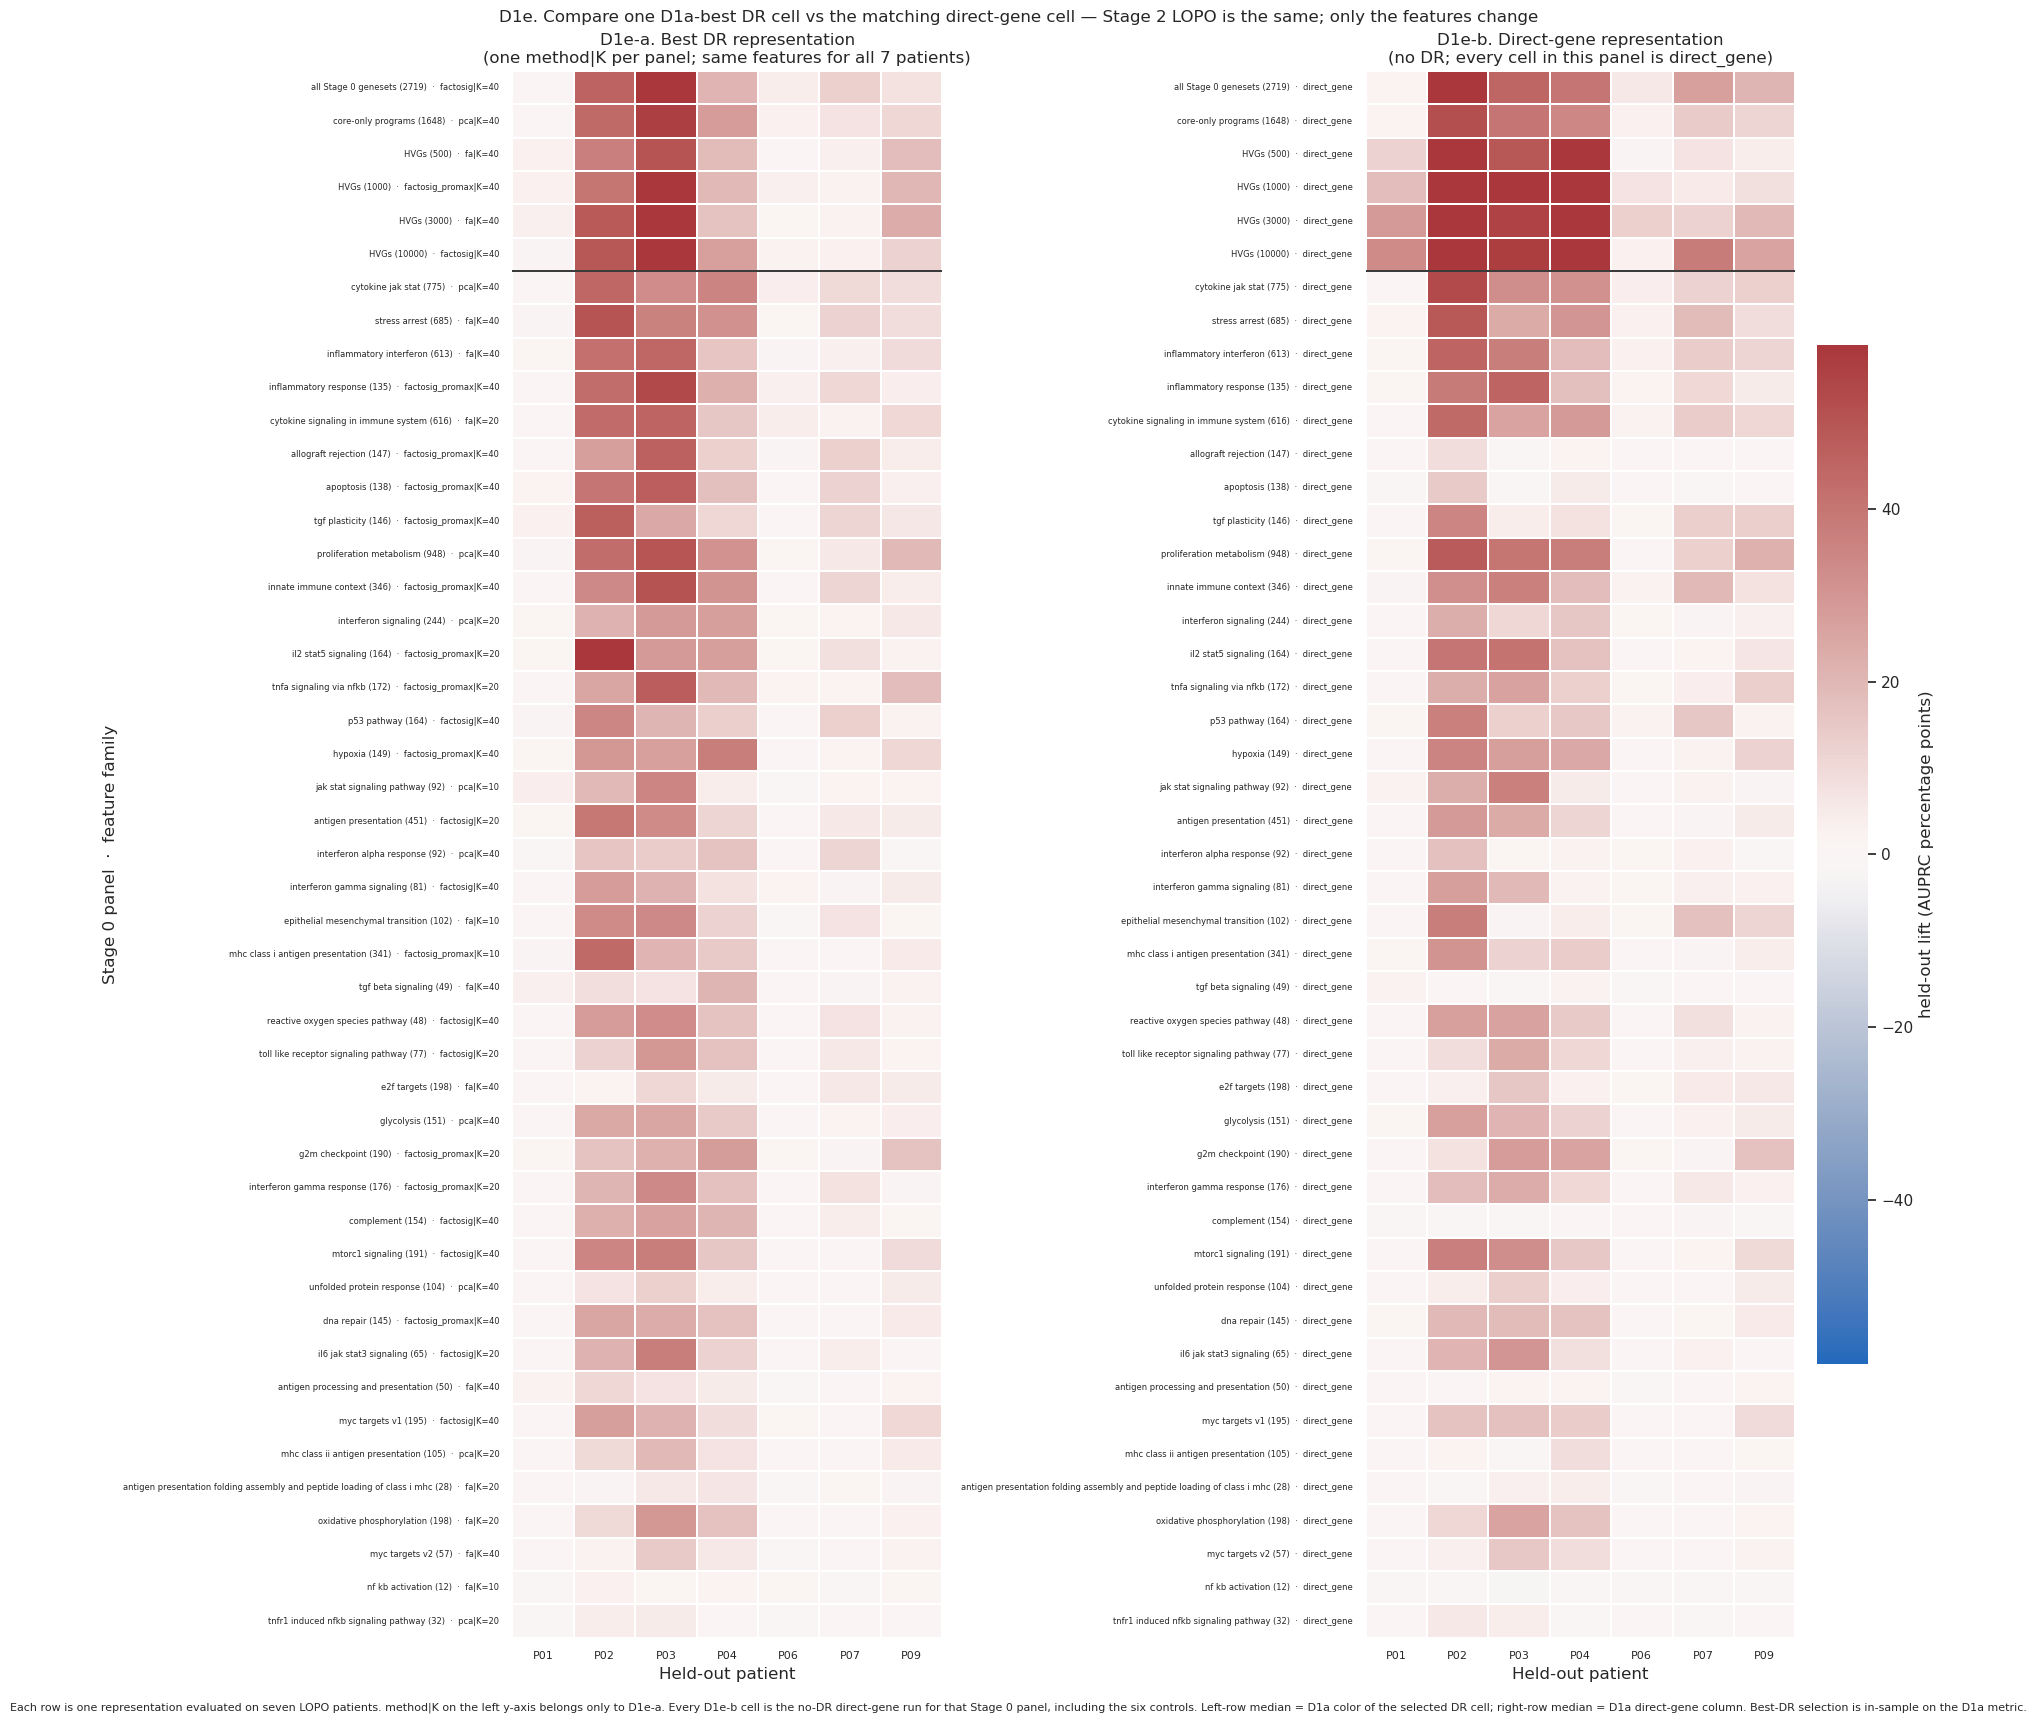

Best-DR rows: 47; median lift > 0: 47/47.
Direct-gene rows: 47/47 filled; median lift > 0: 45/47.
Best DR > direct-gene on D1a median lift: 30/47 comparable panels.
Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_d1e_best_dr_vs_direct_gene_selection.csv


,panel_label_with_genes,best_dr_configuration,best_dr_median_lift,direct_median_lift,dr_minus_direct_median_lift
0,all Stage 0 genesets (2719),factosig|K=40,0.128787,0.271398,-0.142611
1,core-only programs (1648),pca|K=40,0.106743,0.139651,-0.032908
2,HVGs (500),fa|K=40,0.183411,0.122279,0.061132
3,HVGs (1000),factosig_promax|K=40,0.196679,0.182729,0.013950
4,HVGs (3000),fa|K=40,0.165467,0.285706,-0.120238
5,HVGs (10000),factosig|K=40,0.119244,0.378989,-0.259745
6,cytokine jak stat (775),pca|K=40,0.098944,0.128696,-0.029752
7,stress arrest (685),fa|K=40,0.123347,0.186741,-0.063395
8,inflammatory interferon (613),fa|K=40,0.094596,0.134036,-0.039440
9,inflammatory response (135),factosig_promax|K=40,0.108627,0.104273,0.004354


In [7]:
# D1e: patient × Stage 0 lifts for the best-DR cell vs the matching direct-gene cell.
# Best DR = highest D1a patient_median_lift within the panel (ties: p20, then configuration).
# Left-row median = D1a color of that DR cell; right-row median = D1a direct_gene color.
# method|K is a left y-axis annotation only. Direct-gene includes the 6 Stage 0 controls.
PATIENT_ORDER = ["P01", "P02", "P03", "P04", "P06", "P07", "P09"]

dr_atlas = atlas_representation.loc[atlas_representation["stage1_method"].ne("direct_gene")].copy()
best_dr_by_panel = (
    dr_atlas.sort_values(
        ["patient_median_lift", "patient_p20_lift", "configuration"],
        ascending=[False, False, True],
    )
    .drop_duplicates("stage0_panel_id", keep="first")
    .copy()
)
assert best_dr_by_panel["stage0_panel_id"].nunique() == N_D1_PANELS
assert len(best_dr_by_panel) == N_D1_PANELS

best_dr_patients = atlas_selected_patient_long.merge(
    best_dr_by_panel[["representation_id", "stage0_panel_id", "configuration", "patient_median_lift", "patient_p20_lift"]],
    on=["representation_id", "stage0_panel_id"],
    how="inner",
    validate="many_to_one",
)
assert len(best_dr_patients) == N_D1_PANELS * 7

direct_atlas = atlas_representation.loc[atlas_representation["configuration"].eq("direct_gene")].copy()
assert len(direct_atlas) == N_D1_DIRECT_GENE
direct_patients = atlas_selected_patient_long.loc[
    atlas_selected_patient_long["configuration"].eq("direct_gene")
].copy()
assert len(direct_patients) == N_D1_DIRECT_GENE * 7

best_dr_matrix = (
    best_dr_patients.pivot(
        index="panel_label_with_genes",
        columns="heldout_patient",
        values="heldout_lift",
    )
    .reindex(index=panel_order, columns=PATIENT_ORDER)
)
direct_matrix = (
    direct_patients.pivot(
        index="panel_label_with_genes",
        columns="heldout_patient",
        values="heldout_lift",
    )
    .reindex(index=panel_order, columns=PATIENT_ORDER)
)
assert best_dr_matrix.notna().all().all()
assert direct_matrix.notna().all().all()

# The median of each left row must recover the D1a color of the selected DR cell.
selected_median = best_dr_by_panel.set_index("panel_label_with_genes")["patient_median_lift"].reindex(panel_order)
assert np.allclose(best_dr_matrix.median(axis=1), selected_median, equal_nan=True)
direct_selected_median = direct_atlas.set_index("panel_label_with_genes")["patient_median_lift"].reindex(panel_order)
assert np.allclose(direct_matrix.median(axis=1), direct_selected_median, equal_nan=True)

config_by_panel = best_dr_by_panel.set_index("panel_label_with_genes")["configuration"].reindex(panel_order)
selection_table = (
    best_dr_by_panel[
        [
            "stage0_panel_id",
            "panel_label_with_genes",
            "atlas_row_block",
            "representation_id",
            "configuration",
            "stage1_method",
            "effective_k",
            "patient_median_lift",
            "patient_p20_lift",
        ]
    ]
    .rename(
        columns={
            "representation_id": "best_dr_representation_id",
            "configuration": "best_dr_configuration",
            "stage1_method": "best_dr_method",
            "effective_k": "best_dr_k",
            "patient_median_lift": "best_dr_median_lift",
            "patient_p20_lift": "best_dr_p20_lift",
        }
    )
    .merge(
        direct_atlas[
            ["stage0_panel_id", "representation_id", "patient_median_lift", "patient_p20_lift"]
        ].rename(
            columns={
                "representation_id": "direct_representation_id",
                "patient_median_lift": "direct_median_lift",
                "patient_p20_lift": "direct_p20_lift",
            }
        ),
        on="stage0_panel_id",
        how="left",
        validate="one_to_one",
    )
)
selection_table["dr_minus_direct_median_lift"] = (
    selection_table["best_dr_median_lift"] - selection_table["direct_median_lift"]
)
selection_table = selection_table.set_index("panel_label_with_genes").loc[panel_order].reset_index()
d1e_selection_path = TABLE_DIR / "old34_d1e_best_dr_vs_direct_gene_selection.csv"
best_dr_matrix_path = TABLE_DIR / "old34_d1e_best_dr_patient_lift_matrix.csv"
direct_matrix_path = TABLE_DIR / "old34_d1e_direct_gene_patient_lift_matrix.csv"
selection_table.to_csv(d1e_selection_path, index=False)
best_dr_matrix.to_csv(best_dr_matrix_path)
direct_matrix.to_csv(direct_matrix_path)

best_dr_plot = 100 * best_dr_matrix
direct_plot = 100 * direct_matrix
lift_values = np.concatenate([best_dr_plot.to_numpy().ravel(), direct_plot.to_numpy().ravel()])
lift_values = lift_values[np.isfinite(lift_values)]
d1e_vmax = max(float(np.quantile(np.abs(lift_values), 0.98)), 3.0)
d1e_cmap = plt.get_cmap("vlag").copy()
d1e_cmap.set_bad("#d9d9d9")

left_yticklabels = [
    f"{name}  ·  {cfg}" for name, cfg in zip(panel_order, config_by_panel.tolist())
]
right_yticklabels = [f"{name}  ·  direct_gene" for name in panel_order]

fig, axes = plt.subplots(1, 2, figsize=(18.4, 16.8), sharey=False, constrained_layout=True)
for ax, matrix, title, yticklabels in [
    (
        axes[0],
        best_dr_plot,
        "D1e-a. Best DR representation\n(one method|K per panel; same features for all 7 patients)",
        left_yticklabels,
    ),
    (
        axes[1],
        direct_plot,
        "D1e-b. Direct-gene representation\n(no DR; every cell in this panel is direct_gene)",
        right_yticklabels,
    ),
]:
    sns.heatmap(
        matrix,
        cmap=d1e_cmap,
        center=0,
        vmin=-d1e_vmax,
        vmax=d1e_vmax,
        linewidths=0.18,
        linecolor="white",
        yticklabels=yticklabels,
        cbar=ax is axes[1],
        cbar_kws={"label": "held-out lift (AUPRC percentage points)", "shrink": 0.65} if ax is axes[1] else None,
        ax=ax,
    )
    ax.axhline(len(control_labels), color="black", lw=1.1)
    ax.set_title(title)
    ax.set_xlabel("Held-out patient")
    ax.set_ylabel("Stage 0 panel  ·  feature family" if ax is axes[0] else "")
    ax.tick_params(axis="y", labelsize=6.0)
    ax.tick_params(axis="x", labelsize=8, rotation=0)

fig.suptitle(
    "D1e. Compare one D1a-best DR cell vs the matching direct-gene cell — "
    "Stage 2 LOPO is the same; only the features change",
    fontsize=12,
)
fig.text(
    0.5,
    -0.01,
    "Each row is one representation evaluated on seven LOPO patients. "
    "method|K on the left y-axis belongs only to D1e-a. "
    "Every D1e-b cell is the no-DR direct-gene run for that Stage 0 panel, including the six controls. "
    "Left-row median = D1a color of the selected DR cell; right-row median = D1a direct-gene column. "
    "Best-DR selection is in-sample on the D1a metric.",
    ha="center",
    va="top",
    fontsize=8,
)
save_figure(fig, "D1e_patient_by_stage0_best_dr_vs_direct_gene")
d1e_figure_png = FIGURE_DIR / "D1e_patient_by_stage0_best_dr_vs_direct_gene.png"
plt.show()

n_best_dr_median_positive = int(selection_table["best_dr_median_lift"].gt(0).sum())
n_direct_median_positive = int(selection_table["direct_median_lift"].gt(0).sum())
n_comparable = int(selection_table["direct_median_lift"].notna().sum())
n_best_dr_beats_direct = int(
    (selection_table["dr_minus_direct_median_lift"] > 0).sum()
)
print(
    f"Best-DR rows: {len(selection_table)}; median lift > 0: {n_best_dr_median_positive}/{N_D1_PANELS}."
)
print(
    f"Direct-gene rows: {n_comparable}/{N_D1_PANELS} filled; "
    f"median lift > 0: {n_direct_median_positive}/{n_comparable}."
)
print(
    f"Best DR > direct-gene on D1a median lift: {n_best_dr_beats_direct}/{n_comparable} comparable panels."
)
print("Wrote", d1e_selection_path)
display(
    selection_table[
        [
            "panel_label_with_genes",
            "best_dr_configuration",
            "best_dr_median_lift",
            "direct_median_lift",
            "dr_minus_direct_median_lift",
        ]
    ].head(12)
)

### D1f code — patient-count atlases (does not replace D1a/b)

Same Stage 0 × Stage 1 grid as D1a. Color = number of supported patients (0–7) whose held-out score clears the cutoff. Gray = structurally unavailable.

Edit the two threshold lists in the next cell and re-run only that cell. `lift > 0` equals `AUPRC / prevalence > 1`, so the lift pair starts at 0 and 5 points rather than repeating the ratio-1 map.


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1f_lift_threshold_patient_counts.png


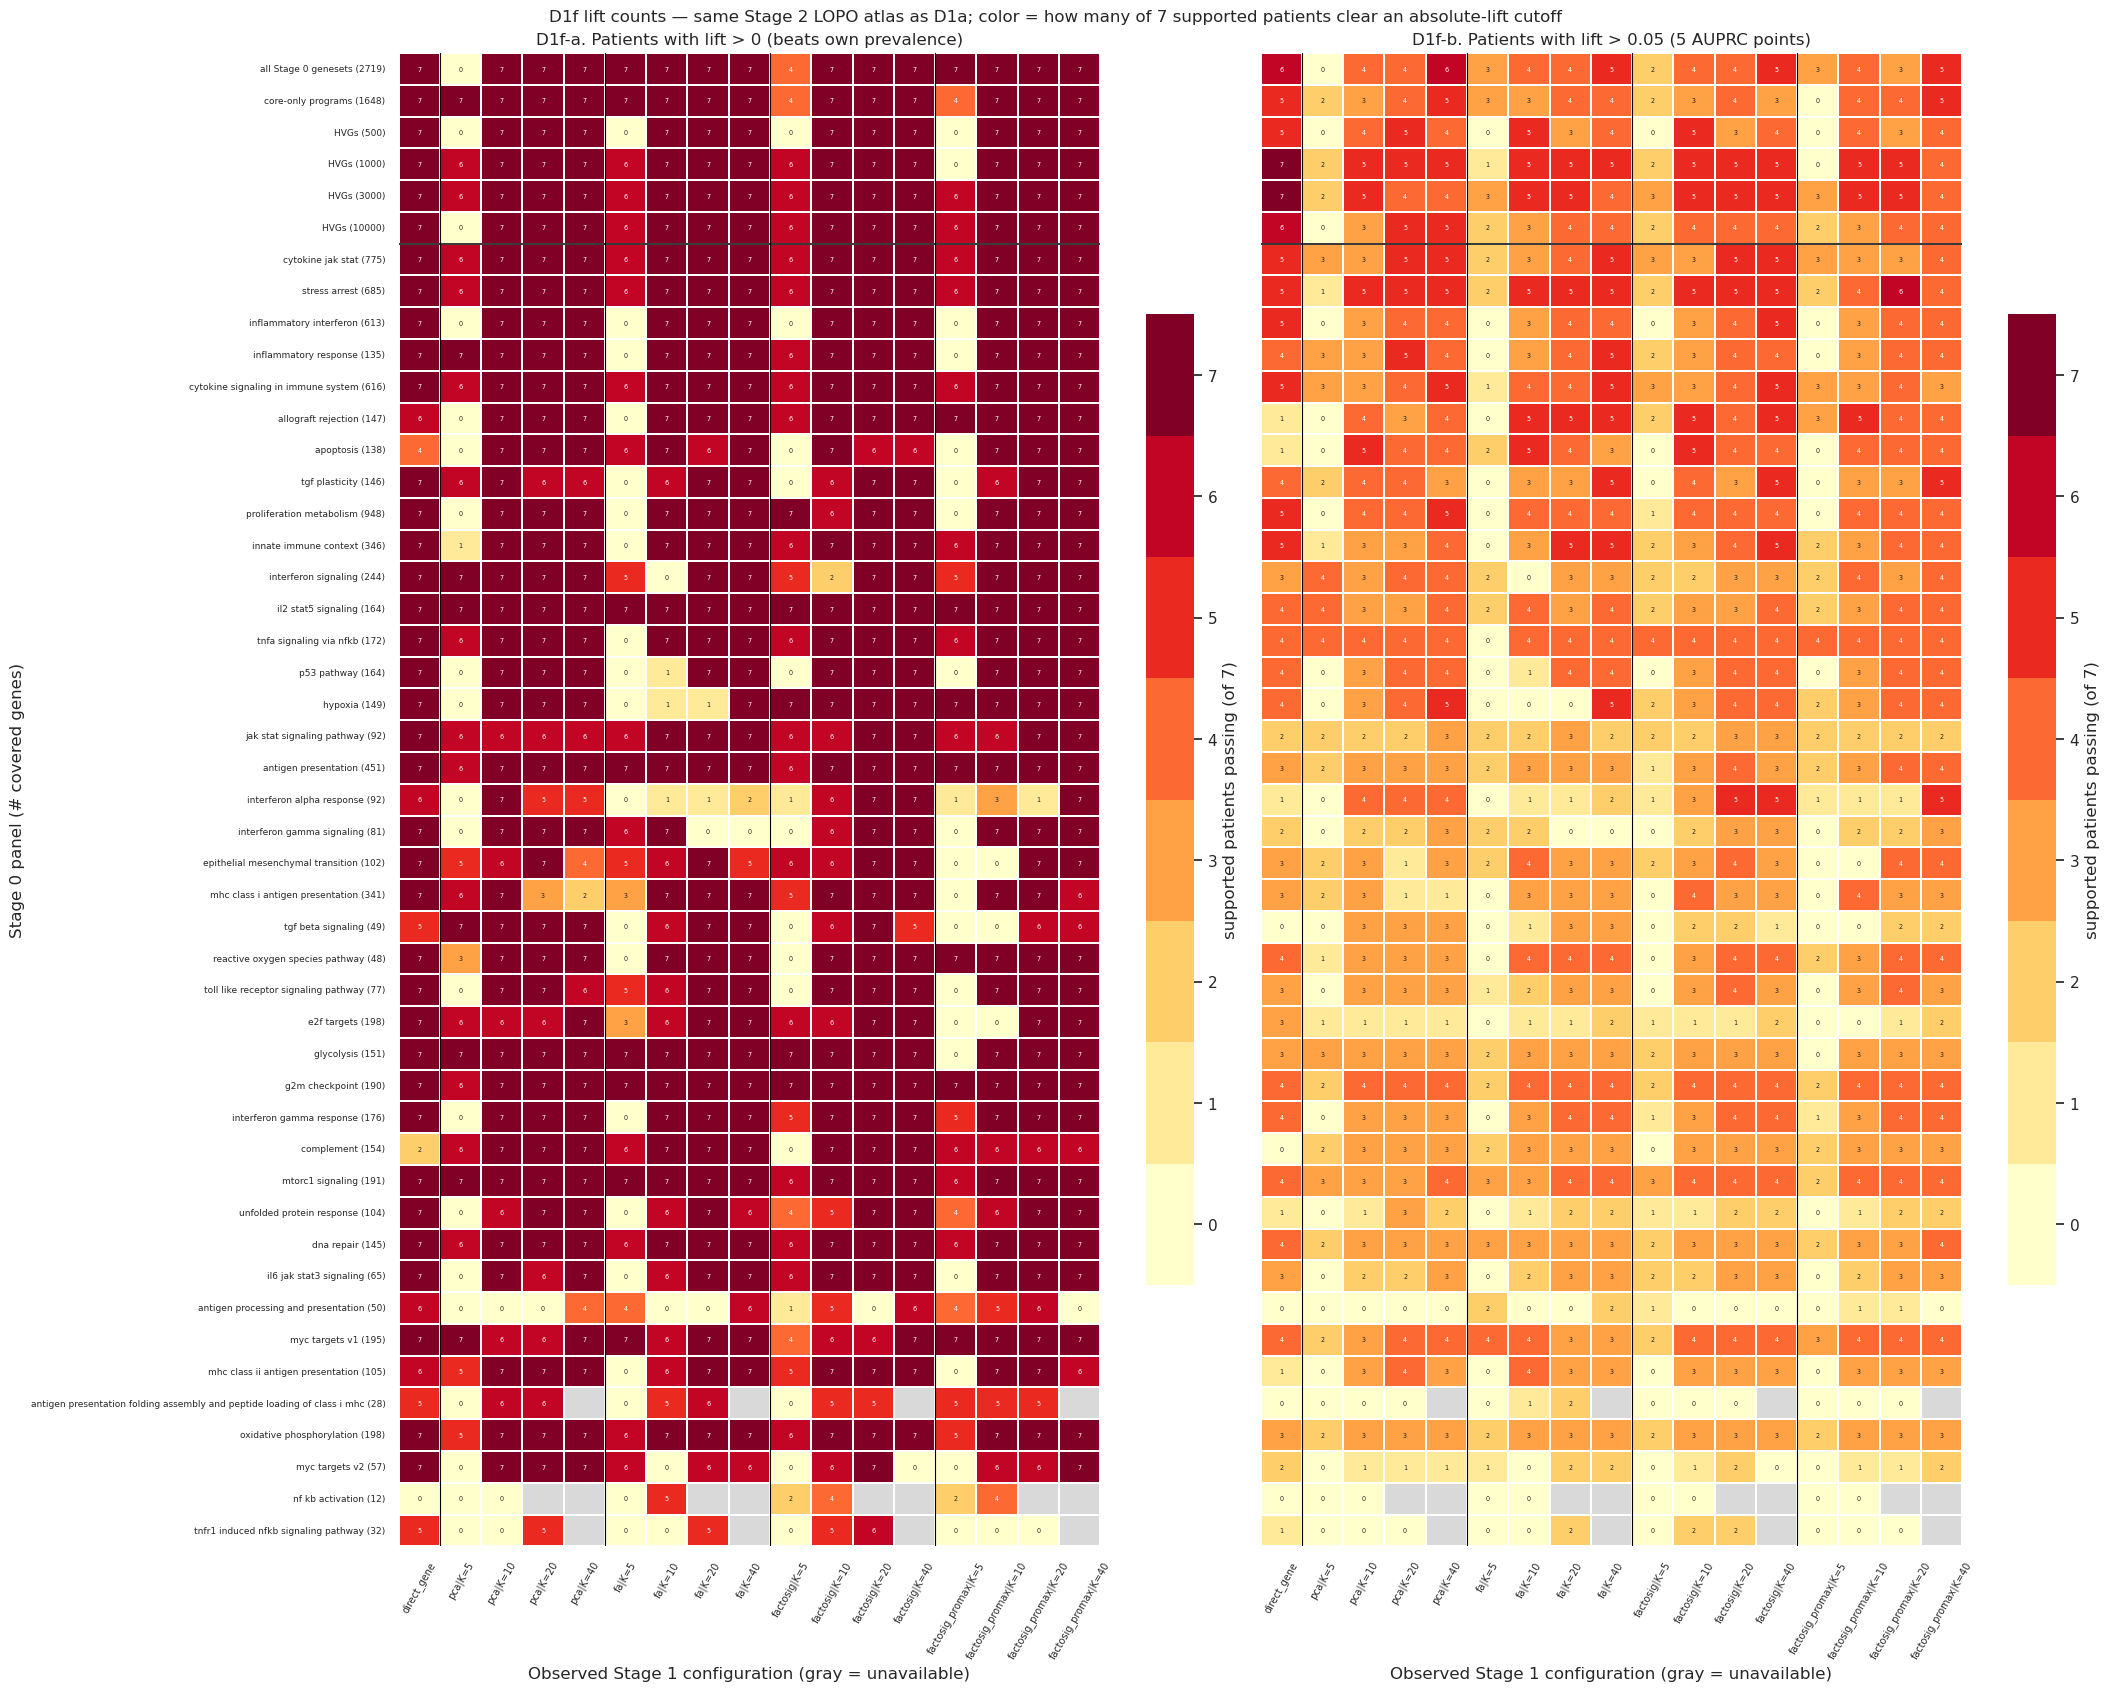

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1f_ratio_threshold_patient_counts.png


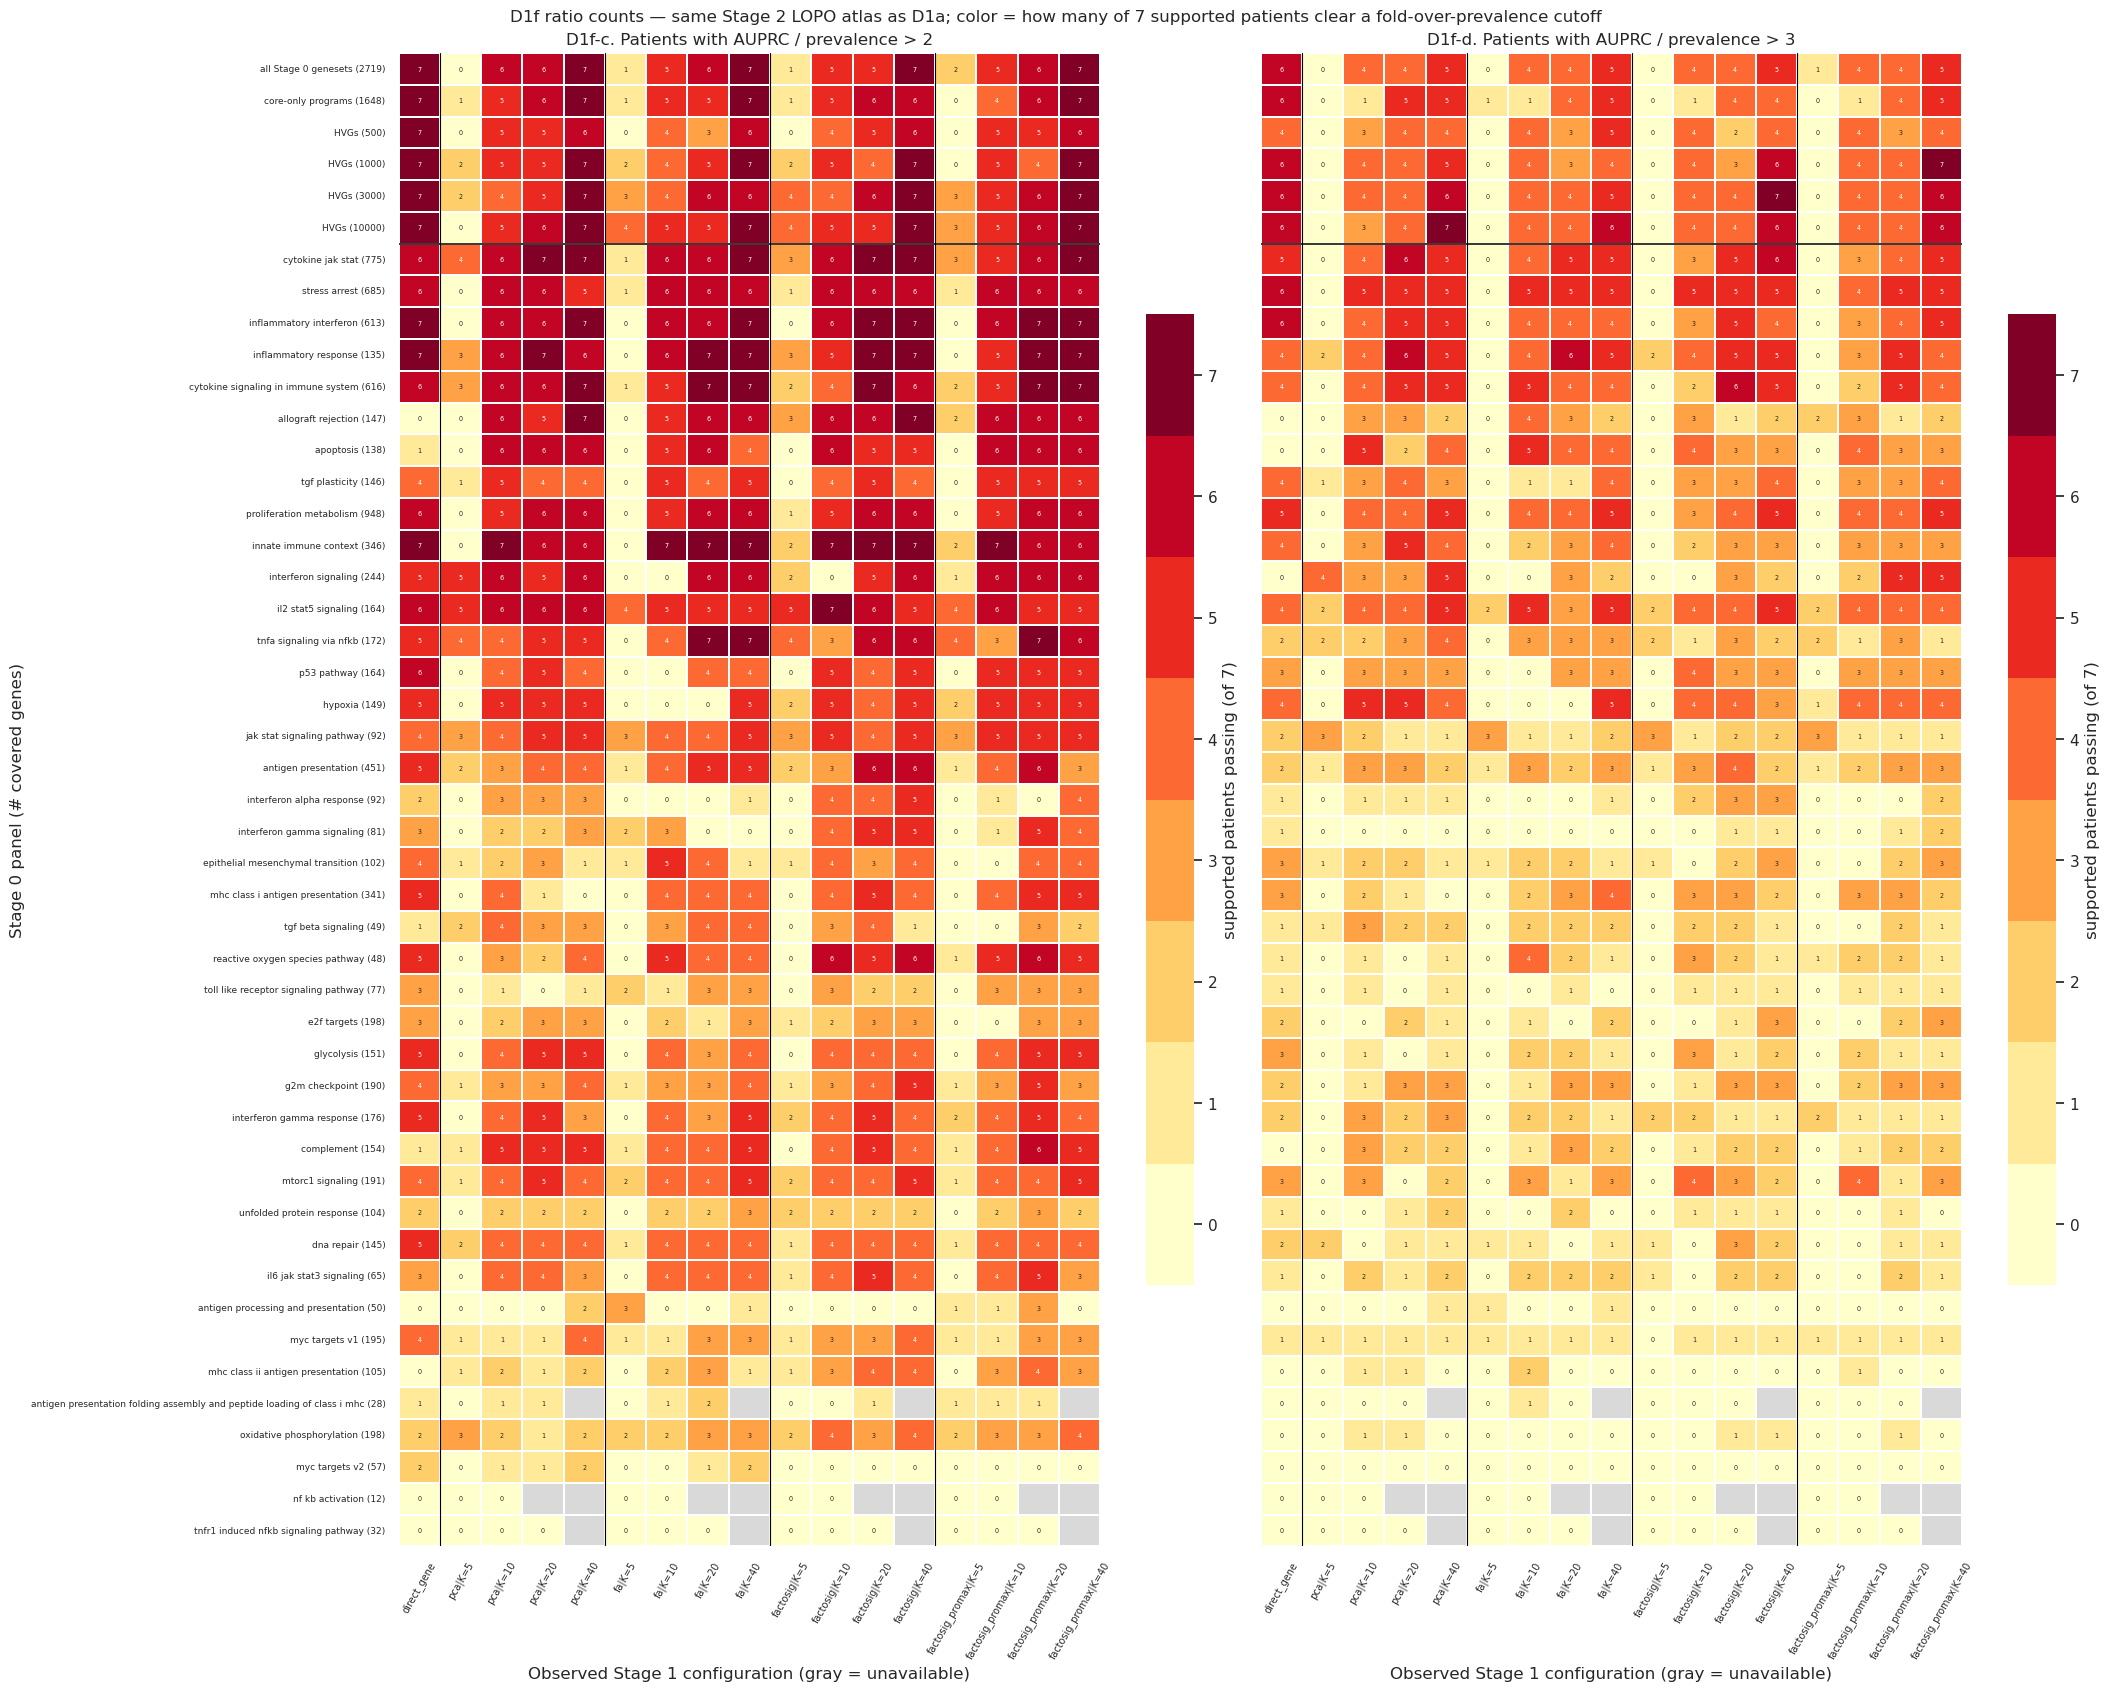

lift > 0 is the same event as AUPRC / prevalence > 1; the 0-lift panel is that shared map.
Absolute 5-point lift is mostly P02/P03/P04; a 2× ratio is easier for rare patients.


,heldout_patient,prevalence,n_malignant,n_normal,auprc_needed_for_lift_gt_0.05,auprc_needed_for_ratio_gt_2,frac_reps_lift_gt_0,frac_reps_lift_gt_0.05,frac_reps_ratio_gt_2,frac_reps_ratio_gt_3
0,P01,0.0038,45,11815,0.0538,0.0076,0.8391,0.0370,0.6922,0.4240
1,P02,0.1443,211,1251,0.1943,0.2886,0.8135,0.7420,0.5683,0.3538
2,P03,0.3257,758,1569,0.3757,0.6515,0.8506,0.8097,0.2810,0.0140
3,P04,0.0904,102,1026,0.1404,0.1809,0.8557,0.6679,0.5594,0.3295
4,P06,0.0135,44,3215,0.0635,0.0270,0.7190,0.0128,0.1469,0.0626
5,P07,0.0101,22,2163,0.0601,0.0201,0.8327,0.1686,0.5607,0.3716
6,P09,0.0219,375,16751,0.0719,0.0438,0.8416,0.2899,0.6092,0.3589


,threshold_id,n_observed_cells,mean_patients_passing,median_patients_passing,n_cells_with_at_least_4,n_cells_with_at_least_5,n_cells_with_all_7
0,lift_gt_0,783,5.752,7.0,670,657,506
1,lift_gt_0.05,783,2.728,3.0,281,84,2
2,ratio_gt_2,783,3.418,4.0,426,298,66
3,ratio_gt_3,783,1.914,2.0,187,81,3


Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1f_lift_threshold_patient_counts.png
Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D1f_ratio_threshold_patient_counts.png
Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_d1f_patient_threshold_guide.csv
Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_d1f_threshold_count_summary.csv
Re-run this cell after editing D1F_LIFT_THRESHOLDS or D1F_RATIO_THRESHOLDS.


In [8]:
# D1f: count how many of the seven supported patients clear a cutoff.
# Same Stage 2 LOPO / frozen regularizer as D1a. Does not rewrite D1a/b figures.
#
# Edit the threshold lists and re-run this cell.
# lift uses AUPRC minus that patient's prevalence (fraction, not percentage points).
# ratio uses held-out AUPRC / that patient's malignant prevalence.
# lift > 0 is the same event as ratio > 1.
D1F_LIFT_THRESHOLDS = [0.0, 0.05]  # 0 and 5 AUPRC percentage points
D1F_RATIO_THRESHOLDS = [2.0, 3.0]
D1F_ANNOTATE = True


def d1f_panel_order(atlas_representation: pd.DataFrame) -> tuple[list[str], list[str]]:
    labels = control_row_labels(atlas_representation)
    bio_order = (
        atlas_representation.loc[atlas_representation["atlas_row_block"].eq("biological")]
        .groupby("panel_label_with_genes", dropna=False)
        .agg(
            best_p20_lift=("patient_p20_lift", "max"),
            best_median_lift=("patient_median_lift", "max"),
            median_across_representations=("patient_median_lift", "median"),
        )
        .sort_values(
            ["best_p20_lift", "best_median_lift", "median_across_representations"],
            ascending=False,
        )
        .index.tolist()
    )
    order = labels + bio_order
    assert set(order) == set(atlas_representation["panel_label_with_genes"])
    assert len(order) == N_D1_PANELS
    return labels, order


def count_patients_passing_threshold(
    patient_long: pd.DataFrame,
    *,
    kind: str,
    threshold: float,
    row_order: list[str],
    col_order: list[str],
) -> pd.DataFrame:
    work = patient_long.copy()
    n_per_cell = work.groupby(["panel_label_with_genes", "configuration"], dropna=False).size()
    assert n_per_cell.eq(7).all(), n_per_cell.value_counts().to_dict()
    if kind == "lift":
        work["passes"] = work["heldout_lift"] > threshold
    elif kind == "ratio":
        work["passes"] = (work["heldout_auprc"] / work["patient_prevalence"]) > threshold
    else:
        raise ValueError(f"kind must be 'lift' or 'ratio', got {kind!r}")
    counts = (
        work.groupby(["panel_label_with_genes", "configuration"], dropna=False)["passes"]
        .sum()
        .unstack("configuration")
        .reindex(index=row_order, columns=col_order)
    )
    finite = counts.to_numpy()[np.isfinite(counts.to_numpy())]
    assert finite.min() >= 0 and finite.max() <= 7
    return counts


def plot_d1f_count_pair(
    panels: list[tuple[pd.DataFrame, str]],
    *,
    stem: str,
    suptitle: str,
    control_n: int,
) -> Path:
    cmap = plt.get_cmap("YlOrRd", 8).copy()
    cmap.set_bad("#d9d9d9")
    fig, axes = plt.subplots(1, 2, figsize=(21, 16.8), sharey=True, constrained_layout=True)
    for ax, (matrix, title) in zip(axes, panels):
        sns.heatmap(
            matrix,
            cmap=cmap,
            vmin=-0.5,
            vmax=7.5,
            annot=D1F_ANNOTATE,
            fmt=".0f",
            annot_kws={"size": 4.6},
            linewidths=0.18,
            linecolor="white",
            cbar_kws={
                "label": "supported patients passing (of 7)",
                "ticks": list(range(8)),
                "shrink": 0.65,
            },
            ax=ax,
        )
        for boundary in [1, 5, 9, 13]:
            ax.axvline(boundary, color="black", lw=0.8)
        ax.axhline(control_n, color="black", lw=1.1)
        ax.set_title(title)
        ax.set_xlabel("Observed Stage 1 configuration (gray = unavailable)")
        ax.set_ylabel("Stage 0 panel (# covered genes)" if ax is axes[0] else "")
        ax.tick_params(axis="y", labelsize=6.5)
        ax.tick_params(axis="x", labelsize=7, rotation=60)
    fig.suptitle(suptitle, fontsize=12)
    save_figure(fig, stem)
    plt.show()
    return FIGURE_DIR / f"{stem}.png"


d1f_control_labels, d1f_row_order = d1f_panel_order(atlas_representation)
if "panel_order" in globals():
    assert d1f_row_order == list(panel_order)

assert (
    atlas_selected_patient_long["heldout_lift"].gt(0)
    != (atlas_selected_patient_long["heldout_auprc"] / atlas_selected_patient_long["patient_prevalence"]).gt(1)
).sum() == 0

lift_specs = [("lift", float(thr)) for thr in D1F_LIFT_THRESHOLDS]
ratio_specs = [("ratio", float(thr)) for thr in D1F_RATIO_THRESHOLDS]
assert len(lift_specs) == 2, "This cell draws one 1x2 figure per family; keep two lift cutoffs."
assert len(ratio_specs) == 2, "This cell draws one 1x2 figure per family; keep two ratio cutoffs."

d1f_matrices: dict[str, pd.DataFrame] = {}
for kind, threshold in lift_specs + ratio_specs:
    key = f"{kind}_gt_{threshold:g}"
    d1f_matrices[key] = count_patients_passing_threshold(
        atlas_selected_patient_long,
        kind=kind,
        threshold=threshold,
        row_order=d1f_row_order,
        col_order=CONFIG_ORDER,
    )
    d1f_matrices[key].to_csv(TABLE_DIR / f"old34_d1f_{key}_patient_count_matrix.csv")

lift_left_thr, lift_right_thr = D1F_LIFT_THRESHOLDS
ratio_left_thr, ratio_right_thr = D1F_RATIO_THRESHOLDS
d1f_lift_png = plot_d1f_count_pair(
    [
        (
            d1f_matrices[f"lift_gt_{float(lift_left_thr):g}"],
            f"D1f-a. Patients with lift > {float(lift_left_thr):g}"
            + (" (beats own prevalence)" if float(lift_left_thr) == 0 else f" ({100 * float(lift_left_thr):.0f} AUPRC points)"),
        ),
        (
            d1f_matrices[f"lift_gt_{float(lift_right_thr):g}"],
            f"D1f-b. Patients with lift > {float(lift_right_thr):g}"
            + (" (beats own prevalence)" if float(lift_right_thr) == 0 else f" ({100 * float(lift_right_thr):.0f} AUPRC points)"),
        ),
    ],
    stem="D1f_lift_threshold_patient_counts",
    suptitle=(
        "D1f lift counts — same Stage 2 LOPO atlas as D1a; "
        "color = how many of 7 supported patients clear an absolute-lift cutoff"
    ),
    control_n=len(d1f_control_labels),
)
d1f_ratio_png = plot_d1f_count_pair(
    [
        (
            d1f_matrices[f"ratio_gt_{float(ratio_left_thr):g}"],
            f"D1f-c. Patients with AUPRC / prevalence > {float(ratio_left_thr):g}",
        ),
        (
            d1f_matrices[f"ratio_gt_{float(ratio_right_thr):g}"],
            f"D1f-d. Patients with AUPRC / prevalence > {float(ratio_right_thr):g}",
        ),
    ],
    stem="D1f_ratio_threshold_patient_counts",
    suptitle=(
        "D1f ratio counts — same Stage 2 LOPO atlas as D1a; "
        "color = how many of 7 supported patients clear a fold-over-prevalence cutoff"
    ),
    control_n=len(d1f_control_labels),
)

patient_floors = (
    atlas_selected_patient_long.groupby("heldout_patient", sort=True)
    .agg(
        prevalence=("patient_prevalence", "first"),
        n_malignant=("n_malignant_h", "first"),
        n_normal=("n_normal_h", "first"),
    )
    .reset_index()
)
patient_floors["auprc_needed_for_lift_gt_0.05"] = patient_floors["prevalence"] + 0.05
patient_floors["auprc_needed_for_ratio_gt_2"] = 2.0 * patient_floors["prevalence"]
work = atlas_selected_patient_long.assign(
    ratio=atlas_selected_patient_long["heldout_auprc"] / atlas_selected_patient_long["patient_prevalence"]
)
pass_rate = (
    work.groupby("heldout_patient", sort=True)
    .agg(
        frac_reps_lift_gt_0=("heldout_lift", lambda s: float(s.gt(0).mean())),
        frac_reps_lift_gt_0p05=("heldout_lift", lambda s: float(s.gt(0.05).mean())),
        frac_reps_ratio_gt_2=("ratio", lambda s: float(s.gt(2).mean())),
        frac_reps_ratio_gt_3=("ratio", lambda s: float(s.gt(3).mean())),
    )
    .reset_index()
    .rename(columns={"frac_reps_lift_gt_0p05": "frac_reps_lift_gt_0.05"})
)
patient_threshold_guide = patient_floors.merge(pass_rate, on="heldout_patient", validate="one_to_one")
patient_threshold_guide_path = TABLE_DIR / "old34_d1f_patient_threshold_guide.csv"
patient_threshold_guide.to_csv(patient_threshold_guide_path, index=False)

count_summary_rows = []
for key, matrix in d1f_matrices.items():
    vals = matrix.to_numpy()
    finite = vals[np.isfinite(vals)]
    count_summary_rows.append(
        {
            "threshold_id": key,
            "n_observed_cells": int(finite.size),
            "mean_patients_passing": float(finite.mean()),
            "median_patients_passing": float(np.median(finite)),
            "n_cells_with_at_least_4": int((finite >= 4).sum()),
            "n_cells_with_at_least_5": int((finite >= 5).sum()),
            "n_cells_with_all_7": int((finite == 7).sum()),
        }
    )
d1f_count_summary = pd.DataFrame(count_summary_rows)
d1f_count_summary_path = TABLE_DIR / "old34_d1f_threshold_count_summary.csv"
d1f_count_summary.to_csv(d1f_count_summary_path, index=False)

print("lift > 0 is the same event as AUPRC / prevalence > 1; the 0-lift panel is that shared map.")
print("Absolute 5-point lift is mostly P02/P03/P04; a 2× ratio is easier for rare patients.")
display(patient_threshold_guide.round(4))
display(d1f_count_summary.round(3))
print("Wrote", d1f_lift_png)
print("Wrote", d1f_ratio_png)
print("Wrote", patient_threshold_guide_path)
print("Wrote", d1f_count_summary_path)
print("Re-run this cell after editing D1F_LIFT_THRESHOLDS or D1F_RATIO_THRESHOLDS.")


## 3. Canonical 41-row panel table and D2 robustness map

The canonical table retains three different objects that must not be conflated:

1. **primary pooled-LOPO selection** — reproduces the pre-existing V2F representation choice and is used for the provisional panel taxonomy;
2. **best-floor oracle sensitivity** (columns retain the `robust_q1_` prefix for continuity) — maximizes p20 transfer floor, then typical transfer, and shows what is attainable after searching the Stage 1 grid;
3. **panel extrema across all representations** — best discovery and best apparent patient-specific values, each with its own representation ID.

The best-floor result is valuable for diagnosis but is not an unbiased performance estimate: it selects and displays the same patient-summary outcome.

### D2 manuscript-plot contract

- **Scientific question:** Which prior gene spaces transfer robustly across Stage 1 choices rather than winning through one tuned representation?
- **Null hypothesis:** No Stage 1 configuration achieves positive 20th-percentile held-out lift; equivalently, the panel has no observed positive transfer floor over patient-specific prevalence.
- **In silico experiment:** Each point is one panel. x = percentage of observed representations with p20 lift > 0; y = the best observed p20 lift after searching the Stage 1 grid, expressed in AUPRC percentage points. Point color is the pre-existing method-stability label; point size is covered-gene count.
- **Scale:** y = `5` means the lower-tail AUPRC is **5 percentage points above each patient's prevalence after patient-level summarization**. It is not a 5% accuracy or sensitivity gain. The values look numerically small in decimal form because AUPRC lift is an additive probability-scale difference.
- **Results:** upper-right means both high attainable floor and broad modeling support. Upper-left means a strong but brittle winner. Lower-left means unresolved/null at this resolution.
- **Take-home boundary:** D2 distinguishes broad modeling support from a representation-specific win, but y is a searched maximum. It cannot reject the null without multiplicity-aware matched-size controls and uncertainty.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D2_old34_panel_transfer_floor_vs_representation_robustness.png


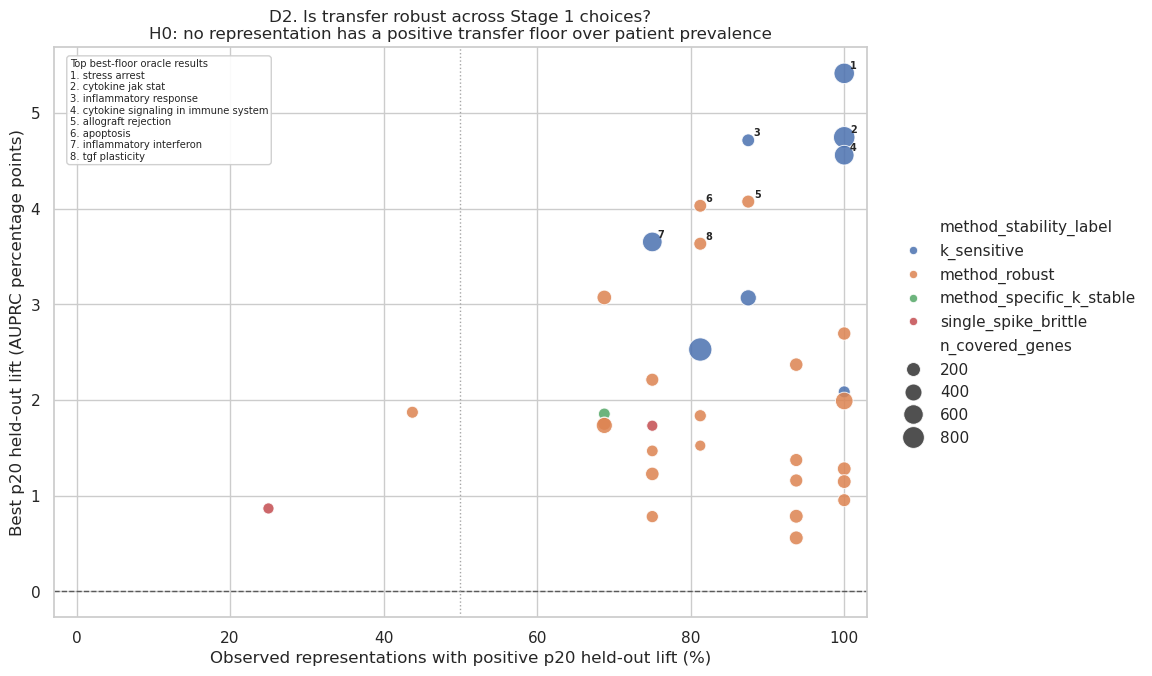

,robust_q1_rank,short_panel_label,n_covered_genes,robust_q1_stage1_method,robust_q1_effective_k,robust_q1_patient_median_lift,robust_q1_patient_p20_lift,frac_representations_positive_p20_lift,method_stability_label,provisional_three_way_taxonomy
0,1,stress arrest,685,factosig_promax,20,0.060580,0.054168,1.0000,k_sensitive,shared_plus_patient_specific_candidate
1,2,cytokine jak stat,775,pca,40,0.098944,0.047480,1.0000,k_sensitive,shared_plus_patient_specific_candidate
2,3,inflammatory response,135,fa,40,0.098847,0.047166,0.8750,k_sensitive,truly_shared_candidate
3,4,cytokine signaling in immune system,616,fa,40,0.081102,0.045613,1.0000,k_sensitive,shared_plus_patient_specific_candidate
4,5,allograft rejection,147,fa,10,0.089437,0.040759,0.8750,method_robust,truly_shared_candidate
5,6,apoptosis,138,fa,10,0.072587,0.040320,0.8125,method_robust,shared_plus_patient_specific_candidate
6,7,inflammatory interferon,613,pca,10,0.043178,0.036541,0.7500,k_sensitive,shared_plus_patient_specific_candidate
7,8,tgf plasticity,146,factosig_promax,40,0.109776,0.036352,0.8125,method_robust,shared_plus_patient_specific_candidate
8,9,interferon signaling,244,pca,40,0.051870,0.030733,0.6875,method_robust,null_or_unresolved
9,10,innate immune context,346,fa,40,0.074861,0.030690,0.8750,k_sensitive,shared_plus_patient_specific_candidate


,n_panels
taxonomy,
shared_plus_patient_specific_candidate,17
truly_shared_candidate,13
null_or_unresolved,7
patient_only_candidate,2
cohort_illusion_candidate,1
hidden_transfer_candidate,1


Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_panel_diagnostic_table.csv
Robust-Q1 selection differs from legacy pooled-LOPO selection for 37 of 41 panels


In [9]:
# Primary Q1 representation: optimize transfer floor, then typical transfer.
selection_sort = [
    "stage0_panel_id",
    "patient_p20_lift",
    "patient_median_lift",
    "median_heldout_auroc",
    "discovery_auprc",
    "representation_id",
]
robust_selected = (
    representation.sort_values(
        selection_sort,
        ascending=[True, False, False, False, False, True],
        na_position="last",
    )
    .drop_duplicates("stage0_panel_id")
)

selected_columns = [
    "stage0_panel_id",
    "stage0_panel_type",
    "short_panel_label",
    "biological_theme",
    "panel_family",
    "panel_scope",
    "n_gene_sets",
    "n_raw_genes",
    "n_covered_genes",
    "n_missing_genes",
    "gene_budget_type",
    "representation_id",
    "stage1_method",
    "effective_k",
    "stage1_seed",
    "selected_stage2_regularization",
    "selected_penalty",
    "selected_C_or_alpha",
    "selected_l1_ratio",
    "selected_regularization_metric",
    "oracle_stage2_regularization",
    "oracle_patient_median_auprc",
    "oracle_patient_median_lift",
    "oracle_patient_p20_lift",
    "discovery_auprc",
    "lopo_auprc",
    "patient_median_auprc",
    "patient_median_lift",
    "patient_p20_lift",
    "median_heldout_auroc",
    "p20_heldout_auroc",
    "n_evaluable_lopo_patients",
    "n_positive_lift_patients",
    "frac_positive_lift_patients",
    "worst_supported_patient_id",
    "worst_supported_patient_auprc",
    "worst_supported_patient_lift",
    "best_supported_patient_id",
    "best_supported_patient_auprc",
    "best_supported_patient_lift",
    "max_patient_specific_patient_id",
    "max_patient_specific_apparent_auprc",
    "paired_gap_patient_id",
    "paired_gap_patient_specific_apparent_auprc",
    "paired_gap_patient_lopo_heldout_auprc",
    "paired_gap_patient_prevalence",
    "paired_patient_specific_gap",
    "max_patient_auprc",
    "patient_specific_gap",
    "decision_quadrant",
]
rename_selected = {
    column: f"robust_q1_{column}"
    for column in selected_columns
    if column
    not in {
        "stage0_panel_id",
        "stage0_panel_type",
        "short_panel_label",
        "biological_theme",
        "panel_family",
        "panel_scope",
        "n_gene_sets",
        "n_raw_genes",
        "n_covered_genes",
        "n_missing_genes",
        "gene_budget_type",
    }
}
panel = robust_selected[selected_columns].rename(columns=rename_selected)

panel_distribution = (
    representation.groupby("stage0_panel_id", dropna=False)
    .agg(
        n_observed_representations=("representation_id", "nunique"),
        n_observed_dr_representations=("stage1_method", lambda values: int(values.ne("direct_gene").sum())),
        n_observed_direct_gene_representations=("stage1_method", lambda values: int(values.eq("direct_gene").sum())),
        frac_representations_positive_median_lift=("patient_median_lift", lambda values: float(values.gt(0).mean())),
        frac_representations_positive_p20_lift=("patient_p20_lift", lambda values: float(values.gt(0).mean())),
        median_representation_median_lift=("patient_median_lift", "median"),
        median_representation_p20_lift=("patient_p20_lift", "median"),
        representation_median_lift_iqr=("patient_median_lift", lambda values: float(values.quantile(0.75) - values.quantile(0.25))),
        representation_p20_lift_iqr=("patient_p20_lift", lambda values: float(values.quantile(0.75) - values.quantile(0.25))),
    )
    .reset_index()
)
panel = panel.merge(panel_distribution, on="stage0_panel_id", how="left", validate="one_to_one")

legacy_best = (
    representation.sort_values(["stage0_panel_id", "lopo_auprc", "representation_id"], ascending=[True, False, True])
    .drop_duplicates("stage0_panel_id")
    [[
        "stage0_panel_id",
        "representation_id",
        "stage1_method",
        "effective_k",
        "lopo_auprc",
        "discovery_auprc",
        "patient_median_auprc",
        "patient_median_lift",
        "patient_p20_lift",
        "median_heldout_auroc",
        "n_positive_lift_patients",
        "frac_positive_lift_patients",
        "max_patient_specific_patient_id",
        "max_patient_auprc",
        "patient_specific_gap",
        "paired_gap_patient_id",
        "paired_gap_patient_specific_apparent_auprc",
        "paired_gap_patient_lopo_heldout_auprc",
        "paired_gap_patient_prevalence",
        "paired_patient_specific_gap",
        "decision_quadrant",
    ]]
    .rename(
        columns={
            "representation_id": "legacy_best_pooled_lopo_representation_id",
            "stage1_method": "legacy_best_pooled_lopo_stage1_method",
            "effective_k": "legacy_best_pooled_lopo_effective_k",
            "lopo_auprc": "legacy_best_pooled_lopo_auprc",
            "discovery_auprc": "legacy_selected_discovery_auprc",
            "patient_median_auprc": "legacy_selected_patient_median_auprc",
            "patient_median_lift": "legacy_selected_patient_median_lift",
            "patient_p20_lift": "legacy_selected_patient_p20_lift",
            "median_heldout_auroc": "legacy_selected_median_heldout_auroc",
            "n_positive_lift_patients": "legacy_selected_n_positive_lift_patients",
            "frac_positive_lift_patients": "legacy_selected_frac_positive_lift_patients",
            "max_patient_specific_patient_id": "legacy_selected_max_patient_specific_patient_id",
            "max_patient_auprc": "legacy_selected_max_patient_auprc",
            "patient_specific_gap": "legacy_selected_patient_specific_gap",
            "paired_gap_patient_id": "legacy_selected_paired_gap_patient_id",
            "paired_gap_patient_specific_apparent_auprc": "legacy_selected_paired_patient_specific_apparent_auprc",
            "paired_gap_patient_lopo_heldout_auprc": "legacy_selected_paired_patient_lopo_heldout_auprc",
            "paired_gap_patient_prevalence": "legacy_selected_paired_patient_prevalence",
            "paired_patient_specific_gap": "legacy_selected_paired_patient_specific_gap",
            "decision_quadrant": "legacy_selected_decision_quadrant",
        }
    )
)
panel = panel.merge(legacy_best, on="stage0_panel_id", how="left", validate="one_to_one")

best_discovery = (
    representation.sort_values(["stage0_panel_id", "discovery_auprc", "representation_id"], ascending=[True, False, True])
    .drop_duplicates("stage0_panel_id")
    [["stage0_panel_id", "representation_id", "discovery_auprc"]]
    .rename(columns={"representation_id": "panel_best_discovery_representation_id", "discovery_auprc": "panel_best_discovery_auprc"})
)
best_patient_specific = (
    representation.sort_values(
        ["stage0_panel_id", "max_patient_auprc", "patient_specific_gap", "representation_id"],
        ascending=[True, False, False, True],
    )
    .drop_duplicates("stage0_panel_id")
    [[
        "stage0_panel_id",
        "representation_id",
        "max_patient_specific_patient_id",
        "max_patient_auprc",
        "patient_specific_gap",
    ]]
    .rename(
        columns={
            "representation_id": "panel_best_patient_specific_representation_id",
            "max_patient_specific_patient_id": "panel_best_patient_specific_patient_id",
            "max_patient_auprc": "panel_max_patient_auprc",
            "patient_specific_gap": "panel_max_patient_specific_gap_at_max_auprc",
        }
    )
)
panel = panel.merge(best_discovery, on="stage0_panel_id", how="left", validate="one_to_one")
panel = panel.merge(best_patient_specific, on="stage0_panel_id", how="left", validate="one_to_one")

stability_columns = [
    "stage0_panel_id",
    "n_methods_available",
    "n_working_methods",
    "n_k_stable_working_methods",
    "n_above_lopo_median_combos",
    "n_shared_candidate_combos",
    "panel_lopo_iqr",
    "best_method_lopo_auprc",
    "median_method_lopo_auprc",
    "method_stability_label",
    "best_lopo_stage1_method",
    "best_lopo_effective_k",
    "best_method_lopo_iqr_across_k",
    "best_method_lopo_range_across_k",
]
panel = panel.merge(
    panel_stability[stability_columns],
    on="stage0_panel_id",
    how="left",
    validate="one_to_one",
)

# Layer-3 taxonomy is deliberately marked provisional: these are deterministic triage rules, not hypothesis tests.
DISCOVERY_HIGH_THRESHOLD = float(representation["discovery_auprc"].median())
PATIENT_SPECIFIC_AUPRC_THRESHOLD = 0.80
PATIENT_SPECIFIC_GAP_THRESHOLD = float(
    panel["legacy_selected_paired_patient_specific_gap"].median()
)
PATIENT_SPECIFIC_GAP_THRESHOLD_RULE = "median paired gap across 41 pooled-LOPO-selected panel representatives"


def provisional_taxonomy(row: pd.Series) -> str:
    broad_shared = row["legacy_selected_patient_p20_lift"] > 0
    partial_shared = row["legacy_selected_patient_median_lift"] > 0
    discovery_high = row["legacy_selected_discovery_auprc"] >= DISCOVERY_HIGH_THRESHOLD
    patient_high = (
        row["legacy_selected_max_patient_auprc"] >= PATIENT_SPECIFIC_AUPRC_THRESHOLD
        and row["legacy_selected_paired_patient_specific_gap"] >= PATIENT_SPECIFIC_GAP_THRESHOLD
    )
    if broad_shared and patient_high:
        return "shared_plus_patient_specific_candidate"
    if broad_shared and discovery_high:
        return "truly_shared_candidate"
    if broad_shared:
        return "hidden_transfer_candidate"
    if patient_high and discovery_high:
        return "cohort_illusion_candidate"
    if patient_high:
        return "patient_only_candidate"
    if partial_shared:
        return "partial_transfer_candidate"
    return "null_or_unresolved"


panel["provisional_three_way_taxonomy"] = panel.apply(provisional_taxonomy, axis=1)
panel["taxonomy_rule_version"] = "old34_provisional_v2_paired_patient_gap"
panel["taxonomy_is_inferential"] = False
panel["taxonomy_representation_selection_rule"] = "max_pooled_lopo_auprc_per_panel"
panel["taxonomy_discovery_high_threshold"] = DISCOVERY_HIGH_THRESHOLD
panel["taxonomy_patient_specific_apparent_auprc_threshold"] = PATIENT_SPECIFIC_AUPRC_THRESHOLD
panel["taxonomy_paired_patient_gap_threshold"] = PATIENT_SPECIFIC_GAP_THRESHOLD
panel["taxonomy_paired_patient_gap_threshold_rule"] = PATIENT_SPECIFIC_GAP_THRESHOLD_RULE
panel["best_floor_selection_is_oracle_sensitivity"] = True
panel["shared_prevalence_null_descriptive_status"] = np.select(
    [
        panel["legacy_selected_patient_p20_lift"].gt(0),
        panel["legacy_selected_patient_median_lift"].gt(0),
    ],
    ["positive_floor", "positive_typical_but_nonpositive_floor"],
    default="nonpositive_typical",
)
panel["interpretability_flag"] = "not_run_layer4"
panel["factor_gene_grounding_status"] = "not_run_layer5"
panel["matched_control_status"] = "blocked_old34_controls_not_in_multiobjective_stage2"
panel["median_enrichment_status"] = "retired_ratio_metric"
panel["robust_vs_legacy_selection_changed"] = panel["robust_q1_representation_id"].ne(
    panel["legacy_best_pooled_lopo_representation_id"]
)
panel["diagnostic_notes"] = np.select(
    [
        panel["legacy_best_pooled_lopo_stage1_method"].eq("direct_gene"),
        panel["method_stability_label"].eq("single_spike_brittle"),
        panel["method_stability_label"].eq("k_sensitive"),
    ],
    ["small-panel direct-gene fallback", "high representation sensitivity", "K-sensitive; retain K in claim"],
    default="",
)
panel["primary_representation_selection_rule"] = "max_pooled_lopo_auprc_per_panel"
panel["best_floor_oracle_selection_rule"] = "max_p20_lift_then_median_lift_then_median_auroc_then_discovery"
panel = panel.sort_values(
    ["robust_q1_patient_p20_lift", "robust_q1_patient_median_lift", "short_panel_label"],
    ascending=[False, False, True],
).reset_index(drop=True)
panel["robust_q1_rank"] = np.arange(1, len(panel) + 1)
panel["best_floor_oracle_rank"] = panel["robust_q1_rank"]
panel["primary_pooled_lopo_rank"] = (
    panel["legacy_best_pooled_lopo_auprc"].rank(method="first", ascending=False).astype(int)
)

assert len(panel) == 41
assert panel["stage0_panel_id"].nunique() == 41
assert panel["robust_q1_representation_id"].nunique() == 41

panel_path = TABLE_DIR / "old34_panel_diagnostic_table.csv"
panel.to_csv(panel_path, index=False)

# D2: attainable transfer floor versus robustness across all representation choices.
d2_plot = panel.copy()
d2_plot["percent_representations_positive_p20_lift"] = (
    100 * d2_plot["frac_representations_positive_p20_lift"]
)
d2_plot["best_p20_lift_percentage_points"] = 100 * d2_plot["robust_q1_patient_p20_lift"]
fig, ax = plt.subplots(figsize=(10.5, 7.4))
sns.scatterplot(
    data=d2_plot,
    x="percent_representations_positive_p20_lift",
    y="best_p20_lift_percentage_points",
    hue="method_stability_label",
    size="n_covered_genes",
    sizes=(55, 280),
    alpha=0.86,
    ax=ax,
)
ax.axhline(0, color="0.35", lw=1, ls="--")
ax.axvline(50, color="0.65", lw=1, ls=":")
ax.set_xlim(-3, 103)
ax.set_xlabel("Observed representations with positive p20 held-out lift (%)")
ax.set_ylabel("Best p20 held-out lift (AUPRC percentage points)")
ax.set_title(
    "D2. Is transfer robust across Stage 1 choices?\n"
    "H0: no representation has a positive transfer floor over patient prevalence"
)
top_floor = d2_plot.nsmallest(8, "best_floor_oracle_rank").copy()
for _, row in top_floor.iterrows():
    ax.annotate(
        str(int(row["best_floor_oracle_rank"])),
        (row["percent_representations_positive_p20_lift"], row["best_p20_lift_percentage_points"]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=7,
        fontweight="bold",
    )
rank_key = "Top best-floor oracle results\n" + "\n".join(
    f"{int(row.best_floor_oracle_rank)}. {row.short_panel_label}" for row in top_floor.itertuples()
)
ax.text(
    0.02,
    0.98,
    rank_key,
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=7.2,
    bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.8", alpha=0.92),
)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
save_figure(fig, "D2_old34_panel_transfer_floor_vs_representation_robustness")
plt.show()

display(
    panel[
        [
            "robust_q1_rank",
            "short_panel_label",
            "n_covered_genes",
            "robust_q1_stage1_method",
            "robust_q1_effective_k",
            "robust_q1_patient_median_lift",
            "robust_q1_patient_p20_lift",
            "frac_representations_positive_p20_lift",
            "method_stability_label",
            "provisional_three_way_taxonomy",
        ]
    ].head(15)
)
display(panel["provisional_three_way_taxonomy"].value_counts().rename_axis("taxonomy").to_frame("n_panels"))
print("Wrote", panel_path)
print("Robust-Q1 selection differs from legacy pooled-LOPO selection for", int(panel["robust_vs_legacy_selection_changed"].sum()), "of 41 panels")

## 4. D3 — three-way triage: shared transfer versus apparent patient-specific opportunity

- **Scientific question:** Does a panel look broadly shared, patient-specific, both, or unresolved?
- **Null hypotheses:** (Q1) patient-summary held-out lift ≤ 0; (Q2 exploratory) fitting a model directly within a patient does not materially exceed that **same patient's** LOPO AUPRC.
- **In silico experiment:** one point per panel using the pre-existing pooled-LOPO-selected representation. x = its p20 held-out lift. y = the largest paired patient-specific gap among the seven supported patients. Point color is the provisional taxonomy; size is the number of supported patients with positive lift.
- **Percentage-point scale:** x = `3` means p20 lift `0.03`; y = `40` means an apparent-within-patient AUPRC 0.40 above that same patient's held-out LOPO AUPRC.
- **Take-home boundary:** the patient-specific model is trained and scored on the same patient's cells (`apparent_within_patient`; within-patient CV was not implemented). The y-axis therefore prioritizes case studies and does not estimate a validated benefit from personalization.

### What exactly is the patient-specific gap?

For each supported patient `h` and the same Stage 0/1 representation:

`paired_gap_h = apparent_within_patient_AUPRC_h - heldout_LOPO_AUPRC_h`

D3 uses the largest `paired_gap_h` and records which patient produced it. This replaces the older, less comparable gap `max apparent patient AUPRC - pooled-cell LOPO AUPRC`, which mixed one patient's apparent fit with a cohort-pooled denominator.

### Provisional taxonomy v2 (hierarchical triage rules)

The rules are applied in order:

1. **`shared_plus_patient_specific_candidate`**: p20 lift > 0 and high paired patient-specific opportunity.
2. **`truly_shared_candidate`**: p20 lift > 0, discovery-high, and not high patient-specific opportunity.
3. **`hidden_transfer_candidate`**: p20 lift > 0 but discovery is below the representation-wide median.
4. **`cohort_illusion_candidate`**: no positive transfer floor, discovery-high, and high paired patient-specific opportunity.
5. **`patient_only_candidate`**: no positive transfer floor, discovery-low, and high paired patient-specific opportunity.
6. **`partial_transfer_candidate`**: median lift > 0 but p20 lift ≤ 0, without a high paired patient-specific flag.
7. **`null_or_unresolved`**: none of the above.

Definitions:

- **discovery-high** = selected discovery AUPRC ≥ the median across all 643 representations;
- **high paired patient-specific opportunity** = apparent within-patient AUPRC ≥ 0.80 and paired gap ≥ the median paired gap across the 41 pooled-LOPO-selected panel representatives;
- every cutoff is descriptive and versioned, not a p-value or manuscript-final threshold.

The generated taxonomy-definition table records the exact numeric thresholds, class counts, interpretation, and caveats.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D3_old34_shared_vs_patient_specific_triage.png


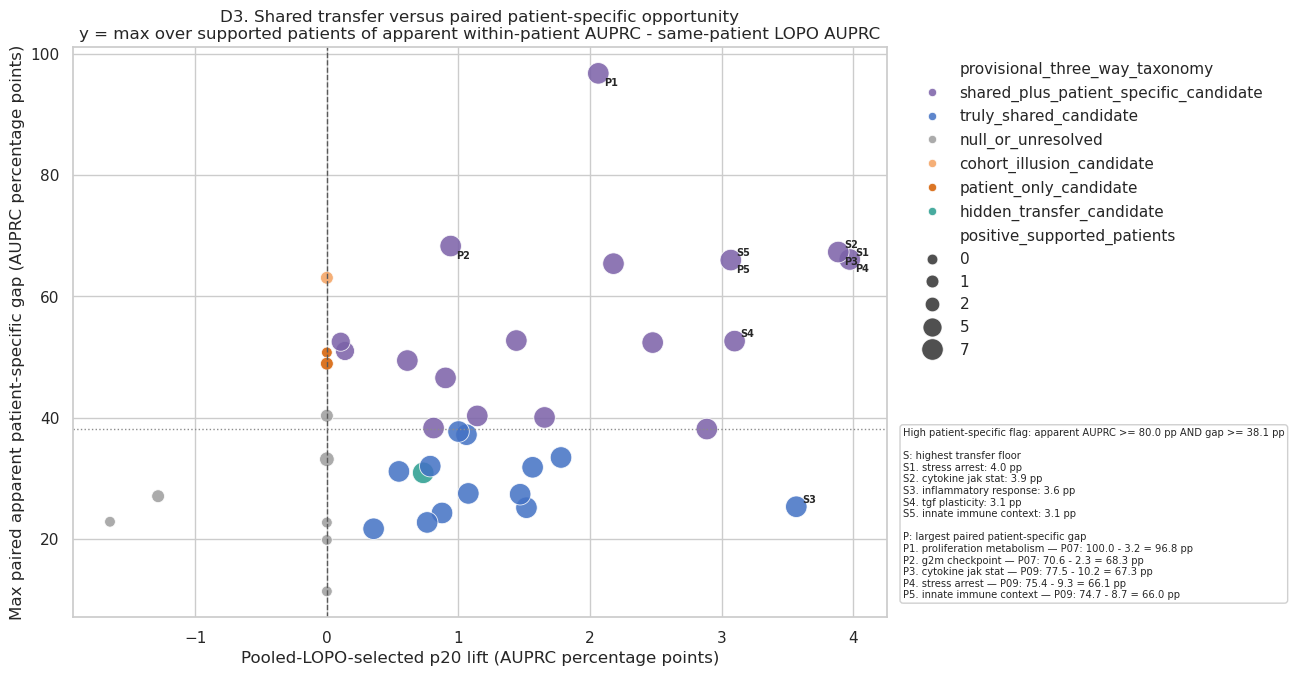

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/D3b_provisional_taxonomy_v2_counts.png


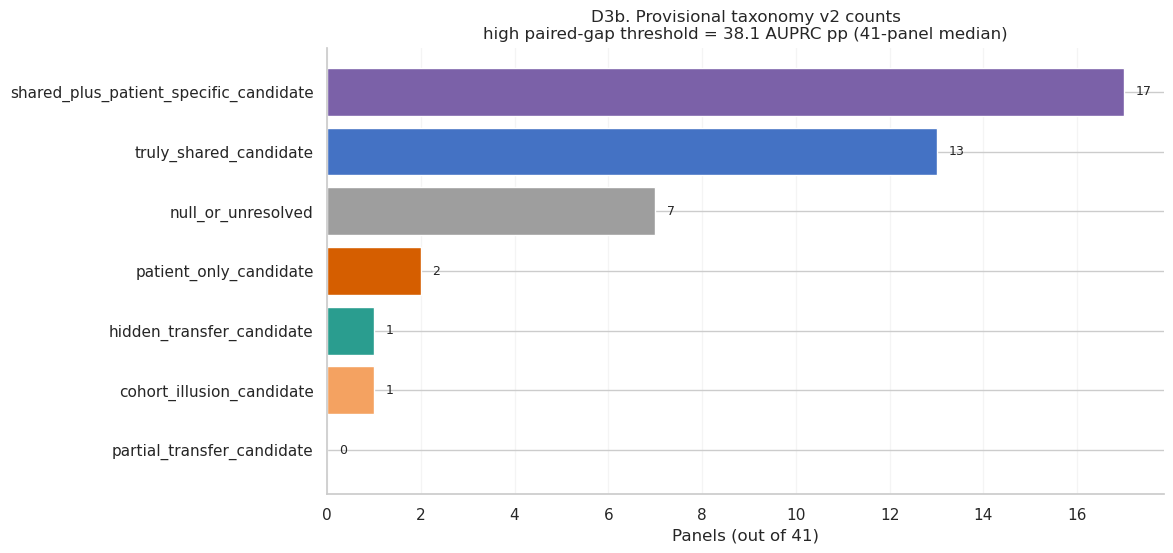

,priority,taxonomy_class,operational_rule,interpretation,current_panel_count,discovery_high_threshold_auprc,patient_specific_apparent_auprc_threshold,paired_patient_gap_threshold_auprc,paired_patient_gap_threshold_rule,inferential,shared_caveat
0,1,shared_plus_patient_specific_candidate,p20 lift > 0 AND high paired patient-specific opportunity,Broad lower-tail transfer plus a large apparent same-patient modeling gap.,17,0.126331,0.8,0.381461,median paired gap across 41 pooled-LOPO-selected panel representatives,False,Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and unc...
1,2,truly_shared_candidate,p20 lift > 0 AND discovery-high AND NOT high patient-specific opportunity,Broad lower-tail transfer without a high apparent personalization flag.,13,0.126331,0.8,0.381461,median paired gap across 41 pooled-LOPO-selected panel representatives,False,Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and unc...
2,3,hidden_transfer_candidate,p20 lift > 0 AND discovery-low AND NOT high patient-specific opportunity,Transfer is visible despite below-median full-cohort apparent fit.,1,0.126331,0.8,0.381461,median paired gap across 41 pooled-LOPO-selected panel representatives,False,Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and unc...
3,4,cohort_illusion_candidate,p20 lift <= 0 AND discovery-high AND high paired patient-specific opportunity,Strong apparent cohort structure without a positive transfer floor; inspect heterogeneity.,1,0.126331,0.8,0.381461,median paired gap across 41 pooled-LOPO-selected panel representatives,False,Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and unc...
4,5,patient_only_candidate,p20 lift <= 0 AND discovery-low AND high paired patient-specific opportunity,"No broad transfer, but one patient's apparent fit greatly exceeds its LOPO fit.",2,0.126331,0.8,0.381461,median paired gap across 41 pooled-LOPO-selected panel representatives,False,Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and unc...
5,6,partial_transfer_candidate,median lift > 0 AND p20 lift <= 0 AND NOT high patient-specific opportunity,"Typical transfer is positive, but the lower tail reaches/breaches prevalence.",0,0.126331,0.8,0.381461,median paired gap across 41 pooled-LOPO-selected panel representatives,False,Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and unc...
6,7,null_or_unresolved,none of the rules above,No current descriptive evidence for broad transfer or a high personalization flag.,7,0.126331,0.8,0.381461,median paired gap across 41 pooled-LOPO-selected panel representatives,False,Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and unc...


Provisional taxonomy counts:
provisional_three_way_taxonomy
cohort_illusion_candidate                  1
hidden_transfer_candidate                  1
null_or_unresolved                         7
patient_only_candidate                     2
shared_plus_patient_specific_candidate    17
truly_shared_candidate                    13


,plot_id,title,result_summary,unresolved_gaps
0,D1,All-representation transfer atlas (41 biological + 6 Stage 0 controls),670/783 representations have positive median lift; 639/783 have positive p20 lift; direct-gene 4...,"No matched-size random-gene null, CI, second seed, or inductive Stage 1 refit."
1,D1c,Per-patient raw AUPRC and lift atlases,"Seven two-panel atlases cover 5,481 representation-patient evaluations (736 DR + 47 direct-gene).",No cell-level CI and no supported inference for low-support or normal-only patients.
2,D1d,Concrete patient-lift calculation example,Worked example median=7.49 pp; p20=3.07 pp.,Chosen only for explanation; it is not a confirmatory estimate.
3,D1e,Patient × Stage 0 lifts: best DR vs direct-gene,Best-DR median lift > 0 in 47/47 panels; direct-gene median lift > 0 in 45/47; best DR > direct ...,Best-DR selection is in-sample on the displayed median-lift metric (winner's curse). D9 uses poo...
4,D2,Panel transfer floor versus representation robustness,"Top transfer-floor panels: stress arrest, cytokine jak stat, inflammatory response, cytokine sig...",The y-axis is a searched maximum and the 50% x-reference is descriptive; no multiplicity correct...
5,D3,Shared versus patient-specific triage,"{""cohort_illusion_candidate"": 1, ""hidden_transfer_candidate"": 1, ""null_or_unresolved"": 7, ""patie...",Patient-specific fit is trained and scored in-sample within patient; taxonomy thresholds are pro...
6,D3b,Provisional taxonomy v2 counts,"{""cohort_illusion_candidate"": 1, ""hidden_transfer_candidate"": 1, ""null_or_unresolved"": 7, ""patie...","Cutoffs are descriptive and must be revisited after uncertainty, controls, and a confirmatory se..."


,artifact_id,path,row_or_cell_unit,n_rows_or_cells,scope
0,representation_diagnostic,analysis/scorecards/stage2_diagnostic/old34_representation_diagnostic_table.csv,one observed representation,643,June 5 grid: 640 DR + 3 small-panel direct-gene fallbacks
1,d1_atlas_representation,analysis/scorecards/stage2_diagnostic/old34_d1_atlas_representation_table.csv,one observed atlas representation,783,640 bio DR + 47 direct-gene + 96 control DR
2,panel_diagnostic,analysis/scorecards/stage2_diagnostic/old34_panel_diagnostic_table.csv,one biological Stage 0 panel,41,41 panels; robust and legacy selections retained
3,supported_patient_representation_metrics,analysis/scorecards/stage2_diagnostic/old34_supported_patient_representation_metrics.csv,one representation x supported patient,4501,"4,501 June-5 fixed-global-regularization LOPO evaluations"
4,d1_atlas_supported_patient_metrics,analysis/scorecards/stage2_diagnostic/old34_d1_atlas_supported_patient_metrics.csv,one atlas representation x supported patient,5481,"5,481 D1c evaluations including 6 Stage 0 controls"
5,paired_patient_specific_vs_lopo,analysis/scorecards/stage2_diagnostic/old34_paired_patient_specific_vs_lopo.csv,one representation x supported patient,4501,apparent within-patient versus same-patient held-out LOPO contrast
6,lift_concrete_example,analysis/scorecards/stage2_diagnostic/old34_lift_concrete_example.csv,one supported patient,7,worked bridge from patient prevalence/AUPRC to median and p20 lift
7,d1e_best_dr_vs_direct_selection,analysis/scorecards/stage2_diagnostic/old34_d1e_best_dr_vs_direct_gene_selection.csv,one Stage 0 panel,47,best-DR config by D1a median lift plus matching direct-gene summaries
8,d1e_best_dr_patient_lift_matrix,analysis/scorecards/stage2_diagnostic/old34_d1e_best_dr_patient_lift_matrix.csv,panel x held-out patient,329,held-out lift for the selected best-DR representation
9,d1e_direct_gene_patient_lift_matrix,analysis/scorecards/stage2_diagnostic/old34_d1e_direct_gene_patient_lift_matrix.csv,panel x held-out patient,329,"held-out lift for the direct-gene representation, including 6 Stage 0 controls"


Wrote /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/old34_plot_contracts.csv


In [10]:
d3_plot = panel.copy()
d3_plot["positive_supported_patients"] = d3_plot["legacy_selected_n_positive_lift_patients"].astype(int)
d3_plot["p20_lift_percentage_points"] = 100 * d3_plot["legacy_selected_patient_p20_lift"]
d3_plot["paired_patient_specific_gap_percentage_points"] = (
    100 * d3_plot["legacy_selected_paired_patient_specific_gap"]
)
taxonomy_palette = {
    "shared_plus_patient_specific_candidate": "#7B61A8",
    "truly_shared_candidate": "#4472C4",
    "hidden_transfer_candidate": "#2A9D8F",
    "partial_transfer_candidate": "#E9C46A",
    "cohort_illusion_candidate": "#F4A261",
    "patient_only_candidate": "#D55E00",
    "null_or_unresolved": "#9E9E9E",
}
fig, ax = plt.subplots(figsize=(10.5, 7.4))
sns.scatterplot(
    data=d3_plot,
    x="p20_lift_percentage_points",
    y="paired_patient_specific_gap_percentage_points",
    hue="provisional_three_way_taxonomy",
    palette=taxonomy_palette,
    size="positive_supported_patients",
    sizes=(60, 240),
    alpha=0.86,
    ax=ax,
)
ax.axvline(0, color="0.35", lw=1, ls="--")
ax.axhline(100 * PATIENT_SPECIFIC_GAP_THRESHOLD, color="0.55", lw=1, ls=":")
ax.set_xlabel("Pooled-LOPO-selected p20 lift (AUPRC percentage points)")
ax.set_ylabel("Max paired apparent patient-specific gap (AUPRC percentage points)")
ax.set_title(
    "D3. Shared transfer versus paired patient-specific opportunity\n"
    "y = max over supported patients of apparent within-patient AUPRC - same-patient LOPO AUPRC"
)
top_shared = d3_plot.nlargest(5, "p20_lift_percentage_points").copy()
top_patient = d3_plot.nlargest(5, "paired_patient_specific_gap_percentage_points").copy()
for rank, row in enumerate(top_shared.itertuples(), start=1):
    ax.annotate(
        f"S{rank}",
        (row.p20_lift_percentage_points, row.paired_patient_specific_gap_percentage_points),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=7,
        fontweight="bold",
    )
for rank, row in enumerate(top_patient.itertuples(), start=1):
    ax.annotate(
        f"P{rank}",
        (row.p20_lift_percentage_points, row.paired_patient_specific_gap_percentage_points),
        xytext=(4, -9),
        textcoords="offset points",
        fontsize=7,
        fontweight="bold",
    )
triage_key = (
    f"High patient-specific flag: apparent AUPRC >= 80.0 pp AND gap >= {100 * PATIENT_SPECIFIC_GAP_THRESHOLD:.1f} pp\n\n"
    + "S: highest transfer floor\n"
    + "\n".join(
        f"S{i}. {row.short_panel_label}: {row.p20_lift_percentage_points:.1f} pp"
        for i, row in enumerate(top_shared.itertuples(), 1)
    )
    + "\n\nP: largest paired patient-specific gap\n"
    + "\n".join(
        f"P{i}. {row.short_panel_label} — {row.legacy_selected_paired_gap_patient_id}: "
        f"{100 * row.legacy_selected_paired_patient_specific_apparent_auprc:.1f} - "
        f"{100 * row.legacy_selected_paired_patient_lopo_heldout_auprc:.1f} = "
        f"{row.paired_patient_specific_gap_percentage_points:.1f} pp"
        for i, row in enumerate(top_patient.itertuples(), 1)
    )
)
ax.text(
    1.02,
    0.03,
    triage_key,
    transform=ax.transAxes,
    va="bottom",
    ha="left",
    fontsize=7.2,
    bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.8", alpha=0.92),
)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
save_figure(fig, "D3_old34_shared_vs_patient_specific_triage")
plt.show()

taxonomy_counts_series = panel["provisional_three_way_taxonomy"].value_counts().sort_index()
taxonomy_rows = [
    (
        1,
        "shared_plus_patient_specific_candidate",
        "p20 lift > 0 AND high paired patient-specific opportunity",
        "Broad lower-tail transfer plus a large apparent same-patient modeling gap.",
    ),
    (
        2,
        "truly_shared_candidate",
        "p20 lift > 0 AND discovery-high AND NOT high patient-specific opportunity",
        "Broad lower-tail transfer without a high apparent personalization flag.",
    ),
    (
        3,
        "hidden_transfer_candidate",
        "p20 lift > 0 AND discovery-low AND NOT high patient-specific opportunity",
        "Transfer is visible despite below-median full-cohort apparent fit.",
    ),
    (
        6,
        "partial_transfer_candidate",
        "median lift > 0 AND p20 lift <= 0 AND NOT high patient-specific opportunity",
        "Typical transfer is positive, but the lower tail reaches/breaches prevalence.",
    ),
    (
        4,
        "cohort_illusion_candidate",
        "p20 lift <= 0 AND discovery-high AND high paired patient-specific opportunity",
        "Strong apparent cohort structure without a positive transfer floor; inspect heterogeneity.",
    ),
    (
        5,
        "patient_only_candidate",
        "p20 lift <= 0 AND discovery-low AND high paired patient-specific opportunity",
        "No broad transfer, but one patient's apparent fit greatly exceeds its LOPO fit.",
    ),
    (
        7,
        "null_or_unresolved",
        "none of the rules above",
        "No current descriptive evidence for broad transfer or a high personalization flag.",
    ),
]
taxonomy_definitions = (
    pd.DataFrame(
        taxonomy_rows,
        columns=["priority", "taxonomy_class", "operational_rule", "interpretation"],
    )
    .sort_values("priority")
    .reset_index(drop=True)
)
taxonomy_definitions["current_panel_count"] = taxonomy_definitions["taxonomy_class"].map(
    taxonomy_counts_series
).fillna(0).astype(int)
taxonomy_definitions["discovery_high_threshold_auprc"] = DISCOVERY_HIGH_THRESHOLD
taxonomy_definitions["patient_specific_apparent_auprc_threshold"] = PATIENT_SPECIFIC_AUPRC_THRESHOLD
taxonomy_definitions["paired_patient_gap_threshold_auprc"] = PATIENT_SPECIFIC_GAP_THRESHOLD
taxonomy_definitions["paired_patient_gap_threshold_rule"] = PATIENT_SPECIFIC_GAP_THRESHOLD_RULE
taxonomy_definitions["inferential"] = False
taxonomy_definitions["shared_caveat"] = (
    "Descriptive triage only; same LOPO folds inform selection/evaluation; matched-size nulls and uncertainty absent."
)
taxonomy_definition_path = TABLE_DIR / "old34_provisional_taxonomy_definitions.csv"
taxonomy_definitions.to_csv(taxonomy_definition_path, index=False)

fig, ax = plt.subplots(figsize=(10.8, 5.8))
count_plot = taxonomy_definitions.sort_values("current_panel_count", ascending=True)
bar_colors = [taxonomy_palette.get(name, "0.6") for name in count_plot["taxonomy_class"]]
ax.barh(count_plot["taxonomy_class"], count_plot["current_panel_count"], color=bar_colors)
for y_pos, count in enumerate(count_plot["current_panel_count"]):
    ax.text(count + 0.25, y_pos, str(int(count)), va="center", fontsize=9)
ax.set_xlabel("Panels (out of 41)")
ax.set_ylabel("")
ax.set_title(
    "D3b. Provisional taxonomy v2 counts\n"
    f"high paired-gap threshold = {100 * PATIENT_SPECIFIC_GAP_THRESHOLD:.1f} AUPRC pp (41-panel median)"
)
ax.grid(axis="x", alpha=0.2)
sns.despine(ax=ax)
save_figure(fig, "D3b_provisional_taxonomy_v2_counts")
d3b_figure_png = FIGURE_DIR / "D3b_provisional_taxonomy_v2_counts.png"
plt.show()

display(taxonomy_definitions)
print("Provisional taxonomy counts:")
print(taxonomy_counts_series.to_string())

top_floor_labels = ", ".join(panel.head(5)["short_panel_label"].tolist())
taxonomy_counts = taxonomy_counts_series.to_dict()
selection_change_count = int(panel["robust_vs_legacy_selection_changed"].sum())

# D1d helper keeps these locals; recover them for the contract table.
example_patient_path = TABLE_DIR / "old34_lift_concrete_example.csv"
if "example_median_lift_pp" not in globals():
    example_median_lift_pp = float(example_patient["lift_percentage_points"].median())
    example_p20_lift_pp = float(example_patient["lift_percentage_points"].quantile(0.20))

plot_contracts = pd.DataFrame(
    [
        {
            "plot_id": "D1",
            "title": "All-representation transfer atlas (41 biological + 6 Stage 0 controls)",
            "verdict": "diagnostic_headline_candidate",
            "scientific_question": "Is transfer encoded broadly by a Stage 0 prior gene space or confined to a lucky Stage 1 method/K?",
            "null_hypothesis": "For each representation, patient-summary median and p20 held-out lift are <= 0.",
            "in_silico_experiment": "640 June-5 biological DR + 41 July-24 biological direct-gene + 96 September-4 control DR + 6 September-11 control direct-gene (full_34, core_only, HVG 500/1k/3k/10k); one global regularization selected by pooled-cell LOPO, then Option-B lift across 7 supported patients.",
            "unit_of_analysis": "representation = Stage 0 panel x Stage 1 method x effective K, or one no-DR gene panel",
            "metric_and_baseline": "median and p20 AUPRC lift; lift = held-out AUPRC - held-out-patient malignant prevalence",
            "source_table": str(atlas_representation_path.relative_to(EXP_DIR)),
            "result_summary": f"{n_median_positive}/{N_D1_ATLAS} representations have positive median lift; {n_floor_positive}/{N_D1_ATLAS} have positive p20 lift; direct-gene {N_D1_DIRECT_GENE}/{N_D1_PANELS} filled ({n_direct_median_positive}/{N_D1_DIRECT_GENE} median>0, {n_direct_floor_positive}/{N_D1_DIRECT_GENE} p20>0); {n_panels_any_floor_positive}/{N_D1_PANELS} panels have at least one p20-positive representation.",
            "take_home_message": "Broad horizontal positive bands support panel-level transfer; isolated cells remain representation-specific evidence.",
            "unresolved_gaps": "No matched-size random-gene null, CI, second seed, or inductive Stage 1 refit.",
        },
        {
            "plot_id": "D1c",
            "title": "Per-patient raw AUPRC and lift atlases",
            "verdict": "diagnostic_supporting",
            "scientific_question": "Which representations transfer to each supported patient, and how much of raw AUPRC is explained by that patient's prevalence?",
            "null_hypothesis": "For a held-out patient and representation, AUPRC does not exceed that patient's malignant prevalence.",
            "in_silico_experiment": "Seven separate patient atlases; all 783 atlas representations evaluated at the globally pooled-LOPO-selected regularization.",
            "unit_of_analysis": "representation x supported held-out patient",
            "metric_and_baseline": "raw held-out AUPRC beside held-out AUPRC minus that patient's malignant prevalence; each patient uses an explicitly labeled patient-specific color range",
            "source_table": str(atlas_supported_patient_path.relative_to(EXP_DIR)),
            "result_summary": "Seven two-panel atlases cover 5,481 representation-patient evaluations (736 DR + 47 direct-gene).",
            "take_home_message": "Patient atlases expose whether a favorable cohort summary is broad or carried by specific held-out patients.",
            "unresolved_gaps": "No cell-level CI and no supported inference for low-support or normal-only patients.",
        },
        {
            "plot_id": "D1d",
            "title": "Concrete patient-lift calculation example",
            "verdict": "methods_explainer",
            "scientific_question": "How do seven patient-specific prevalence-adjusted AUPRC values become median and p20 lift?",
            "null_hypothesis": "Not an inferential panel; zero lift is the descriptive prevalence baseline.",
            "in_silico_experiment": "Use the highest pooled-LOPO-AUPRC representation as a worked example; subtract prevalence per patient, order seven lifts, and mark median/p20.",
            "unit_of_analysis": "supported held-out patient for one example representation",
            "metric_and_baseline": "AUPRC percentage points; p20 uses pandas linear quantile",
            "source_table": str(example_patient_path.relative_to(EXP_DIR)),
            "result_summary": f"Worked example median={example_median_lift_pp:.2f} pp; p20={example_p20_lift_pp:.2f} pp.",
            "take_home_message": "Median describes the typical patient; p20 deliberately reports the lower tail.",
            "unresolved_gaps": "Chosen only for explanation; it is not a confirmatory estimate.",
        },
        {
            "plot_id": "D1e",
            "title": "Patient × Stage 0 lifts: best DR vs direct-gene",
            "verdict": "methods_explainer",
            "scientific_question": "After one global Stage 2 regularizer is frozen per representation, how do the seven patient lifts look when Stage 1 is collapsed to the best-DR cell versus the direct-gene cell?",
            "null_hypothesis": "For each panel and feature family, held-out AUPRC does not exceed patient prevalence; median lift <= 0.",
            "in_silico_experiment": "Same pooled-cell LOPO regularization and Option-B lift as D1. Best DR is the configuration with the highest D1a median lift (ties: p20, configuration). Direct-gene uses the July 24 biological no-DR run plus the September 11 control no-DR run.",
            "unit_of_analysis": "Stage 0 panel × supported held-out patient, one representation per feature family",
            "metric_and_baseline": "held-out AUPRC minus that patient's malignant prevalence, in AUPRC percentage points",
            "source_table": str(d1e_selection_path.relative_to(EXP_DIR)),
            "result_summary": (
                f"Best-DR median lift > 0 in {n_best_dr_median_positive}/{N_D1_PANELS} panels; "
                f"direct-gene median lift > 0 in {n_direct_median_positive}/{n_comparable}; "
                f"best DR > direct on D1a median in {n_best_dr_beats_direct}/{n_comparable} comparable panels."
            ),
            "take_home_message": "The left-row median is the D1a color of the selected DR cell; the right-row median is the D1a direct-gene color. Stage 2 is the same on both sides.",
            "unresolved_gaps": "Best-DR selection is in-sample on the displayed median-lift metric (winner's curse). D9 uses pooled LOPO AP instead. No nested selection, CI, or matched-gene null.",
        },
        {
            "plot_id": "D2",
            "title": "Panel transfer floor versus representation robustness",
            "verdict": "diagnostic_headline_candidate",
            "scientific_question": "Which prior gene spaces retain positive transfer across many Stage 1 choices?",
            "null_hypothesis": "No representation within a panel has p20 held-out lift > 0.",
            "in_silico_experiment": "Collapse all observed representations to 41 panels while retaining the searched maximum p20 lift and fraction of p20-positive configurations.",
            "unit_of_analysis": "Stage 0 biological panel",
            "metric_and_baseline": "best observed p20 held-out lift in AUPRC percentage points and percent p20-positive; zero is patient-prevalence baseline",
            "source_table": str(panel_path.relative_to(EXP_DIR)),
            "result_summary": f"Top transfer-floor panels: {top_floor_labels}. Robust-Q1 and legacy pooled-LOPO selection differ for {selection_change_count}/41 panels.",
            "take_home_message": "Upper-right panels have broad modeling support; upper-left panels are representation-sensitive.",
            "unresolved_gaps": "The y-axis is a searched maximum and the 50% x-reference is descriptive; no multiplicity correction, matched-size null, or uncertainty.",
        },
        {
            "plot_id": "D3",
            "title": "Shared versus patient-specific triage",
            "verdict": "supporting_case_study_triage",
            "scientific_question": "Is panel signal broadly shared, apparently patient-specific, both, or unresolved?",
            "null_hypothesis": "Shared lift <= 0 and no material patient-specific advantage over LOPO.",
            "in_silico_experiment": "One pre-existing pooled-LOPO-selected representation per panel; p20 lift on x and the maximum same-patient apparent-minus-heldout AUPRC gap on y.",
            "unit_of_analysis": "Stage 0 biological panel",
            "metric_and_baseline": "p20 held-out lift versus max_h(apparent within-patient AUPRC_h - heldout LOPO AUPRC_h), both in AUPRC percentage points",
            "source_table": str(panel_path.relative_to(EXP_DIR)),
            "result_summary": json.dumps(taxonomy_counts, sort_keys=True),
            "take_home_message": "Shared and patient-specific signals are not mutually exclusive; patient IDs and both sides of every top gap are shown for case-study triage.",
            "unresolved_gaps": "Patient-specific fit is trained and scored in-sample within patient; taxonomy thresholds are provisional and non-inferential.",
        },
        {
            "plot_id": "D3b",
            "title": "Provisional taxonomy v2 counts",
            "verdict": "diagnostic_supporting",
            "scientific_question": "How do the explicit hierarchical triage rules distribute the 41 panels?",
            "null_hypothesis": "Not an inferential panel; classes are operational triage labels.",
            "in_silico_experiment": "Apply the versioned D3 rules to each pooled-LOPO-selected panel representative and count classes.",
            "unit_of_analysis": "Stage 0 biological panel",
            "metric_and_baseline": "class count plus exact rule and threshold table",
            "source_table": str(taxonomy_definition_path.relative_to(EXP_DIR)),
            "result_summary": json.dumps(taxonomy_counts, sort_keys=True),
            "take_home_message": "The count plot exposes whether conclusions depend on one dominant provisional class.",
            "unresolved_gaps": "Cutoffs are descriptive and must be revisited after uncertainty, controls, and a confirmatory selection policy.",
        },
    ]
)
plot_contracts_path = TABLE_DIR / "old34_plot_contracts.csv"
plot_contracts.to_csv(plot_contracts_path, index=False)

artifact_catalog = pd.DataFrame(
    [
        ("representation_diagnostic", representation_path, "one observed representation", len(representation), "June 5 grid: 640 DR + 3 small-panel direct-gene fallbacks"),
        ("d1_atlas_representation", atlas_representation_path, "one observed atlas representation", len(atlas_representation), "640 bio DR + 47 direct-gene + 96 control DR"),
        ("panel_diagnostic", panel_path, "one biological Stage 0 panel", len(panel), "41 panels; robust and legacy selections retained"),
        ("supported_patient_representation_metrics", supported_patient_path, "one representation x supported patient", len(selected_patient_long), "4,501 June-5 fixed-global-regularization LOPO evaluations"),
        ("d1_atlas_supported_patient_metrics", atlas_supported_patient_path, "one atlas representation x supported patient", len(atlas_selected_patient_long), "5,481 D1c evaluations including 6 Stage 0 controls"),
        ("paired_patient_specific_vs_lopo", paired_patient_specific_path, "one representation x supported patient", len(paired_patient_specific), "apparent within-patient versus same-patient held-out LOPO contrast"),
        ("lift_concrete_example", example_patient_path, "one supported patient", len(example_patient), "worked bridge from patient prevalence/AUPRC to median and p20 lift"),
        ("d1e_best_dr_vs_direct_selection", d1e_selection_path, "one Stage 0 panel", len(selection_table), "best-DR config by D1a median lift plus matching direct-gene summaries"),
        ("d1e_best_dr_patient_lift_matrix", best_dr_matrix_path, "panel x held-out patient", best_dr_matrix.size, "held-out lift for the selected best-DR representation"),
        ("d1e_direct_gene_patient_lift_matrix", direct_matrix_path, "panel x held-out patient", direct_matrix.size, "held-out lift for the direct-gene representation, including 6 Stage 0 controls"),
        ("taxonomy_definitions", taxonomy_definition_path, "one operational taxonomy class", len(taxonomy_definitions), "versioned rules, thresholds, counts, interpretation, and caveats"),
        ("coverage_matrix", TABLE_DIR / "old34_representation_coverage_matrix.csv", "panel x expected configuration", coverage_matrix.size, "1 observed; 0 structurally unavailable"),
        ("D1_median_matrix", TABLE_DIR / "old34_all_representation_patient_median_lift_matrix.csv", "panel x configuration", median_matrix.size, "all observed median-lift values; NaN unavailable"),
        ("D1_p20_matrix", TABLE_DIR / "old34_all_representation_patient_p20_lift_matrix.csv", "panel x configuration", p20_matrix.size, "all observed p20-lift values; NaN unavailable"),
        ("plot_contracts", plot_contracts_path, "one plot", len(plot_contracts), "Section-10 framing and result summaries"),
    ],
    columns=["artifact_id", "path", "row_or_cell_unit", "n_rows_or_cells", "scope"],
)
artifact_catalog["path"] = artifact_catalog["path"].map(lambda path: str(Path(path).relative_to(EXP_DIR)))
artifact_catalog.to_csv(TABLE_DIR / "old34_diagnostic_artifact_catalog.csv", index=False)

display(plot_contracts[["plot_id", "title", "result_summary", "unresolved_gaps"]])
display(artifact_catalog)
print("Wrote", plot_contracts_path)


In [11]:
import shutil

# Final reproducibility, comprehensive artifact ledger, and storage guardrails.
illustration_prompt_path = (
    REPO_ROOT
    / "scripts"
    / "mrd_stage0_2"
    / "notebooks"
    / "stage0_2"
    / "old34_heldout_lift_illustration_prompt.md"
)
written_tables = [
    representation_path,
    atlas_representation_path,
    panel_path,
    supported_patient_path,
    atlas_supported_patient_path,
    paired_patient_specific_path,
    example_patient_path,
    taxonomy_definition_path,
    TABLE_DIR / "old34_representation_coverage_matrix.csv",
    TABLE_DIR / "old34_all_representation_patient_median_lift_matrix.csv",
    TABLE_DIR / "old34_all_representation_patient_p20_lift_matrix.csv",
    d1e_selection_path,
    best_dr_matrix_path,
    direct_matrix_path,
    TABLE_DIR / "old34_v2f_coverage_audit.csv",
    TABLE_DIR / "old34_plot_contracts.csv",
    TABLE_DIR / "old34_diagnostic_artifact_catalog.csv",
    TABLE_DIR / "old34_diagnostic_manifest.json",
]
figure_pngs = [
    FIGURE_DIR / "D1_old34_all_643_representation_transfer_atlas.png",
    *per_patient_figure_pngs,
    d1d_figure_png,
    d1e_figure_png,
    FIGURE_DIR / "D2_old34_panel_transfer_floor_vs_representation_robustness.png",
    FIGURE_DIR / "D3_old34_shared_vs_patient_specific_triage.png",
    d3b_figure_png,
]
written_figures = [
    path
    for png_path in figure_pngs
    for path in (png_path, png_path.with_suffix(".pdf"))
]
tracked_artifacts = list(dict.fromkeys(written_tables + written_figures + [illustration_prompt_path]))
for path in tracked_artifacts:
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty output: {path}"

roundtrip_representation = pd.read_csv(representation_path, low_memory=False)
roundtrip_panel = pd.read_csv(panel_path, low_memory=False)
roundtrip_supported = pd.read_csv(supported_patient_path, low_memory=False)
roundtrip_paired = pd.read_csv(paired_patient_specific_path, low_memory=False)
roundtrip_taxonomy = pd.read_csv(taxonomy_definition_path, low_memory=False)
assert len(roundtrip_representation) == 643
assert roundtrip_representation["representation_id"].nunique() == 643
assert roundtrip_representation["panel_label_with_genes"].str.contains(r" \(\d+\)$").all()
assert len(roundtrip_panel) == 41
assert roundtrip_panel["stage0_panel_id"].nunique() == 41
assert roundtrip_panel["robust_q1_rank"].tolist() == list(range(1, 42))
assert roundtrip_panel["legacy_selected_paired_gap_patient_id"].notna().all()
assert len(roundtrip_supported) == 643 * 7
assert roundtrip_supported["heldout_patient"].nunique() == 7
roundtrip_atlas = pd.read_csv(atlas_representation_path, low_memory=False)
roundtrip_atlas_patients = pd.read_csv(atlas_supported_patient_path, low_memory=False)
assert len(roundtrip_atlas) == N_D1_ATLAS
assert roundtrip_atlas["configuration"].eq("direct_gene").sum() == N_D1_DIRECT_GENE
assert roundtrip_atlas["atlas_row_block"].eq("non_geneset_control").sum() == (
    N_CONTROL_DR + N_CONTROL_DIRECT_GENE
)
assert roundtrip_atlas["stage0_panel_id"].nunique() == N_D1_PANELS
assert len(roundtrip_atlas_patients) == N_D1_ATLAS * 7
assert len(roundtrip_paired) == 643 * 7
assert roundtrip_paired["patient_id"].nunique() == 7
assert roundtrip_taxonomy["current_panel_count"].sum() == 41
assert len(per_patient_figure_pngs) == 7

ledger_records = []
for path in tracked_artifacts:
    try:
        relative_path = str(path.relative_to(EXP_DIR))
        path_base = "experiment_dir"
    except ValueError:
        relative_path = str(path.relative_to(REPO_ROOT))
        path_base = "repo_root"
    suffix = path.suffix.lower()
    if suffix == ".csv":
        artifact_type = "table"
        n_rows = len(pd.read_csv(path, low_memory=False))
    elif suffix in {".png", ".pdf"}:
        artifact_type = "figure"
        n_rows = np.nan
    elif suffix == ".json":
        artifact_type = "manifest_or_validation"
        n_rows = np.nan
    elif suffix == ".md":
        artifact_type = "documentation_prompt"
        n_rows = np.nan
    else:
        artifact_type = "other"
        n_rows = np.nan
    ledger_records.append(
        {
            "artifact_id": path.stem,
            "artifact_type": artifact_type,
            "path_base": path_base,
            "relative_path": relative_path,
            "extension": suffix,
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "n_rows_if_csv": n_rows,
            "modified_utc": datetime.fromtimestamp(path.stat().st_mtime, timezone.utc).isoformat(),
        }
    )
artifact_ledger = pd.DataFrame(ledger_records).sort_values(
    ["artifact_type", "relative_path"]
).reset_index(drop=True)
artifact_ledger_path = TABLE_DIR / "old34_generated_artifact_ledger.csv"
artifact_ledger.to_csv(artifact_ledger_path, index=False)
assert len(artifact_ledger) == len(tracked_artifacts)
assert not artifact_ledger["relative_path"].duplicated().any()

tracked_output_bytes = int(artifact_ledger["size_bytes"].sum())
disk = shutil.disk_usage(EXP_DIR)
free_gib = disk.free / 1024**3
filesystem_used_fraction = disk.used / disk.total
heavy_run_allowed = free_gib >= 50 and filesystem_used_fraction <= 0.90
validation_report = {
    "validated_utc": datetime.now(timezone.utc).isoformat(),
    "status": "pass",
    "representation_rows": len(roundtrip_representation),
    "panel_rows": len(roundtrip_panel),
    "supported_representation_patient_rows": len(roundtrip_supported),
    "paired_patient_specific_rows": len(roundtrip_paired),
    "supported_patient_count": roundtrip_supported["heldout_patient"].nunique(),
    "taxonomy_class_count": len(roundtrip_taxonomy),
    "tracked_artifact_count_excluding_ledger_and_validation": len(artifact_ledger),
    "tracked_figure_file_count": int((artifact_ledger["artifact_type"] == "figure").sum()),
    "tracked_table_file_count": int((artifact_ledger["artifact_type"] == "table").sum()),
    "tracked_output_bytes_excluding_ledger_and_validation": tracked_output_bytes,
    "artifact_ledger": str(artifact_ledger_path.relative_to(EXP_DIR)),
    "filesystem_free_gib": free_gib,
    "filesystem_used_fraction": filesystem_used_fraction,
    "heavy_run_minimum_free_gib": 50,
    "heavy_run_allowed": heavy_run_allowed,
    "notes": [
        "Ledger and validation files exclude themselves from checksum accounting to avoid recursive hashes.",
        "This guardrail applies to new heavy model runs, not this compact derived analysis.",
        "A run-specific projected-output estimate can require more than 50 GiB free.",
        "No source experiment artifact was copied or deleted.",
    ],
}
validation_path = TABLE_DIR / "old34_diagnostic_validation.json"
validation_path.write_text(json.dumps(validation_report, indent=2) + "\n")
assert artifact_ledger_path.stat().st_size > 0
assert validation_path.stat().st_size > 0
all_generated_bytes = (
    tracked_output_bytes + artifact_ledger_path.stat().st_size + validation_path.stat().st_size
)

print("Validation: PASS")
print(
    f"Tracked artifacts: {len(artifact_ledger) + 2} files including ledger + validation; "
    f"{all_generated_bytes / 1024**2:.1f} MiB"
)
print(f"Filesystem free: {free_gib:.1f} GiB ({filesystem_used_fraction:.1%} used)")
print(f"Heavy-run storage guardrail: {'PASS' if heavy_run_allowed else 'BLOCKED'}")


Validation: PASS
Tracked artifacts: 47 files including ledger + validation; 12.2 MiB
Filesystem free: 382.4 GiB (51.4% used)
Heavy-run storage guardrail: PASS


## 5. Handoff and next review gates

### What is now canonical

- `old34_representation_diagnostic_table.csv`: June 5 grid, 643 completed biological representations (640 DR + 3 small-panel fallbacks), with fixed-global-regularization Option-B AUPRC/lift and D2/D3 pairing fields.
- `old34_d1_atlas_representation_table.csv`: D1 universe, 783 rows (640 biological DR + 41 biological direct-gene + 96 control DR + 6 control direct-gene). The `direct_gene` column is 47/47.
- `old34_panel_diagnostic_table.csv`: 41 panels, primary pooled-LOPO selection, best-floor oracle sensitivity, panel-wide robustness, method stability, provisional Layer-3 taxonomy v2, and the patient plus both AUPRC values behind every paired gap.
- `old34_supported_patient_representation_metrics.csv`: all 4,501 June-5 representation × supported-patient LOPO evaluations used by D2/D3 pairing.
- `old34_d1_atlas_supported_patient_metrics.csv`: all 5,481 D1c evaluations (736 DR + 47 direct-gene).
- `old34_paired_patient_specific_vs_lopo.csv`: all 4,501 same-representation, same-patient apparent-versus-heldout contrasts used to define the corrected D3 y-axis.
- `old34_provisional_taxonomy_definitions.csv`: ordered rules, numeric thresholds, current counts, interpretation, and caveats.
- `old34_plot_contracts.csv`: Section-10 framing, result summaries, and unresolved gaps for D1a/b, D1c, D1d, D1e, D2, D3, and D3b.
- `old34_d1e_best_dr_vs_direct_gene_selection.csv`: one best-DR configuration per Stage 0 panel (max D1a median lift) and the matching direct-gene median/p20 lifts.
- `old34_d1f_*_patient_count_matrix.csv` and `old34_d1f_patient_threshold_guide.csv`: D1f discrete patient-count atlases (lift and AUPRC/prevalence-ratio cutoffs).
- `old34_generated_artifact_ledger.csv`: paths, byte sizes, checksums, and row counts for every generated artifact except the self-referential ledger and validation records.
- `old34_diagnostic_manifest.json`: source paths, checksums, selection rules, and expected counts.

### What is not yet evidence-complete

- `provisional_three_way_taxonomy` is triage, not inference.
- The corrected paired gap is more interpretable than the old mixed-patient/cohort gap, but the patient-specific side is still trained and scored on the same cells; it is not a validated personalization gain.
- `interpretability_flag` and factor→gene grounding remain unbuilt.
- old34 controls now sit on the D1 atlas with both DR and no-DR columns (`full_34`, `core_only`, HVG 500/1k/3k/10k). They still lack matched-size random-gene nulls and D2/D3 pairing. HVG 200 and the 15,560-gene filtered universe were never run through this Stage 2 grid.
- no matched-random-gene null, confidence interval, second Stage 1 seed, or inductive refit exists.

### Recommended autonomous sequence

1. **Human plot gate:** review D1a/b, seven D1c patient atlases, D1d, D1e (best DR vs direct-gene patient × Stage 0), D1f (patient-count atlases at lift and ratio cutoffs), D2, D3, and D3b; decide which views answer the scientific questions clearly.
2. **Layer 4:** build sparse-near-best and coefficient-stability audits for all 643 rows; add flags to the same 41-row table.
3. **Layer 5:** ground factors to genes for 10–15 panels sampled across taxonomy/stability classes, not merely the top AUPRC panels.
4. **Storage + compute gate:** only then decide whether to run matched random-gene nulls, second seeds, or inductive sensitivity. The six old34 control panels already have DR + no-DR LOPO on D1; do not relaunch those grids.
5. **Expanded Set B:** port the same contracts to the 294 multi-objective representations actually available; do not describe that branch as a full 632-panel multi-objective grid.

### Autonomy boundary

Analysis engineering, data audits, derived tables, plots, validation, and reversible defaults can proceed autonomously. Human decisions are required for manuscript verdicts, confirmatory thresholds, destructive storage cleanup, and launching expensive new runs.

### Storage guardrail

This notebook writes only compact derived artifacts. The final validation cell records current free space and reports whether the ≥50 GiB free / ≤90% used heavy-run guardrail passes. A specific run can still require a larger projected-output reserve. Preserve expanded Stage 1 artifacts because Layer 5 and Set B analysis need them; prefer cache cleanup and verified duplicate/run-snapshot removal first.
